# Phase-Guided Complex Masking (PCM) for iris recognition — CASIA-Iris-Thousand in Google Drive, identities are NAMES
Run the cells top to bottom (**Runtime → Run all** works). First: Runtime → Change runtime type → **GPU** (T4 is enough with `P=16, K=4`).

**Your dataset:** the *folder* `MyDrive/CASIA-Iris-Thousand/` with one sub-folder per person (`Aarav_Bansal`, `Aarav_Chauhan`, …). It is **not** a zip — the notebook reads the folder directly.

### What was wrong in the previous notebook, and what is fixed
| Problem | Cause (found in the notebook and in its saved outputs) | Fix |
|---|---|---|
| **Drive dataset could not be read** | The config cell looked for `IITD_database_Renamed` and for a *zip* of it in `/content` and `MyDrive`. Your data is the folder `MyDrive/CASIA-Iris-Thousand`, so nothing was found and the notebook had to be run with demo data. | `DRIVE_DATASET_DIR` points at the real folder. The cell mounts Drive, finds the folder (also if it is one level deeper), **copies the images to the fast local disk** (parallel, with retries, resumable) and checks that every file arrived. No unzipping anywhere. |
| **Sample (demo) data and old segmented data were used in later cells** | The saved outputs show the notebook had been run on the 20 *fake* people of `demo_raw`. `normalized/`, `data/` and `runs/main/` from that run still existed, and the preprocess cell skipped itself because `data/train` existed — so later cells (training, evaluation, matching demo, gallery, web app) silently used the sample data. | Every build is stamped with a fingerprint of the exact raw images + split settings. If anything differs (other dataset, other split, demo ↔ real) `normalized/`, `data/` **and the old `runs/main`** are deleted and rebuilt. `train.py` additionally refuses to resume a checkpoint that was trained on different images. A coverage report shows people → usable people → people in training. |
| **Validation/test could crash or be meaningless with the image split** | With ~10 photos per eye the old 60/10/30 split gave only **1** validation image per eye → no genuine pair → `evaluate.py` raises. | Every eye keeps **≥ 2** images in val and in test; everything else is training data. Eyes with too few images are used for training only. |
| **"Is every person trained?"** | – | `SPLIT_BY="image"`: **every person and both eyes are in `data/train`**. The report checks it. Optional section 8b trains a final model on **100 % of the images**. |
| Identification test was not honest for the image split | Gallery and queries came from the same split. | Gallery = `data/train`, queries = held-out `data/val` / `data/test` images; the "unknown person" threshold is calibrated on val and fixed for test. |
| Colab disconnects lose hours of training | – | `train.py` writes a full snapshot each epoch to Drive and **resumes automatically** when you run the cell again (only if data + settings are identical). |
| Download cell tried to zip the whole working folder (`data/`, `normalized/` = tens of thousands of PNGs) | – | Only results (runs, figures, QC, manifests) are zipped. |
| Gallery could run out of RAM with ~20 000 templates; query file name `01.jpg` could hide other people's images | – | Features stored in fp16; "ignore the query's own copy" now matches person + eye + file name. |
| Eye side not detected for CASIA-style names | – | `_L/_R`, `_L_03`, `S5001L02` and `L/` `R/` sub-folders are all understood. Large photos get a second segmentation attempt at half resolution. |

Everything else (complex network, PCM, losses, evaluation, fusion, ablations, web app) is unchanged. The network never sees a name: it learns an embedding, names are attached when people are **enrolled** in a gallery, so renaming folders cannot break it and new people can be added without retraining.


## 1. Setup

In [1]:
import os, sys, subprocess, shutil, json
IN_COLAB = "google.colab" in sys.modules
WORK_DIR = "/content/pcm_iris" if IN_COLAB else os.path.abspath("pcm_iris")
os.makedirs(WORK_DIR, exist_ok=True)
os.chdir(WORK_DIR)
if WORK_DIR not in sys.path:
    sys.path.insert(0, WORK_DIR)
PY = sys.executable

import torch, cv2
print("torch", torch.__version__, "| opencv", cv2.__version__, "| python", sys.version.split()[0])
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else "none - use Runtime > Change runtime type > GPU for real training")
print("working dir:", WORK_DIR)


def run(script, *args):
    """Run a pipeline script, stream its output, and STOP the notebook if it fails."""
    cmd = [PY, "-u", script, *[str(a) for a in args]]
    print("$ python", " ".join(cmd[2:]), flush=True)
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line, end="", flush=True)
    if p.wait() != 0:
        raise RuntimeError(f"{script} failed with exit code {p.returncode} - see the output above")

torch 2.11.0+cu130 | opencv 4.14.0 | python 3.13.16
GPU: Tesla T4
working dir: /content/pcm_iris


### Write the source files

In [2]:
%%writefile complex_layers.py
"""Step 4 - Complex-valued building blocks.

Convention: a complex tensor with C complex channels is stored as a real tensor of
shape (B, 2C, H, W) with channels [real_0..real_{C-1}, imag_0..imag_{C-1}].
"""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


def split(x):
    c = x.shape[1] // 2
    return x[:, :c], x[:, c:]


def merge(r, i):
    return torch.cat([r, i], dim=1)


def cat_complex(xs):
    rs, is_ = zip(*[split(x) for x in xs])
    return merge(torch.cat(rs, 1), torch.cat(is_, 1))


class ComplexConv2d(nn.Module):
    """(A+iB)*(x+iy) = (A*x - B*y) + i(B*x + A*y), done as ONE real convolution."""

    def __init__(self, in_c, out_c, k, stride=1, padding=0, bias=False):
        super().__init__()
        self.stride, self.padding = stride, padding
        std = 1.0 / math.sqrt(in_c * k * k)
        self.wr = nn.Parameter(torch.randn(out_c, in_c, k, k) * std)
        self.wi = nn.Parameter(torch.randn(out_c, in_c, k, k) * std)
        self.bias = nn.Parameter(torch.zeros(2 * out_c)) if bias else None

    def forward(self, x):
        w = torch.cat([torch.cat([self.wr, -self.wi], 1),
                       torch.cat([self.wi, self.wr], 1)], 0)
        return F.conv2d(x, w, self.bias, self.stride, self.padding)


class ComplexBatchNorm2d(nn.Module):
    """Whitens each complex channel with its 2x2 (real, imag) covariance matrix."""

    def __init__(self, c, momentum=0.1, eps=1e-5):
        super().__init__()
        self.c, self.momentum, self.eps = c, momentum, eps
        self.gamma_rr = nn.Parameter(torch.full((c,), 1 / math.sqrt(2)))
        self.gamma_ii = nn.Parameter(torch.full((c,), 1 / math.sqrt(2)))
        self.gamma_ri = nn.Parameter(torch.zeros(c))
        self.beta_r = nn.Parameter(torch.zeros(c))
        self.beta_i = nn.Parameter(torch.zeros(c))
        self.register_buffer("mean_r", torch.zeros(c))
        self.register_buffer("mean_i", torch.zeros(c))
        self.register_buffer("v_rr", torch.full((c,), 1 / math.sqrt(2)))
        self.register_buffer("v_ii", torch.full((c,), 1 / math.sqrt(2)))
        self.register_buffer("v_ri", torch.zeros(c))

    def forward(self, x):
        xr, xi = split(x)
        v = lambda t: t.view(1, -1, 1, 1)
        if self.training:
            mr, mi = xr.mean((0, 2, 3)), xi.mean((0, 2, 3))
            cr, ci = xr - v(mr), xi - v(mi)
            vrr = (cr * cr).mean((0, 2, 3)) + self.eps
            vii = (ci * ci).mean((0, 2, 3)) + self.eps
            vri = (cr * ci).mean((0, 2, 3))
            with torch.no_grad():
                m = self.momentum
                for buf, new in [(self.mean_r, mr), (self.mean_i, mi), (self.v_rr, vrr),
                                 (self.v_ii, vii), (self.v_ri, vri)]:
                    buf.mul_(1 - m).add_(new.detach() * m)
        else:
            mr, mi, vrr, vii, vri = self.mean_r, self.mean_i, self.v_rr, self.v_ii, self.v_ri
            cr, ci = xr - v(mr), xi - v(mi)
        # inverse square root of [[vrr, vri],[vri, vii]] in closed form
        det = vrr * vii - vri ** 2
        s = torch.sqrt(det.clamp_min(1e-12))
        t = torch.sqrt((vrr + vii + 2 * s).clamp_min(1e-12))
        inv = 1.0 / (s * t)
        irr, iii, iri = (vii + s) * inv, (vrr + s) * inv, -vri * inv
        wr = v(irr) * cr + v(iri) * ci
        wi = v(iri) * cr + v(iii) * ci
        outr = v(self.gamma_rr) * wr + v(self.gamma_ri) * wi + v(self.beta_r)
        outi = v(self.gamma_ri) * wr + v(self.gamma_ii) * wi + v(self.beta_i)
        return merge(outr, outi)


class ModReLU(nn.Module):
    """z * relu(|z| + b) / |z|  -> thresholds the magnitude, KEEPS the phase."""

    def __init__(self, c, init_b=-0.3):
        super().__init__()
        self.b = nn.Parameter(torch.full((1, c, 1, 1), init_b))

    def forward(self, x):
        r, i = split(x)
        mag = torch.sqrt(r * r + i * i + 1e-8)
        scale = F.relu(mag + self.b) / mag
        return merge(r * scale, i * scale)


class CReLU(nn.Module):
    def forward(self, x):
        return F.relu(x)  # ReLU on real and imaginary parts separately


class PhaseReLU(nn.Module):
    """Paper-style: pass z only if arg(z) lies in [0, pi/2] (first quadrant)."""

    def forward(self, x):
        r, i = split(x)
        m = ((r >= 0) & (i >= 0)).to(x.dtype)
        return merge(r * m, i * m)


def make_act(name, c):
    return {"modrelu": lambda: ModReLU(c), "crelu": CReLU, "phase": PhaseReLU}[name]()


class ComplexOps:
    """Factory so the SAME backbone code builds complex or real-valued networks."""

    def __init__(self, act="modrelu"):
        self.act_name = act

    def conv(self, i, o, k, stride=1, padding=0):
        return ComplexConv2d(i, o, k, stride, padding)

    def bn(self, c):
        return ComplexBatchNorm2d(c)

    def act(self, c):
        return make_act(self.act_name, c)

    def pool(self):
        return nn.AvgPool2d(2)  # linear + channel-wise => valid for complex data

    def cat(self, xs):
        return cat_complex(xs)


class RealOps:
    """Real baseline with the same layout: C 'complex' channels == 2C real channels."""

    def conv(self, i, o, k, stride=1, padding=0):
        return nn.Conv2d(2 * i, 2 * o, k, stride, padding, bias=False)

    def bn(self, c):
        return nn.BatchNorm2d(2 * c)

    def act(self, c):
        return nn.ReLU()

    def pool(self):
        return nn.AvgPool2d(2)

    def cat(self, xs):
        return torch.cat(xs, 1)

Overwriting complex_layers.py


In [3]:
%%writefile gabor.py
"""Steps 3 + novelty - Gabor Block and the Phase Confidence Map (PCM)."""
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from complex_layers import split, merge

# 5 wavelengths x 8 orientations = 40 complex filters (as in the ComplexIrisNet paper)
LAMBDAS = (3.0, 4.0, 5.5, 7.5, 10.0)
N_ORIENT = 8


def gabor_kernel(size, lam, theta, sigma, gamma=1.0, psi=0.0):
    """g = exp(-(x'^2 + g^2 y'^2)/(2 s^2)) * exp(i(2 pi x'/lam + psi)), made DC-free."""
    h = size // 2
    y, x = np.mgrid[-h:h + 1, -h:h + 1].astype(np.float64)
    xp = x * math.cos(theta) + y * math.sin(theta)
    yp = -x * math.sin(theta) + y * math.cos(theta)
    env = np.exp(-(xp ** 2 + (gamma * yp) ** 2) / (2 * sigma ** 2))
    carrier = np.exp(1j * (2 * math.pi * xp / lam + psi))
    g = env * carrier
    g = g - env * (g.sum() / env.sum())          # remove DC component
    g = g / np.abs(g).sum()                      # L1 normalise
    return g.real.astype(np.float32), g.imag.astype(np.float32)


def gabor_bank(size=11, lambdas=LAMBDAS, n_orient=N_ORIENT):
    re, im = [], []
    for lam in lambdas:
        for k in range(n_orient):
            r, i = gabor_kernel(size, lam, math.pi * k / n_orient, sigma=max(0.56 * lam, 1.0))
            re.append(r)
            im.append(i)
    return torch.tensor(np.stack(re))[:, None], torch.tensor(np.stack(im))[:, None]  # (M,1,k,k)


class GaborBlock(nn.Module):
    """Real image -> complex feature map (B, 2M, H/stride, W/stride).

    mode='fixed' : Gabor weights frozen.      mode='free': Gabor init, then trained.
    input_mode   : 'complex' | 'mag' (magnitude only) | 'phase' (unit-modulus only)  [ablation]
    """

    def __init__(self, size=11, stride=2, mode="free", input_mode="complex"):
        super().__init__()
        re, im = gabor_bank(size)
        self.M = re.shape[0]
        self.conv = nn.Conv2d(1, 2 * self.M, size, stride, size // 2, bias=False)
        with torch.no_grad():
            self.conv.weight.copy_(torch.cat([re, im], 0))
        self.conv.weight.requires_grad = (mode == "free")
        self.input_mode = input_mode

    def forward(self, x):
        z = self.conv(x)
        r, i = split(z)
        if self.input_mode == "mag":
            r, i = torch.sqrt(r * r + i * i + 1e-8), torch.zeros_like(i)
        elif self.input_mode == "phase":
            mag = torch.sqrt(r * r + i * i + 1e-8)
            r, i = r / mag, i / mag
        return merge(r, i)


class PhaseConfidenceMap(nn.Module):
    """NOVELTY: estimate, per pixel, how trustworthy the Gabor PHASE is.

    Cue 1 - local phase coherence: for a clean texture the phase *increment* between
            neighbouring pixels, arg(z(p) * conj(z(p+d))), is locally consistent. Around
            glare / eyelashes / saturated blobs it is erratic -> low coherence.
    Cue 2 - log magnitude: phase of a near-zero response is unreliable (Daugman).
    A tiny conv net turns the cues into a confidence in [0,1]. Then z' = z * conf:
    only the MAGNITUDE is scaled, the PHASE is untouched.
    """

    def __init__(self, M, hidden=16, k=3):
        super().__init__()
        self.k = k
        self.net = nn.Sequential(
            nn.Conv2d(3 * M, hidden, 3, padding=1), nn.ReLU(),
            nn.Conv2d(hidden, hidden, 3, padding=1), nn.ReLU(),
            nn.Conv2d(hidden, 1, 1))
        nn.init.constant_(self.net[-1].bias, 2.0)    # start near "trust everything" (~0.88)

    @staticmethod
    def _inc(r, i, r2, i2):
        """unit phasor of z * conj(z2)"""
        a, b = r * r2 + i * i2, i * r2 - r * i2
        n = torch.sqrt(a * a + b * b + 1e-8)
        return a / n, b / n

    def cues(self, z):
        r, i = split(z)
        mag = torch.sqrt(r * r + i * i + 1e-8)
        pad = lambda t, p: F.pad(t, p, mode="replicate")
        feats = []
        # horizontal neighbour uses a circular roll: the angular axis of the rubber sheet is periodic
        for (rp, ip) in ((torch.roll(r, -1, 3), torch.roll(i, -1, 3)),                       # horizontal
                         (pad(r[:, :, 1:], (0, 0, 0, 1)), pad(i[:, :, 1:], (0, 0, 0, 1)))):  # vertical
            ur, ui = self._inc(r, i, rp, ip)
            cr = F.avg_pool2d(ur, self.k, 1, self.k // 2, count_include_pad=False)
            ci = F.avg_pool2d(ui, self.k, 1, self.k // 2, count_include_pad=False)
            feats.append(torch.sqrt(cr * cr + ci * ci + 1e-8))
        coh = (feats[0] + feats[1]) / 2                                   # (B,M,H,W) in [0,1]
        lm = torch.log(mag + 1e-3)
        lm = (lm - lm.mean((2, 3), keepdim=True)) / (lm.std((2, 3), keepdim=True) + 1e-4)
        return torch.cat([feats[0], feats[1], lm], 1), coh

    def forward(self, z):
        feats, _ = self.cues(z)
        conf = torch.sigmoid(self.net(feats))          # (B,1,H,W)
        return merge(split(z)[0] * conf, split(z)[1] * conf), conf

Overwriting gabor.py


In [4]:
%%writefile model.py
"""Step 5 - Backbone: Gabor Block -> (Phase Confidence Map) -> Dense/Transition blocks."""
import torch
import torch.nn as nn
import torch.nn.functional as F
from complex_layers import ComplexOps, RealOps
from gabor import GaborBlock, PhaseConfidenceMap


class DenseLayer(nn.Module):
    def __init__(self, ops, in_c, growth, bn_size=4):
        super().__init__()
        self.ops = ops
        mid = bn_size * growth
        self.f = nn.Sequential(ops.bn(in_c), ops.act(in_c), ops.conv(in_c, mid, 1),
                               ops.bn(mid), ops.act(mid), ops.conv(mid, growth, 3, 1, 1))

    def forward(self, x):
        return self.ops.cat([x, self.f(x)])


class Transition(nn.Module):
    def __init__(self, ops, in_c, out_c):
        super().__init__()
        self.f = nn.Sequential(ops.bn(in_c), ops.act(in_c), ops.conv(in_c, out_c, 1), ops.pool())

    def forward(self, x):
        return self.f(x)


class IrisNet(nn.Module):
    """variant: 'complex' | 'real_double' (Gabor re/im as 2M real channels) | 'real_pure' (raw image)
    use_pcm   : enable Phase Confidence Map (novelty)."""

    def __init__(self, variant="complex", act="modrelu", use_pcm=True, gabor_mode="free",
                 input_mode="complex", growth=12, block_layers=(8, 8), compress=0.5):
        super().__init__()
        self.variant = variant
        ops = ComplexOps(act) if variant == "complex" else RealOps()
        if variant == "real_pure":
            use_pcm = False
            self.M = 40
            self.stem = nn.Sequential(nn.Conv2d(1, 80, 11, 2, 5, bias=False))
        else:
            self.stem = GaborBlock(11, 2, gabor_mode, input_mode)
            self.M = self.stem.M
        self.pcm = PhaseConfidenceMap(self.M) if use_pcm else None
        c = self.M
        blocks = []
        for n in block_layers:
            for _ in range(n):
                blocks.append(DenseLayer(ops, c, growth))
                c += growth
            out = int(c * compress)
            blocks.append(Transition(ops, c, out))
            c = out
        self.body = nn.Sequential(*blocks)
        self.out_channels = 2 * c

    def forward(self, x, return_intermediate=False):
        x = (x - x.mean((2, 3), keepdim=True)) / (x.std((2, 3), keepdim=True) + 1e-4)
        z_raw = self.stem(x)
        conf = None
        z = z_raw
        if self.pcm is not None:
            z, conf = self.pcm(z_raw)
        f = self.body(z)
        # RMS-normalise per sample so the distance is scale-free
        f = f / (f.pow(2).mean((1, 2, 3), keepdim=True).sqrt() + 1e-6)
        conf_final = None if conf is None else F.adaptive_avg_pool2d(conf, f.shape[-2:])
        out = {"feat": f, "conf": conf, "conf_final": conf_final}
        if return_intermediate:
            out.update(z_raw=z_raw, z_pcm=z)
        return out


def build_model_from_args(ar):
    """Build IrisNet from a train.py argument dict (also works for checkpoints from the old notebook)."""
    return IrisNet(ar.get("variant", "complex"), ar.get("act", "modrelu"), bool(ar.get("use_pcm", 1)),
                   ar.get("gabor_mode", "free"), ar.get("input_mode", "complex"),
                   growth=int(ar.get("growth", 12)), block_layers=tuple(ar.get("layers", (8, 8))))


def load_checkpoint(path, device="cpu"):
    """Returns (model in eval mode, training-args dict)."""
    ck = torch.load(path, map_location=device, weights_only=False)
    model = build_model_from_args(ck["args"]).to(device)
    model.load_state_dict(ck["state"])
    model.eval()
    return model, ck["args"]

Overwriting model.py


In [5]:
%%writefile losses.py
"""Step 6 - Shift-tolerant, confidence-weighted distance + batch-hard triplet loss."""
import torch
import torch.nn.functional as F

WEIGHT_MODES = ("pcm_hard", "pcm", "hard", "none")


def pairwise_distance(fa, wa, fb, wb, max_shift=4, eps=1e-6, min_overlap=0.05, empty_value=2.0):
    """Weighted mean-squared distance between all pairs (A x B), min over horizontal shifts.

    fa, fb: (N, C, H, W) features      wa, wb: (N, 1, H, W) per-pixel weights in [0,1]
    The weights are the hard mask, the Phase Confidence Map, their product, or all-ones.
    Uses sum w(a-b)^2 = sum w a^2 - 2 sum w a b + sum w b^2 so it is a few matmuls.

    Pairs whose usable overlap is below `min_overlap` (fraction of pixels, weights rescaled so
    each sample's max weight is 1) get `empty_value` (~ the expected impostor distance of
    RMS-normalised features). Without this, a (nearly) fully masked image has distance ~0 to
    EVERY other image and becomes a universal false match.
    """
    C = fa.shape[1]
    P = wa[0].numel()
    wa_f = wa.flatten(1)
    na = wa_f / wa_f.amax(1, keepdim=True).clamp_min(eps)
    nb_full = wb / wb.flatten(1).amax(1).clamp_min(eps).view(-1, 1, 1, 1)
    a2 = (fa ** 2).sum(1).flatten(1)
    a_w = (fa * wa).flatten(1)
    best = None
    for s in range(-max_shift, max_shift + 1):
        fbs, wbs = torch.roll(fb, s, dims=3), torch.roll(wb, s, dims=3)
        wb_f = wbs.flatten(1)
        b2 = (fbs ** 2).sum(1).flatten(1)
        b_w = (fbs * wbs).flatten(1)
        num = (wa_f * a2) @ wb_f.T - 2 * (a_w @ b_w.T) + wa_f @ (wb_f * b2).T
        den = (wa_f @ wb_f.T) * C + eps
        d = (num / den).clamp_min(0)
        overlap = (na @ torch.roll(nb_full, s, dims=3).flatten(1).T) / P
        d = torch.where(overlap < min_overlap, torch.full_like(d, empty_value), d)
        best = d if best is None else torch.minimum(best, d)
    return best


def batch_hard_triplet(feat, w, labels, margin=0.5, max_shift=4):
    D = pairwise_distance(feat, w, feat, w, max_shift)
    same = labels[:, None] == labels[None, :]
    eye = torch.eye(len(labels), dtype=torch.bool, device=feat.device)
    pos = same & ~eye
    neg = ~same
    valid = pos.any(1) & neg.any(1)
    if not valid.any():                       # e.g. K=1 -> no positives; avoid NaN loss
        return feat.sum() * 0.0, D
    d_ap = D.masked_fill(~pos, float("-inf")).max(1).values
    d_an = D.masked_fill(~neg, float("inf")).min(1).values
    return F.relu(d_ap - d_an + margin)[valid].mean(), D


def confidence_aux_loss(conf, mask):
    """Optional supervision of the PCM with a (synthetic or segmentation) valid-pixel mask.
    Set weight to 0 for the fully self-supervised variant."""
    target = F.adaptive_avg_pool2d(mask, conf.shape[-2:])
    return F.binary_cross_entropy(conf.clamp(1e-4, 1 - 1e-4), target)


def pick_weights(out, mask, mode):
    """mode: 'pcm_hard' (PCM x segmentation mask, recommended when masks exist)
           | 'pcm' (no external mask needed) | 'hard' (segmentation mask) | 'none'."""
    f = out["feat"]
    if mode in ("pcm", "pcm_hard"):
        assert out["conf_final"] is not None, "model built with use_pcm=False"
        w = out["conf_final"]
        if mode == "pcm_hard":
            w = w * F.adaptive_avg_pool2d(mask, f.shape[-2:])
        return w
    if mode == "hard":
        return F.adaptive_avg_pool2d(mask, f.shape[-2:])
    if mode == "none":
        return torch.ones(f.shape[0], 1, *f.shape[-2:], device=f.device)
    raise ValueError(f"unknown weight mode {mode!r}; choose from {WEIGHT_MODES}")

Overwriting losses.py


In [6]:
%%writefile data.py
"""Steps 1-2 (data side) - datasets, realistic augmentation, PK sampler.

Folder layout expected by IrisFolder (already rubber-sheet normalised 64x256 images):
    root/<Name>_<eye>/<Name>_01_L.png      optional mask: <Name>_01_L_mask.png
(<Name>_<eye> is one "identity" = one eye of one named person; IrisFolder.ids holds these folder names.)
Split BY PERSON: make three roots (train/ val/ test/) that contain disjoint people (preprocess.py does it).
"""
import glob
import os
import random
import cv2
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, Sampler

H, W = 64, 256
IMG_EXTS = (".png", ".jpg", ".bmp", ".jpeg", ".tif", ".tiff")


def prepare_normalized(img, mask=None, clahe=True):
    """uint8 gray strip (+ optional uint8 mask) -> float32 img in [0,1] and mask in {0,1}, both (H, W).
    The ONE place that defines the network input, shared by training, evaluation, enrolment and inference."""
    img = cv2.resize(img, (W, H), interpolation=cv2.INTER_AREA)
    if clahe:  # local contrast normalisation: removes slow illumination changes, boosts texture
        img = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(2, 8)).apply(img)
    m = (cv2.resize(mask, (W, H), interpolation=cv2.INTER_NEAREST) > 127).astype(np.float32) if mask is not None \
        else np.ones((H, W), np.float32)
    return img.astype(np.float32) / 255.0, m


def load_normalized(path, clahe=True):
    """Load one normalised iris image (+ its mask if present) exactly as the datasets do.
    Returns float32 arrays img in [0,1] and mask in {0,1}, both (H, W)."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(path)
    mp = os.path.splitext(path)[0] + "_mask.png"
    m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE) if os.path.exists(mp) else None
    return prepare_normalized(img, m, clahe)


def _blob(cy, cx, ry, rx, device="cpu"):
    y = torch.arange(H, device=device)[:, None].float()
    x = torch.arange(W, device=device)[None, :].float()
    return torch.exp(-(((y - cy) / ry) ** 2 + ((x - cx) / rx) ** 2))


def augment(img, mask, p_glare=0.5, p_lash=0.5, max_shift=8):
    """img, mask: (1,H,W) in [0,1]. Simulates acquisition / segmentation nuisances.
    Returns img, mask where mask==0 marks the corrupted pixels (usable as PCM supervision)."""
    img, mask = img.clone(), mask.clone()
    s = random.randint(-max_shift, max_shift)                 # eye rotation => circular shift
    img, mask = torch.roll(img, s, 2), torch.roll(mask, s, 2)
    sr = random.randint(-2, 2)                                # small radial error of the segmenter
    if sr:
        img, mask = torch.roll(img, sr, 1), torch.roll(mask, sr, 1)
        if sr > 0:
            mask[:, :sr] = 0
        else:
            mask[:, sr:] = 0
    img = (img - img.mean()) * random.uniform(0.7, 1.3) + img.mean() + random.uniform(-0.1, 0.1)
    if random.random() < 0.5:                                 # non-uniform illumination
        ax = random.choice([1, 2])
        g = torch.linspace(-1, 1, img.shape[ax]) * random.uniform(-0.15, 0.15)
        img = img * (1 + (g[:, None] if ax == 1 else g[None, :]))[None]
    if random.random() < 0.25:                                # mild defocus blur
        img = F.avg_pool2d(F.pad(img[None], (1, 1, 1, 1), mode="replicate"), 3, 1)[0]
    if random.random() < p_glare:                             # specular highlights
        for _ in range(random.randint(1, 3)):
            b = _blob(random.uniform(8, H - 8), random.uniform(0, W), random.uniform(2, 6), random.uniform(3, 14))
            hit = b > 0.35
            img = torch.where(hit[None], torch.ones_like(img), img + 0.3 * b[None])
            mask = torch.where(hit[None], torch.zeros_like(mask), mask)
    if random.random() < p_lash:                              # eyelid band / eyelash streaks
        band = random.choice(["top", "bottom"])
        t = random.randint(4, 16)
        sl = slice(0, t) if band == "top" else slice(H - t, H)
        img[:, sl, :] = img[:, sl, :] * 0.2 + 0.05 * torch.rand_like(img[:, sl, :])
        mask[:, sl, :] = 0
        for _ in range(random.randint(0, 6)):
            x0, w = random.randint(0, W - 4), random.randint(1, 3)
            img[:, :, x0:x0 + w] = img[:, :, x0:x0 + w] * 0.3
            mask[:, :, x0:x0 + w] = 0
    img = img + 0.02 * torch.randn_like(img)
    return img.clamp(0, 1), mask


class IrisFolder(Dataset):
    def __init__(self, root, train=False, p_glare=0.5, p_lash=0.5, clahe=True):
        if not os.path.isdir(root):
            raise FileNotFoundError(f"dataset folder not found: {root}")
        self.train, self.pg, self.pl, self.clahe = train, p_glare, p_lash, clahe
        self.ids = sorted(d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d)))
        self.items, self.labels = [], []
        for k, d in enumerate(self.ids):
            for p in sorted(glob.glob(os.path.join(root, d, "*"))):
                if p.lower().endswith(IMG_EXTS) and "_mask" not in os.path.basename(p):
                    self.items.append(p)
                    self.labels.append(k)
        if not self.items:
            raise RuntimeError(f"no images found under {root}")

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        img, m = load_normalized(self.items[i], self.clahe)
        img, m = torch.from_numpy(img)[None], torch.from_numpy(m)[None]
        if self.train:
            img, m = augment(img, m, self.pg, self.pl)
        return img, m, self.labels[i]


class SyntheticIrisDataset(Dataset):
    """Fake 'irises' (identity-specific band-limited texture) so you can test the whole pipeline
    before real data arrives. NOT for reporting results."""

    def __init__(self, n_ids=40, per_id=8, train=True, seed=0, p_glare=0.5, p_lash=0.5):
        g = torch.Generator().manual_seed(seed)
        self.train, self.pg, self.pl = train, p_glare, p_lash
        self.base = []
        for _ in range(n_ids):
            n = torch.randn(1, 1, H, W, generator=g)
            f = torch.fft.fft2(n)
            fy = torch.fft.fftfreq(H)[:, None]
            fx = torch.fft.fftfreq(W)[None, :]
            band = torch.exp(-((fx ** 2 + fy ** 2).sqrt() - 0.12) ** 2 / (2 * 0.05 ** 2))
            t = torch.fft.ifft2(f * band).real[0, 0]
            self.base.append(((t - t.min()) / (t.max() - t.min())))
        self.labels = [i for i in range(n_ids) for _ in range(per_id)]
        self.noise_seed = seed

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        lab = self.labels[i]
        g = None if self.train else torch.Generator().manual_seed(self.noise_seed * 100003 + i)
        img = self.base[lab].clone() + 0.03 * torch.randn(H, W, generator=g)   # deterministic for eval sets
        img, m = img[None].clamp(0, 1), torch.ones(1, H, W)
        if self.train:
            img, m = augment(img, m, self.pg, self.pl)
        return img, m, lab


class PKBatchSampler(Sampler):
    """P identities x K images per batch (needed for batch-hard triplet mining).
    One epoch has enough batches to visit (on average) every image once, not just every identity."""

    def __init__(self, labels, P=8, K=4, n_batches=None):
        self.by = {}
        for i, l in enumerate(labels):
            self.by.setdefault(l, []).append(i)
        self.ids, self.K = list(self.by), K
        self.P = min(P, len(self.ids))
        if self.P < 2:
            raise ValueError("need at least 2 identities for triplet training")
        self.n = n_batches or max(len(self.ids) // self.P, len(labels) // (self.P * K), 1)

    def __len__(self):
        return self.n

    def __iter__(self):
        for _ in range(self.n):
            batch = []
            for l in random.sample(self.ids, self.P):
                pool = self.by[l]
                batch += random.sample(pool, self.K) if len(pool) >= self.K else random.choices(pool, k=self.K)
            yield batch

Overwriting data.py


In [7]:
%%writefile iriscode.py
"""Baseline - classical IrisCode (Gabor -> phase-quadrant bits -> masked Hamming with shifts).
Exposes the same interface as IrisNet so evaluate.py can score it with the same code.

stride=4 gives 16x64 positions x 80 bits (~82k bits per template): plenty of information and
4x less memory than stride 2, which otherwise runs out of RAM on a full CASIA test split."""
import torch
import torch.nn as nn
import torch.nn.functional as F
from gabor import gabor_bank

DEFAULT_SHIFT = 8   # 8 of 64 columns = same rotation range as 4 of 32 columns for IrisNet


class IrisCode(nn.Module):
    def __init__(self, size=11, stride=4):
        super().__init__()
        re, im = gabor_bank(size)
        self.register_buffer("w", torch.cat([re, im], 0))
        self.size, self.stride = size, stride

    @torch.no_grad()
    def forward(self, x):
        x = (x - x.mean((2, 3), keepdim=True)) / (x.std((2, 3), keepdim=True) + 1e-4)
        z = F.conv2d(x, self.w, stride=self.stride, padding=self.size // 2)
        bits = torch.where(z >= 0, 1.0, -1.0)           # +-1 => (a-b)^2 = 4 * mismatch
        return {"feat": bits, "conf": None, "conf_final": None}

Overwriting iriscode.py


In [8]:
%%writefile evaluate.py
"""Step 8 - Evaluation: EER, FRR@FAR, decision thresholds, DET curve, score fusion.
  python evaluate.py --ckpt runs/main/best.pt --test_root data/val  --out val.json   # calibrate threshold
  python evaluate.py --ckpt runs/main/best.pt --test_root data/test --weight_mode pcm_hard
  python evaluate.py --method iriscode --test_root data/test                         # baseline
  python evaluate.py --method fusion --ckpt runs/main/best.pt --test_root data/test  # net + IrisCode
"""
import argparse, json
import numpy as np
import torch
from torch.utils.data import DataLoader
from losses import pairwise_distance, pick_weights


@torch.no_grad()
def embed(model, ds, dev, weight_mode, bs=64, num_workers=0):
    model.eval()
    F_, Wt, L = [], [], []
    for img, mask, lab in DataLoader(ds, batch_size=bs, num_workers=num_workers):
        out = model(img.to(dev))
        w = pick_weights(out, mask.to(dev), weight_mode)
        F_.append(out["feat"].cpu()); Wt.append(w.cpu()); L.append(torch.as_tensor(lab))
    return torch.cat(F_), torch.cat(Wt), torch.cat(L)


@torch.no_grad()
def score(F_, Wt, L, dev, max_pairs_imp=2_000_000, shift=4, chunk=64, seed=0):
    """Genuine = all same-identity pairs. Impostor = all (or a fixed random subset of) different-identity
    pairs. The order of pairs is deterministic, so scores of two methods on the same dataset align
    pair-by-pair (needed for score fusion)."""
    N = len(L)
    gen, imp = [], []
    Fd, Wd = F_.to(dev), Wt.to(dev)
    for s in range(0, N, chunk):
        D = pairwise_distance(Fd[s:s + chunk], Wd[s:s + chunk], Fd, Wd, shift).cpu()
        idx = torch.arange(s, min(s + chunk, N))[:, None]
        upper = torch.arange(N)[None, :] > idx
        same = L[s:s + chunk, None] == L[None, :]
        gen.append(D[upper & same]); imp.append(D[upper & ~same])
    gen, imp = torch.cat(gen).numpy(), torch.cat(imp).numpy()
    if len(gen) == 0 or len(imp) == 0:
        raise RuntimeError("need >=2 images for some identity and >=2 identities to evaluate")
    if len(imp) > max_pairs_imp:
        sel = np.sort(np.random.default_rng(seed).choice(len(imp), max_pairs_imp, replace=False))
        imp = imp[sel]
    return gen, imp


def det_curve(gen, imp, n=4000):
    """Accept a pair when distance <= t.  FAR(t) = P(imp <= t),  FRR(t) = P(gen > t)."""
    ts = np.unique(np.concatenate([np.quantile(imp, np.logspace(-6, 0, n // 2)),
                                   np.quantile(gen, np.linspace(0, 1, n // 2))]))
    far = np.searchsorted(np.sort(imp), ts, "right") / len(imp)
    frr = 1 - np.searchsorted(np.sort(gen), ts, "right") / len(gen)
    return far, frr, ts


def summarize(gen, imp):
    far, frr, ts = det_curve(gen, imp)
    i = int(np.argmin(np.abs(far - frr)))
    res = {"EER": float((far[i] + frr[i]) / 2), "thr@EER": float(ts[i]),
           "n_genuine": int(len(gen)), "n_impostor": int(len(imp)),
           "genuine_mean": float(gen.mean()), "impostor_mean": float(imp.mean()),
           "d_prime": float(abs(imp.mean() - gen.mean()) / np.sqrt(0.5 * (imp.var() + gen.var()) + 1e-12))}
    for t in (1e-2, 1e-3, 1e-4, 1e-5):
        ok = np.nonzero(far <= t)[0]
        if len(ok) and len(imp) * t >= 10:          # otherwise too few impostor pairs to estimate it
            j = ok[np.argmin(frr[ok])]
            res[f"FRR@FAR={t:g}"], res[f"thr@FAR={t:g}"] = float(frr[j]), float(ts[j])
        else:
            res[f"FRR@FAR={t:g}"], res[f"thr@FAR={t:g}"] = None, None
    return res


def method_scores(model, ds, weight_mode, dev, shift=4, max_pairs_imp=2_000_000, num_workers=0):
    F_, Wt, L = embed(model, ds, dev, weight_mode, num_workers=num_workers)
    return score(F_, Wt, L, dev, max_pairs_imp=max_pairs_imp, shift=shift)


def evaluate_model(model, ds, weight_mode, dev, shift=4, **kw):
    return summarize(*method_scores(model, ds, weight_mode, dev, shift=shift, **kw))


def fuse(score_sets, weights):
    """Score-level fusion: z-normalise each method with label-free statistics (all pairs), then
    take the weighted sum. score_sets: list of (gen, imp) aligned pair-by-pair."""
    gen = np.zeros_like(score_sets[0][0], dtype=np.float64)
    imp = np.zeros_like(score_sets[0][1], dtype=np.float64)
    for (g, i), w in zip(score_sets, weights):
        allp = np.concatenate([g, i])
        mu, sd = allp.mean(), allp.std() + 1e-12
        gen += w * (g - mu) / sd
        imp += w * (i - mu) / sd
    return gen, imp


def plot_det(curves, path):
    import matplotlib; matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    plt.figure(figsize=(5, 4))
    for name, (far, frr) in curves.items():
        plt.loglog(np.clip(far, 1e-7, 1), np.clip(frr, 1e-5, 1), label=name)
    plt.xlabel("FAR"); plt.ylabel("FRR"); plt.grid(True, which="both", alpha=.3); plt.legend(); plt.tight_layout()
    plt.savefig(path, dpi=150); plt.close()


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--ckpt"); ap.add_argument("--test_root"); ap.add_argument("--synthetic", action="store_true")
    ap.add_argument("--method", default="net", choices=["net", "iriscode", "fusion"])
    ap.add_argument("--weight_mode", default=None, help="override: pcm_hard | pcm | hard | none")
    ap.add_argument("--shift", type=int, default=None, help="max horizontal shift (default: from ckpt / 8 for IrisCode)")
    ap.add_argument("--fuse_w", type=float, default=0.5, help="weight of the network score in fusion")
    ap.add_argument("--clahe", type=int, default=None, help="default: same as training (1)")
    ap.add_argument("--max_pairs_imp", type=int, default=2_000_000)
    ap.add_argument("--num_workers", type=int, default=2)
    ap.add_argument("--out", default="eval_result.json"); ap.add_argument("--det", default=None)
    ap.add_argument("--save_scores", default=None, help="write gen/imp scores to this .npz")
    ap.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    a = ap.parse_args(argv)
    from data import IrisFolder, SyntheticIrisDataset
    from iriscode import IrisCode, DEFAULT_SHIFT

    net = ar = None
    if a.method in ("net", "fusion"):
        if not a.ckpt:
            ap.error("--ckpt is required for --method net/fusion")
        from model import load_checkpoint
        net, ar = load_checkpoint(a.ckpt, a.device)
    # checkpoints from the old notebook were trained without CLAHE -> default 0 for them
    clahe = a.clahe if a.clahe is not None else (int(ar.get("clahe", 0)) if ar else 1)
    ds = SyntheticIrisDataset(12, 6, False, 1) if a.synthetic else IrisFolder(a.test_root, False, clahe=bool(clahe))
    kw = dict(max_pairs_imp=a.max_pairs_imp, num_workers=a.num_workers)

    res = {"method": a.method, "n_images": len(ds)}
    if net is not None:
        wm = a.weight_mode or ar.get("weight_mode", "pcm")
        if wm in ("pcm", "pcm_hard") and net.pcm is None:
            wm = "hard"
        sh = a.shift if a.shift is not None else int(ar.get("max_shift", 4))
        net_scores = method_scores(net, ds, wm, a.device, shift=sh, **kw)
        res.update(weight_mode=wm, shift=sh)
    if a.method in ("iriscode", "fusion"):
        ic_shift = DEFAULT_SHIFT if (a.method == "fusion" or a.shift is None) else a.shift
        ic_scores = method_scores(IrisCode().to(a.device), ds, "hard", a.device, shift=ic_shift, **kw)
        res["iriscode_shift"] = ic_shift

    if a.method == "net":
        gen, imp = net_scores
    elif a.method == "iriscode":
        gen, imp = ic_scores
    else:
        res["net_only"] = summarize(*net_scores)
        res["iriscode_only"] = summarize(*ic_scores)
        res["fuse_w"] = a.fuse_w
        gen, imp = fuse([net_scores, ic_scores], [a.fuse_w, 1 - a.fuse_w])
    res.update(summarize(gen, imp))
    print(json.dumps(res, indent=1))
    with open(a.out, "w") as f:
        json.dump(res, f, indent=1)
    if a.save_scores:
        np.savez_compressed(a.save_scores, gen=gen, imp=imp)
    if a.det:
        far, frr, _ = det_curve(gen, imp)
        plot_det({a.method: (far, frr)}, a.det)
    return res


if __name__ == "__main__":
    main()

Overwriting evaluate.py


In [9]:
%%writefile train.py
"""Step 7 - Training. Examples:
  python train.py --synthetic --epochs 3                      # smoke test, no data needed
  python train.py --train_root data/train --val_root data/val --epochs 100 --weight_mode pcm_hard
  python train.py ... --sync_dir /content/drive/MyDrive/pcm_iris_results/run_main   # survive Colab disconnects

Every epoch a full snapshot (<out>/full.pt: weights, EMA, optimizer, scheduler, history) is written and, with --sync_dir,
copied to that folder. Re-running the same command after a disconnect continues where it stopped - but ONLY when the
training images and the settings are identical (a checkpoint trained on other data is never resumed).
"""
import argparse, copy, hashlib, json, math, os, random, shutil, time
import numpy as np
import torch
from torch.utils.data import DataLoader
from data import IrisFolder, SyntheticIrisDataset, PKBatchSampler
from model import build_model_from_args
from losses import batch_hard_triplet, confidence_aux_loss, pick_weights, WEIGHT_MODES
from evaluate import evaluate_model

CK_FILES = ("best.pt", "last.pt", "full.pt", "history.json")
RESUME_KEYS = ("variant", "act", "use_pcm", "gabor_mode", "input_mode", "weight_mode", "aux_weight", "growth", "layers",
               "epochs", "P", "K", "lr", "wd", "warmup_epochs", "ema", "margin", "max_shift", "clahe", "seed")


def get_args(argv=None):
    p = argparse.ArgumentParser()
    p.add_argument("--train_root")
    p.add_argument("--val_root")
    p.add_argument("--synthetic", action="store_true")
    p.add_argument("--variant", default="complex", choices=["complex", "real_double", "real_pure"])
    p.add_argument("--act", default="modrelu", choices=["modrelu", "crelu", "phase"])
    p.add_argument("--use_pcm", type=int, default=1)
    p.add_argument("--gabor_mode", default="free", choices=["free", "fixed"])
    p.add_argument("--input_mode", default="complex", choices=["complex", "mag", "phase"])
    p.add_argument("--weight_mode", default="pcm", choices=WEIGHT_MODES)
    p.add_argument("--aux_weight", type=float, default=0.1, help="0 => PCM is fully self-supervised")
    p.add_argument("--growth", type=int, default=12)
    p.add_argument("--layers", type=int, nargs="+", default=[8, 8])
    p.add_argument("--epochs", type=int, default=30)
    p.add_argument("--P", type=int, default=8)
    p.add_argument("--K", type=int, default=4)
    p.add_argument("--lr", type=float, default=1e-3)
    p.add_argument("--wd", type=float, default=5e-4, help="AdamW weight decay (not applied to BN/bias/Gabor)")
    p.add_argument("--warmup_epochs", type=float, default=2)
    p.add_argument("--ema", type=float, default=0.999, help="EMA decay of weights used for eval/saving; 0=off")
    p.add_argument("--patience", type=int, default=15, help="early stop after N epochs w/o val improvement; 0=off")
    p.add_argument("--margin", type=float, default=0.6, help="triplet loss margin (default modified to 0.6)")
    p.add_argument("--max_shift", type=int, default=4)
    p.add_argument("--p_glare", type=float, default=0.5)
    p.add_argument("--p_lash", type=float, default=0.5)
    p.add_argument("--clahe", type=int, default=1)
    p.add_argument("--num_workers", type=int, default=2)
    p.add_argument("--val_max_imp", type=int, default=200_000)
    p.add_argument("--seed", type=int, default=0)
    p.add_argument("--resume", type=int, default=1, help="1 = continue from <out>/full.pt if data + settings match")
    p.add_argument("--sync_dir", default=None, help="copy checkpoints here after every epoch (e.g. a Drive folder)")
    p.add_argument("--out", default="runs/exp")
    p.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    a = p.parse_args(argv)
    if not a.synthetic and not (a.train_root and a.val_root):
        p.error("--train_root and --val_root are required (or use --synthetic)")
    if a.weight_mode in ("pcm", "pcm_hard") and (not a.use_pcm or a.variant == "real_pure"):
        p.error(f"--weight_mode {a.weight_mode} needs a PCM; use --weight_mode hard/none with this model")
    return a


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


class EMA:
    """Exponential moving average of all weights + buffers (smoother, usually better checkpoints)."""

    def __init__(self, model, decay):
        self.m = copy.deepcopy(model).eval()
        for p in self.m.parameters():
            p.requires_grad_(False)
        self.decay, self.n = decay, 0

    @torch.no_grad()
    def update(self, model):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))
        for e, p in zip(self.m.state_dict().values(), model.state_dict().values()):
            if e.dtype.is_floating_point:
                e.mul_(d).add_(p.detach(), alpha=1 - d)
            else:
                e.copy_(p)


def data_signature(ds):
    """Fingerprint of WHICH images are trained on (identity folder + file name of every image)."""
    items = getattr(ds, "items", None)
    if items is None:
        return f"synthetic:{len(ds)}"
    keys = sorted("/".join(p.replace("\\", "/").split("/")[-2:]) for p in items)
    return hashlib.md5("\n".join(keys).encode()).hexdigest()


def sync_out(out, sync_dir):
    """Copy the checkpoint files to sync_dir (atomically per file, so a disconnect never leaves a half-written file)."""
    if not sync_dir:
        return
    try:
        os.makedirs(sync_dir, exist_ok=True)
        for f in CK_FILES:
            src = os.path.join(out, f)
            if os.path.exists(src):
                tmp = os.path.join(sync_dir, f + ".tmp")
                shutil.copyfile(src, tmp)
                os.replace(tmp, os.path.join(sync_dir, f))
    except OSError as e:
        print(f"  (could not sync to {sync_dir}: {e})", flush=True)


def restore_from_sync(out, sync_dir):
    """New Colab session: bring the last snapshot back from Drive (only if there is none locally)."""
    if not sync_dir or os.path.exists(os.path.join(out, "full.pt")):
        return
    if not os.path.exists(os.path.join(sync_dir, "full.pt")):
        return
    for f in CK_FILES:
        src = os.path.join(sync_dir, f)
        if os.path.exists(src):
            shutil.copyfile(src, os.path.join(out, f))
    print(f"found a previous run in {sync_dir}", flush=True)


def main(argv=None):
    a = get_args(argv)
    set_seed(a.seed)
    os.makedirs(a.out, exist_ok=True)
    dev = a.device
    if a.synthetic:
        tr = SyntheticIrisDataset(24, 8, True, 0, a.p_glare, a.p_lash)
        va = SyntheticIrisDataset(12, 6, False, 1)
    else:
        tr = IrisFolder(a.train_root, True, a.p_glare, a.p_lash, clahe=bool(a.clahe))
        va = IrisFolder(a.val_root, False, clahe=bool(a.clahe))
    print(f"train: {len(tr)} images / {len(set(tr.labels))} ids | val: {len(va)} images / {len(set(va.labels))} ids")
    sampler = PKBatchSampler(tr.labels, a.P, a.K)
    dl = DataLoader(tr, batch_sampler=sampler, num_workers=a.num_workers,
                    pin_memory=dev.startswith("cuda"), persistent_workers=a.num_workers > 0)
    model = build_model_from_args(vars(a)).to(dev)
    print(f"params: {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e3:.1f}K | "
          f"{len(dl)} batches/epoch of {sampler.P}x{a.K} | device {dev}")

    decay, no_decay = [], []
    for n, p in model.named_parameters():
        if p.requires_grad:
            (decay if p.ndim > 1 and not n.startswith("stem") else no_decay).append(p)
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": a.wd},
                             {"params": no_decay, "weight_decay": 0.0}], lr=a.lr)
    total = a.epochs * len(dl)
    warm = max(1, int(a.warmup_epochs * len(dl)))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    ema = EMA(model, a.ema) if a.ema > 0 else None

    # ------------------------------------------------------------------ resume (only if data + settings are identical)
    sig = data_signature(tr)
    full_path = os.path.join(a.out, "full.pt")
    if a.resume:
        restore_from_sync(a.out, a.sync_dir)
    start_ep, best_key, best_ep, hist = 0, (float("inf"), 0.0), -1, []
    if os.path.exists(full_path):
        snap = None
        if a.resume:
            try:
                snap = torch.load(full_path, map_location=dev, weights_only=False)
            except Exception as e:
                print(f"cannot read {full_path}: {e}")
        mine = vars(a)
        same = snap is not None and snap.get("sig") == sig and all(snap["args"].get(k) == mine.get(k) for k in RESUME_KEYS)
        if same:
            model.load_state_dict(snap["model"])
            opt.load_state_dict(snap["opt"])
            sched.load_state_dict(snap["sched"])
            if ema is not None and snap.get("ema") is not None:
                ema.m.load_state_dict(snap["ema"])
                ema.n = snap["ema_n"]
            start_ep, best_key, best_ep, hist = snap["epoch"] + 1, tuple(snap["best_key"]), snap["best_ep"], snap["hist"]
            print(f"resumed from {full_path}: continuing at epoch {start_ep}/{a.epochs} "
                  f"(best val EER so far {best_key[0] * 100:.2f}%)", flush=True)
        else:
            print(f"files in {a.out} come from other data/settings (or --resume 0) -> training from scratch", flush=True)
            for f in CK_FILES:
                if os.path.exists(os.path.join(a.out, f)):
                    os.remove(os.path.join(a.out, f))

    for ep in range(start_ep, a.epochs):
        model.train()
        t0, tot, n_ok = time.time(), 0.0, 0
        for img, mask, lab in dl:
            img, mask, lab = img.to(dev, non_blocking=True), mask.to(dev, non_blocking=True), lab.to(dev)
            opt.zero_grad()
            out = model(img)
            w = pick_weights(out, mask, a.weight_mode)
            loss, _ = batch_hard_triplet(out["feat"], w, lab, margin=a.margin, max_shift=a.max_shift)
            if a.aux_weight > 0 and out["conf"] is not None:
                loss = loss + a.aux_weight * confidence_aux_loss(out["conf"], mask)
            loss.backward()
            opt.step()
            sched.step()
            tot += float(loss.item())
            n_ok += 1
            if ema is not None:
                ema.update(model)

        eval_m = ema.m if ema is not None else model
        eval_m.eval()
        val_res = evaluate_model(eval_m, va, a.weight_mode, dev, shift=a.max_shift, max_pairs_imp=a.val_max_imp)
        eer, dp = val_res["EER"], val_res["d_prime"]
        hist.append({"epoch": ep, "loss": tot / max(1, n_ok), "EER": eer, "d_prime": dp})
        print(f"ep {ep:3d} loss {tot/max(1, n_ok):.4f} val EER {100*eer:.2f}% d' {dp:.2f} ({time.time()-t0:.0f}s)", flush=True)

        # Save checkpoints
        is_best = (eer < best_key[0]) or (eer == best_key[0] and dp > best_key[1])
        if is_best:
            best_key, best_ep = (eer, dp), ep

        state = eval_m.state_dict()
        torch.save({"state": state, "args": vars(a)}, os.path.join(a.out, "last.pt"))
        if is_best:
            torch.save({"state": state, "args": vars(a)}, os.path.join(a.out, "best.pt"))

        snap = {
            "epoch": ep,
            "model": model.state_dict(),
            "opt": opt.state_dict(),
            "sched": sched.state_dict(),
            "ema": ema.m.state_dict() if ema is not None else None,
            "ema_n": ema.n if ema is not None else 0,
            "best_key": list(best_key),
            "best_ep": best_ep,
            "hist": hist,
            "args": vars(a),
            "sig": sig
        }
        torch.save(snap, full_path)
        with open(os.path.join(a.out, "history.json"), "w") as fh:
            json.dump(hist, fh, indent=1)

        sync_out(a.out, a.sync_dir)

    print(f"best val EER {best_key[0]*100:.2f}% at epoch {best_ep} -> {a.out}/best.pt", flush=True)


if __name__ == "__main__":
    main()

Overwriting train.py


In [10]:
%%writefile preprocess.py
"""Steps 1-2 - Segment + rubber-sheet normalise raw iris images, then split BY IDENTITY.

  python preprocess.py --raw CASIA-Iris-Thousand --out normalized --qc_dir qc
  python preprocess.py --split normalized --out data --ratios 0.6 0.2 0.2 --split_by image   # or: --ratios 0.6 0.1 0.3 --split_by person

Raw layout: one folder per NAMED person, e.g. Aarav_Bansal/L/<image>.jpg. The eye sub-folder may be
L/R, left/right, or missing (then _L/_R in the file name is used, e.g. Aarav_Bansal_01_L.jpg or S5001L02.jpg).
Output: normalized/<Name>_<left|right>/<image>.png (+ _mask.png). The person's name is simply the folder name.
"""
import argparse, json, os, random, re, shutil
from multiprocessing import Pool
import cv2
import numpy as np

H, W = 64, 256
IMG_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
MIN_VALID = 0.25      # images whose usable iris area is below this fraction are rejected
MIN_HELD_OUT = 2      # image split: val and test need >= 2 images per eye, otherwise there is no genuine pair to score


def read_gray(path):
    try:
        buf = np.fromfile(path, dtype=np.uint8)
        img = cv2.imdecode(buf, cv2.IMREAD_GRAYSCALE)
    except Exception:
        img = None
    return img if img is not None else cv2.imread(path, 0)


def _find_pupil(gray):
    h, w = gray.shape
    g = cv2.GaussianBlur(gray, (5, 5), 0)
    best = None
    for thr in (12, 20, 28, 35, 50, 65, 80, 95):
        bw = (g < thr).astype(np.uint8)
        cnts, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        filled = np.zeros_like(bw)
        cv2.drawContours(filled, cnts, -1, 1, cv2.FILLED)
        dt = cv2.distanceTransform(filled, cv2.DIST_L2, 5)
        dt[:int(0.1 * h)] = 0; dt[int(0.9 * h):] = 0; dt[:, :int(0.1 * w)] = 0; dt[:, int(0.9 * w):] = 0
        _, r, _, (cx, cy) = cv2.minMaxLoc(dt)
        if not (15 <= r <= 75):
            continue
        yy, xx = np.ogrid[:h, :w]
        d2 = (xx - cx) ** 2 + (yy - cy) ** 2
        inside = g[d2 <= (0.9 * r) ** 2]
        ring = g[(d2 >= (r + 4) ** 2) & (d2 <= (r + 12) ** 2)]
        if inside.size == 0 or ring.size == 0:
            continue
        contrast = float(ring.mean() - inside.mean())
        if contrast < 20 or (inside < thr + 15).mean() < 0.9:
            continue
        sel = (filled > 0) & (d2 <= (1.15 * r) ** 2)
        ys, xs = np.nonzero(sel)
        if len(xs) == 0:
            continue
        cx2, cy2, r2 = xs.mean(), ys.mean(), float(np.sqrt(sel.sum() / np.pi))
        if best is None or contrast > best[0]:
            best = (contrast, cx2, cy2, r2)
        if contrast > 60:
            break
    return None if best is None else best[1:]


def _circ_mean(g, cx, cy, r, ang):
    xs = (cx + r[:, None] * np.cos(ang)[None]).astype(np.float32)
    ys = (cy + r[:, None] * np.sin(ang)[None]).astype(np.float32)
    v = cv2.remap(g, xs, ys, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    return v.mean(1)


def segment_iris(gray):
    pup = _find_pupil(gray)
    if pup is None:
        return None
    px, py, pr = pup
    g = cv2.GaussianBlur(gray, (7, 7), 0).astype(np.float32)
    # only lateral sectors: the top/bottom of the limbus is usually hidden by eyelids
    ang = np.deg2rad(np.r_[np.arange(-35, 36, 5), np.arange(145, 216, 5)])
    r_max = min(pr * 4.2, 150, 0.48 * min(gray.shape))
    radii = np.arange(max(int(pr * 1.6), 45), int(r_max), dtype=np.float32)
    if len(radii) < 8:
        return None
    best = (-1e9, px, py, float(radii[0]))
    for dx in range(-6, 7, 2):
        for dy in range(-6, 7, 2):
            m = _circ_mean(g, px + dx, py + dy, radii, ang)
            d = cv2.GaussianBlur(np.diff(m)[:, None], (1, 5), 0)[:, 0]
            k = int(np.argmax(d))
            if d[k] > best[0]:
                best = (float(d[k]), px + dx, py + dy, float(radii[k]) + 0.5)
    _, ix, iy, ir = best
    ir = max(ir, pr * 1.5)
    return (float(px), float(py), float(pr)), (float(ix), float(iy), float(ir))


def segment_iris_scaled(gray, scale=0.5):
    """Second chance for large photos (e.g. 640x480 CASIA): run the segmenter at half resolution, scale the circles back."""
    if max(gray.shape) < 400:
        return None
    small = cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    seg = segment_iris(small)
    if seg is None:
        return None
    return tuple(tuple(v / scale for v in circle) for circle in seg)


def noise_mask(out, valid):
    """Mark eyelids, eyelashes, specular reflections and pupil leakage as invalid.
    Uses robust statistics of the middle iris band: pixels far from the typical iris intensity are noise."""
    v = out.astype(np.float32)
    core = valid.copy(); core[:int(0.1 * H)] = False; core[int(0.6 * H):] = False
    vals = v[core] if core.sum() > 100 else v[valid]
    if vals.size < 100:
        return np.zeros_like(valid)
    med = float(np.median(vals))
    mad = 1.4826 * float(np.median(np.abs(vals - med))) + 2.0
    bad = (v < med - 3.0 * mad) | (v > min(med + 3.0 * mad, 230)) | (v >= 230)
    bad = cv2.morphologyEx(bad.astype(np.uint8), cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
    bad = cv2.dilate(bad, np.ones((3, 3), np.uint8)) > 0
    return valid & ~bad


def rubber_sheet(gray, pupil, iris, h=H, w=W):
    th = np.linspace(0, 2 * np.pi, w, endpoint=False)[None, :]
    r = np.linspace(0, 1, h)[:, None]
    (px, py, pr), (ix, iy, ir) = pupil, iris
    xp, yp = px + pr * np.cos(th), py + pr * np.sin(th)
    xi, yi = ix + ir * np.cos(th), iy + ir * np.sin(th)
    X = ((1 - r) * xp + r * xi).astype(np.float32)
    Y = ((1 - r) * yp + r * yi).astype(np.float32)
    out = cv2.remap(gray, X, Y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    inside = (X >= 0) & (X < gray.shape[1] - 1) & (Y >= 0) & (Y < gray.shape[0] - 1)
    mask = noise_mask(out, inside).astype(np.uint8) * 255
    return out, mask


_EYE_PATTERNS = (re.compile(r"[_-]([LR])$", re.I),               # Aarav_Bansal_01_L
                 re.compile(r"[_-]([LR])[_-]?\d+$", re.I),         # Aarav_Bansal_L_01, Aarav_Bansal_L01
                 re.compile(r"\d([LR])\d+$"))                      # S5001R03 (original CASIA style)


def _eye_from_stem(stem):
    for rx in _EYE_PATTERNS:
        m = rx.search(stem)
        if m:
            return "left" if m.group(1).upper() == "L" else "right"
    return None


def eye_of(path):
    """'left' / 'right' / None from the last two folder names and the file name (same rules as identity_of)."""
    eye = None
    for q in os.path.normpath(os.path.dirname(path)).split(os.sep)[-2:]:
        if q.lower() in ("left", "right", "l", "r"):
            eye = "left" if q.lower() in ("left", "l") else "right"
    return eye or _eye_from_stem(os.path.splitext(os.path.basename(path))[0])


def identity_of(path, raw):
    parts = os.path.relpath(os.path.dirname(path), raw).split(os.sep)
    stem = os.path.splitext(os.path.basename(path))[0]
    eye = None
    for q in parts:
        if q.lower() in ("left", "right", "l", "r"):
            eye = "left" if q.lower() in ("left", "l") else "right"
    if eye is None:
        eye = _eye_from_stem(stem)
    subj = [q for q in parts if q.lower() not in ("left", "right", "l", "r", ".")]
    ident = "_".join(subj) if subj else "root"
    return f"{ident}_{eye}" if eye else ident


EYES = ("left", "right")


def split_identity(identity):
    """'Aarav_Bansal_left' -> ('Aarav_Bansal', 'left');  'Aarav_Bansal' -> ('Aarav_Bansal', None)."""
    for e in EYES:
        if identity.endswith("_" + e):
            return identity[: -len(e) - 1], e
    return identity, None


def person_of(identity):
    return split_identity(identity)[0]


def find_images(raw):
    out = []
    for root, _, files in os.walk(raw):
        out += [os.path.join(root, f) for f in files
                if f.lower().endswith(IMG_EXTS) and "_mask" not in f.lower()]
    return sorted(out)


def draw_overlay(gray, seg):
    (px, py, pr), (ix, iy, ir) = seg
    vis = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    cv2.circle(vis, (int(round(px)), int(round(py))), int(round(pr)), (0, 255, 0), 2)
    cv2.circle(vis, (int(round(ix)), int(round(iy))), int(round(ir)), (0, 0, 255), 2)
    return vis


def _process(job):
    p, raw, out, qc_path = job
    cv2.setNumThreads(1)
    gray = read_gray(p)
    if gray is None:
        return p, "unreadable"
    seg = segment_iris(gray)
    if seg is None:
        seg = segment_iris_scaled(gray)
    if seg is None:
        return p, "segmentation failed"
    img, m = rubber_sheet(gray, *seg)
    if (m > 0).mean() < MIN_VALID:
        return p, f"only {(m > 0).mean():.0%} of the iris usable"
    d = os.path.join(out, identity_of(p, raw)); os.makedirs(d, exist_ok=True)
    stem = os.path.splitext(os.path.basename(p))[0]
    cv2.imwrite(os.path.join(d, stem + ".png"), img)
    cv2.imwrite(os.path.join(d, stem + "_mask.png"), m)
    if qc_path:
        top = draw_overlay(gray, seg)
        sheet = cv2.cvtColor(np.vstack([img, m]), cv2.COLOR_GRAY2BGR)
        sheet = cv2.resize(sheet, (top.shape[1], int(sheet.shape[0] * top.shape[1] / sheet.shape[1])))
        cv2.imwrite(qc_path, np.vstack([top, sheet]))
    return p, None


def run_normalise(raw, out, qc_dir=None, n_qc=24, workers=None):
    paths = find_images(raw)
    if not paths:
        raise SystemExit(f"No images found under {raw!r}.")
    if qc_dir:
        os.makedirs(qc_dir, exist_ok=True)
    qc_idx = set(np.linspace(0, len(paths) - 1, min(n_qc, len(paths))).astype(int).tolist())
    jobs = [(p, raw, out, os.path.join(qc_dir, f"qc_{k:03d}.jpg") if qc_dir and k in qc_idx else None)
            for k, p in enumerate(paths)]
    workers = workers or max(1, os.cpu_count() or 1)
    bad = []
    with Pool(workers) as pool:
        for k, (p, err) in enumerate(pool.imap_unordered(_process, jobs, chunksize=8)):
            if err:
                bad.append(f"{p}\t{err}")
            if (k + 1) % 1000 == 0:
                print(f"  {k + 1}/{len(paths)} processed", flush=True)
    n_id = len({identity_of(p, raw) for p in paths})
    print(f"found {len(paths)} images / {n_id} identities; normalised {len(paths) - len(bad)}, rejected {len(bad)}")
    if bad:
        log = os.path.normpath(out) + "_rejected.txt"
        with open(log, "w") as f:
            f.write("\n".join(bad))
        print("rejected list ->", log)
    return len(paths) - len(bad)


def run_split(src, out, ratios, seed=0, min_imgs=2, split_by="person"):
    """Identity-disjoint train/val/test split.
    split_by='person'            : both eyes of a named person always land in the SAME split, so a test person
                                 is never seen (not even the other eye) during training.
    split_by='eye'             : every <Name>_<eye> folder is split independently (old behaviour).
    split_by='image'           : EVERY person/eye contributes training images; the held-out val/test images (>= 2 per eye)
                                 are other photos of the same eyes. Measures recognition of known people, not of strangers."""
    ids = sorted(d for d in os.listdir(src) if os.path.isdir(os.path.join(src, d)))
    count = lambda d: sum(1 for f in os.listdir(os.path.join(src, d)) if f.endswith(".png") and "_mask" not in f)
    kept = [d for d in ids if count(d) >= min_imgs]   # 1-image identities give no genuine pairs
    if len(kept) < len(ids):
        print(f"dropped {len(ids) - len(kept)} identities with < {min_imgs} images")
    os.makedirs(out, exist_ok=True)
    manifest = {}
    if split_by == "image":
        # Image-level split within each identity: every person contributes training
        # samples, while held-out images support validation/test. This is NOT
        # identity-disjoint evaluation; report this limitation with the metrics.
        buckets = {name: {} for name in ("train", "val", "test")}
        rng = random.Random(seed)
        train_only = []
        for d in kept:
            folder = os.path.join(src, d)
            files = sorted(f for f in os.listdir(folder)
                           if f.endswith(".png") and "_mask" not in f)
            rng.shuffle(files)
            n = len(files)
            # val and test each get >= MIN_HELD_OUT images per eye (else no genuine pairs -> evaluation crashes);
            # everything else is TRAINING data
            n_val = max(MIN_HELD_OUT, int(round(ratios[1] * n)))
            n_test = max(MIN_HELD_OUT, int(round(ratios[2] * n)))
            n_train = n - n_val - n_test
            if n_train < 2:                         # too few images to hold any out -> ALL of them are used for training
                n_train, n_val, n_test = n, 0, 0
                train_only.append(d)
            chunks = {"train": files[:n_train],
                      "val": files[n_train:n_train + n_val],
                      "test": files[n_train + n_val:]}
            for split, chosen in chunks.items():
                if chosen:
                    buckets[split][d] = chosen
        for name in ("train", "val", "test"):
            dst = os.path.join(out, name)
            if os.path.isdir(dst): shutil.rmtree(dst)
            people, identities = set(), []
            for d, files in buckets[name].items():
                target = os.path.join(dst, d); os.makedirs(target, exist_ok=True)
                for f in files:
                    shutil.copy2(os.path.join(src, d, f), os.path.join(target, f))
                    mask = os.path.join(src, d, os.path.splitext(f)[0] + "_mask.png")
                    if os.path.exists(mask): shutil.copy2(mask, os.path.join(target, os.path.basename(mask)))
                people.add(person_of(d)); identities.append(d)
            manifest[name] = {"people": sorted(people), "identities": sorted(identities)}
            print(f"{name}: {len(people)} people / {len(identities)} eye identities / "
                  f"{sum(map(len, buckets[name].values()))} images")
        if train_only:
            print(f"{len(train_only)} eye identities have too few images to hold any out: all their images go to train")
    else:
        groups = {}
        for d in kept:
            groups.setdefault(person_of(d) if split_by == "person" else d, []).append(d)
        units = sorted(groups)
        random.Random(seed).shuffle(units)
        n = len(units); a = int(ratios[0] * n); b = a + int(ratios[1] * n)
        for name, sub in (("train", units[:a]), ("val", units[a:b]), ("test", units[b:])):
            dst = os.path.join(out, name)
            if os.path.isdir(dst): shutil.rmtree(dst)
            members = [d for u in sub for d in groups[u]]
            for d in members: shutil.copytree(os.path.join(src, d), os.path.join(dst, d))
            manifest[name] = {"people": sorted({person_of(d) for d in members}), "identities": sorted(members)}
            print(f"{name}: {len(manifest[name]['people'])} people / {len(members)} eye identities")
    with open(os.path.join(out, "split_manifest.json"), "w") as f:
        json.dump(manifest, f, indent=1)           # who is in which split, by NAME
    return manifest


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--raw"); ap.add_argument("--split"); ap.add_argument("--out", required=True)
    ap.add_argument("--ratios", type=float, nargs=3, default=[0.6, 0.1, 0.3], help="train val test")
    ap.add_argument("--qc_dir", default=None, help="write segmentation overlays here for visual checking")
    ap.add_argument("--workers", type=int, default=None)
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--split_by", default="person", choices=["person", "eye", "image"])
    a = ap.parse_args()
    if a.raw: run_normalise(a.raw, a.out, a.qc_dir, workers=a.workers)
    if a.split: run_split(a.split, a.out, a.ratios, a.seed, split_by=a.split_by)

Overwriting preprocess.py


In [11]:
%%writefile run_ablations.py
"""Step 9 - Ablations: trains + evaluates every configuration and writes results.csv
  python run_ablations.py --train_root data/train --val_root data/val --test_root data/test --epochs 40
  python run_ablations.py --synthetic --epochs 2        # smoke test
Add --cross_root other/test to also evaluate cross-dataset. results.csv is rewritten after every
config, so partial results survive a Colab disconnect; finished configs are skipped on re-run."""
import argparse, csv, json, os, subprocess, sys

CONFIGS = {  # name: (train flags, evaluate weight_mode)
    "A_real_pure_hardmask":      (["--variant", "real_pure", "--weight_mode", "hard"], "hard"),
    "B_real_double_hardmask":    (["--variant", "real_double", "--weight_mode", "hard"], "hard"),
    "C_complex_nomask":          (["--use_pcm", "0", "--weight_mode", "none"], "none"),
    "D_complex_hardmask":        (["--use_pcm", "0", "--weight_mode", "hard"], "hard"),
    "E_complex_PCM (proposed)":  (["--use_pcm", "1", "--weight_mode", "pcm"], "pcm"),
    "F_PCM_selfsupervised":      (["--use_pcm", "1", "--weight_mode", "pcm", "--aux_weight", "0"], "pcm"),
    "G_PCM_fixed_gabor":         (["--gabor_mode", "fixed"], "pcm"),
    "H_PCM_magnitude_only":      (["--input_mode", "mag"], "pcm"),
    "I_PCM_phase_only":          (["--input_mode", "phase"], "pcm"),
    "J_PCM_crelu":               (["--act", "crelu"], "pcm"),
    "K_PCM_x_hardmask":          (["--use_pcm", "1", "--weight_mode", "pcm_hard"], "pcm_hard"),
}


def write_csv(rows, path):
    keys = sorted({k for r in rows for k in r}, key=lambda k: (k != "config", k))
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, keys); w.writeheader(); w.writerows(rows)


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--synthetic", action="store_true"); ap.add_argument("--epochs", default="30")
    ap.add_argument("--train_root"); ap.add_argument("--val_root"); ap.add_argument("--test_root")
    ap.add_argument("--cross_root"); ap.add_argument("--out", default="runs/ablation")
    ap.add_argument("--P", default="8"); ap.add_argument("--K", default="4")
    ap.add_argument("--only", nargs="*", help="subset of config tags, e.g. --only C_complex_nomask E_complex_PCM")
    a = ap.parse_args()
    os.makedirs(a.out, exist_ok=True)
    rows = []
    for name, (flags, wm) in CONFIGS.items():
        tag = name.split(" ")[0]; d = os.path.join(a.out, tag)
        if a.only and tag not in a.only:
            continue
        data = ["--synthetic"] if a.synthetic else ["--train_root", a.train_root, "--val_root", a.val_root]
        if not os.path.exists(os.path.join(d, "done")):
            subprocess.run([sys.executable, "train.py", *data, "--epochs", str(a.epochs), "--P", str(a.P),
                            "--K", str(a.K), "--out", d, *flags], check=True)
            open(os.path.join(d, "done"), "w").close()
        row = {"config": name}
        for split, root in (("intra", a.test_root), ("cross", a.cross_root)):
            if not a.synthetic and not root: continue
            if a.synthetic and split == "cross": continue
            ev = ["--synthetic"] if a.synthetic else ["--test_root", root]
            r = os.path.join(d, f"{split}.json")
            subprocess.run([sys.executable, "evaluate.py", "--ckpt", os.path.join(d, "best.pt"), *ev,
                            "--weight_mode", wm, "--out", r, "--det", os.path.join(d, f"{split}_det.png")], check=True)
            with open(r) as f:
                res = json.load(f)
            row[f"{split}_EER"] = res["EER"]; row[f"{split}_FRR@0.1%"] = res.get("FRR@FAR=0.001")
        rows.append(row)
        write_csv(rows, os.path.join(a.out, "results.csv"))
    print("wrote", os.path.join(a.out, "results.csv"))

Overwriting run_ablations.py


In [12]:
%%writefile analyze.py
"""Step 10 - Visualise confidence/phase maps + measure latency and model size.
  python analyze.py --ckpt runs/main/best.pt --test_root data/test --out figs
"""
import argparse, io, os, time
import numpy as np
import torch
from complex_layers import split


def phase_mag(z, ch=0):
    r, i = split(z)
    return torch.atan2(i[0, ch], r[0, ch]).cpu().numpy(), torch.sqrt(r[0, ch] ** 2 + i[0, ch] ** 2).cpu().numpy()


@torch.no_grad()
def visualize(model, ds, dev, out_dir, n=4, ch=12):
    import matplotlib; matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    os.makedirs(out_dir, exist_ok=True)
    model.eval()
    n = min(n, len(ds))
    idx = np.linspace(0, len(ds) - 1, n).astype(int)
    fig, ax = plt.subplots(n, 6, figsize=(18, 2.2 * n), squeeze=False)
    for k, j in enumerate(idx):
        img, mask, _ = ds[int(j)]
        o = model(img[None].to(dev), return_intermediate=True)
        z_raw = o["z_raw"]
        if z_raw.shape[1] < 2 * (ch + 1):
            ch = 0
        ph0, mg0 = phase_mag(z_raw, ch); ph1, mg1 = phase_mag(o["z_pcm"], ch)
        conf = o["conf"][0, 0].cpu().numpy() if o["conf"] is not None else np.ones_like(mg0)
        panels = [("input", img[0]), ("true valid mask", mask[0]), ("phase confidence map", conf),
                  ("magnitude before", mg0), ("magnitude after PCM", mg1), ("phase (unchanged)", ph1)]
        for a_, (t, im) in zip(ax[k], panels):
            kw = {"vmin": 0, "vmax": 1} if ("mask" in t or "confidence" in t) else {}
            a_.imshow(im, cmap="twilight" if "phase (" in t else "gray", aspect="auto", **kw)
            a_.set_title(t, fontsize=8); a_.axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(out_dir, "pcm_maps.png"), dpi=130); plt.close()


@torch.no_grad()
def profile(model, dev, reps=50):
    model.eval()
    n_par = sum(p.numel() for p in model.parameters())
    buf = io.BytesIO(); torch.save(model.state_dict(), buf)
    x = torch.rand(1, 1, 64, 256, device=dev)
    for _ in range(5): model(x)
    if str(dev).startswith("cuda"): torch.cuda.synchronize()
    t = time.time()
    for _ in range(reps): model(x)
    if str(dev).startswith("cuda"): torch.cuda.synchronize()
    return {"params": n_par, "size_MB": buf.getbuffer().nbytes / 1e6, "latency_ms": (time.time() - t) / reps * 1e3}


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--ckpt", required=True); ap.add_argument("--synthetic", action="store_true")
    ap.add_argument("--test_root"); ap.add_argument("--out", default="figs")
    ap.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    a = ap.parse_args()
    from data import IrisFolder, SyntheticIrisDataset
    from model import load_checkpoint
    m, ar = load_checkpoint(a.ckpt, a.device)
    # train=True => synthetic corruptions are added, to show how the PCM reacts to them
    ds = SyntheticIrisDataset(12, 6, True, 3) if a.synthetic else \
        IrisFolder(a.test_root, train=True, clahe=bool(ar.get("clahe", 0)))
    visualize(m, ds, a.device, a.out)
    print(profile(m, a.device))

Overwriting analyze.py


In [13]:
%%writefile test_layers.py
"""Step 4 validation - run with:  python test_layers.py   (or: pytest -q)"""
import torch
from complex_layers import ComplexConv2d, ComplexBatchNorm2d, ModReLU, split, merge
from gabor import GaborBlock, PhaseConfidenceMap
from losses import pairwise_distance

torch.manual_seed(0)
D = torch.double


def test_conv_matches_native_complex():
    conv = ComplexConv2d(3, 4, 3, padding=1).double()
    x = torch.randn(2, 6, 8, 8, dtype=D)
    ours = conv(x)
    xr, xi = split(x)
    w = torch.complex(conv.wr, conv.wi)
    ref = torch.nn.functional.conv2d(torch.complex(xr, xi), w, padding=1)
    assert torch.allclose(ours, merge(ref.real, ref.imag), atol=1e-9)


def test_gradchecks():
    x = torch.randn(2, 6, 5, 5, dtype=D, requires_grad=True)
    conv = ComplexConv2d(3, 2, 3, padding=1).double()
    assert torch.autograd.gradcheck(lambda t: conv(t), (x,))
    bn = ComplexBatchNorm2d(3).double().train()
    assert torch.autograd.gradcheck(lambda t: bn(t), (x,))
    act = ModReLU(3).double()
    assert torch.autograd.gradcheck(lambda t: act(t), (x,))


def test_pcm_keeps_phase():
    pcm = PhaseConfidenceMap(40).double()
    z = torch.randn(1, 80, 16, 32, dtype=D)
    z2, conf = pcm(z)
    p1, p2 = torch.atan2(z[:, 40:], z[:, :40]), torch.atan2(z2[:, 40:], z2[:, :40])
    assert torch.allclose(torch.cos(p1), torch.cos(p2), atol=1e-6)   # phase unchanged
    assert (conf >= 0).all() and (conf <= 1).all()


def test_shift_distance():
    f = torch.randn(3, 8, 4, 16); w = torch.ones(3, 1, 4, 16)
    d = pairwise_distance(f, w, torch.roll(f, 2, 3), w, max_shift=4)
    assert torch.allclose(d.diag(), torch.zeros(3), atol=1e-4)       # rotation is undone


def test_empty_mask_is_not_a_universal_match():
    f = torch.randn(3, 8, 4, 16); w = torch.ones(3, 1, 4, 16)
    w[0] = 0                                                           # fully masked template
    d = pairwise_distance(f, w, f, w, max_shift=2)
    assert (d[0] > 1.0).all() and (d[:, 0] > 1.0).all()


def test_pick_weights_modes():
    from losses import pick_weights
    out = {"feat": torch.randn(2, 4, 8, 32), "conf_final": torch.full((2, 1, 8, 32), 0.5)}
    mask = torch.zeros(2, 1, 64, 256); mask[..., :128] = 1
    assert torch.allclose(pick_weights(out, mask, "pcm"), out["conf_final"])
    w = pick_weights(out, mask, "pcm_hard")
    assert torch.allclose(w[..., :16], torch.full_like(w[..., :16], 0.5)) and (w[..., 16:] == 0).all()
    assert (pick_weights(out, mask, "none") == 1).all()


def test_model_and_iriscode_shapes():
    from model import IrisNet
    from iriscode import IrisCode
    x = torch.rand(2, 1, 64, 256)
    o = IrisNet(growth=4, block_layers=(2, 2)).eval()(x)
    assert o["feat"].shape[-2:] == (8, 32) and o["conf_final"].shape == (2, 1, 8, 32)
    assert torch.isfinite(o["feat"]).all()
    assert IrisCode()(x)["feat"].shape == (2, 80, 16, 64)


def test_triplet_no_positives_is_finite():
    from losses import batch_hard_triplet
    f = torch.randn(4, 8, 4, 16, requires_grad=True); w = torch.ones(4, 1, 4, 16)
    loss, _ = batch_hard_triplet(f, w, torch.arange(4))
    loss.backward()
    assert torch.isfinite(loss)


if __name__ == "__main__":
    for n, f in list(globals().items()):
        if n.startswith("test_"):
            f(); print("PASS", n)

Overwriting test_layers.py


In [14]:
%%writefile demo_data.py
"""Generates a tiny FAKE raw-eye dataset with NAMED people, in the same mixed layouts as CASIA-Iris-Thousand
(<Name>/L|R/<Name>_01_L.jpg, <Name>/left|right/..., or flat <Name>/<Name>_01_L.jpg), so the real-data path
(segmentation -> normalisation -> split -> train -> evaluate -> identify by name) can be dry-run without
downloading anything. NOT for reporting results.
  python demo_data.py --out demo_raw --subjects 20 --per_eye 6
"""
import argparse, os
import cv2
import numpy as np


def make_texture(rng, h=64, w=256):
    n = rng.standard_normal((h, w))
    fy, fx = np.fft.fftfreq(h)[:, None], np.fft.fftfreq(w)[None, :]
    band = np.exp(-(np.sqrt(fx ** 2 + fy ** 2) - 0.08) ** 2 / (2 * 0.04 ** 2))
    t = np.fft.ifft2(np.fft.fft2(n) * band).real          # periodic along the angular axis
    return ((t - t.min()) / (t.max() - t.min())).astype(np.float32)


def render_eye(tex, rng, size=(280, 320)):
    h, w = size
    cx, cy = w / 2 + rng.uniform(-12, 12), h / 2 + rng.uniform(-8, 8)
    pr, ir = rng.uniform(28, 40), rng.uniform(88, 100)
    rot = rng.uniform(-0.12, 0.12)                          # head tilt
    yy, xx = np.mgrid[:h, :w].astype(np.float32)
    r = np.hypot(xx - cx, yy - cy)
    th = (np.arctan2(yy - cy, xx - cx) + rot) % (2 * np.pi)
    mx = (th / (2 * np.pi) * tex.shape[1]).astype(np.float32)
    my = ((r - pr) / (ir - pr) * (tex.shape[0] - 1)).astype(np.float32)
    iris = cv2.remap(tex, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_WRAP)
    img = np.full((h, w), 185.0, np.float32)
    img[r < ir] = 70 + 90 * iris[r < ir]
    img[r < pr] = 15
    lid = cy - ir * rng.uniform(0.6, 0.9) + 0.002 * (xx - cx) ** 2   # upper eyelid
    img[yy < lid] = 150
    gx, gy = cx + rng.uniform(-10, 10), cy + rng.uniform(-10, 10)      # specular reflection
    img[np.hypot(xx - gx, yy - gy) < 5] = 250
    img = cv2.GaussianBlur(img, (3, 3), 0) + rng.normal(0, 3, img.shape)
    return np.clip(img, 0, 255).astype(np.uint8)


FIRST = ["Aarav", "Diya", "Kabir", "Meera", "Rohan", "Isha", "Arjun", "Nisha", "Vikram", "Tanvi"]
LAST = ["Sharma", "Nair", "Iyer", "Gupta", "Rao", "Menon", "Verma", "Bhatt", "Singh", "Dubey"]


def demo_name(s):
    return f"{FIRST[s % 10]}_{LAST[(s // 10) % 10]}"          # unique for s < 100


def main(out, subjects=20, per_eye=6, seed=0):
    rng = np.random.default_rng(seed)
    for s in range(subjects):
        name = demo_name(s)
        for eye in ("L", "R"):
            tex = make_texture(rng)
            if s % 7 == 6:
                d = os.path.join(out, name)                                   # flat layout (no eye sub-folder)
            else:
                d = os.path.join(out, name, eye if s % 3 else {"L": "left", "R": "right"}[eye])
            os.makedirs(d, exist_ok=True)
            for k in range(per_eye):
                cv2.imwrite(os.path.join(d, f"{name}_{k + 1:02d}_{eye}.jpg"), render_eye(tex, rng))
    print(f"wrote {subjects * 2 * per_eye} fake eye images ({subjects * 2} identities) to {out}")


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--out", default="demo_raw"); ap.add_argument("--subjects", type=int, default=20)
    ap.add_argument("--per_eye", type=int, default=6); ap.add_argument("--seed", type=int, default=0)
    a = ap.parse_args()
    main(a.out, a.subjects, a.per_eye, a.seed)

Overwriting demo_data.py


In [15]:
%%writefile identify.py
"""Name-based identification ("who is this?") on top of the trained IrisNet.

IrisNet is a metric-learning network: it never sees names, it only learns that two images of the same eye
must be close and images of different eyes far apart. Names are attached when people are ENROLLED:

    g = IrisGallery("runs/main/best.pt", weight_mode="pcm_hard")
    g.enroll_folder("normalized")                          # <Name>_<eye>/<image>.png  -> everybody, by name
    g.identify_image("eye.jpg")                            # raw eye photo OR normalised strip -> a name
    g.identify_folder("CASIA-Iris-Thousand/Aarav_Bansal")  # all images of one person -> one name

Because names live in the gallery and not in the weights, a new person is added with
g.add_person("New_Person", image_paths) WITHOUT retraining. Evaluation: evaluate_identification().
"""
import glob
import os
import re

import numpy as np
import torch

import preprocess as P
from data import IMG_EXTS, H, W, load_normalized, prepare_normalized
from losses import pairwise_distance, pick_weights
from model import load_checkpoint
from preprocess import split_identity, eye_of


def list_images(folder, recursive=True):
    pat = os.path.join(folder, "**", "*") if recursive else os.path.join(folder, "*")
    return sorted(p for p in glob.glob(pat, recursive=recursive)
                  if p.lower().endswith(IMG_EXTS) and "_mask" not in os.path.basename(p).lower())


def load_query(path, clahe=True):
    """Any iris image -> (img, mask) exactly as the network expects them.
    * already-normalised strip (64x256, with an optional *_mask.png next to it): used as is
    * raw eye photo (e.g. a 640x480 CASIA .jpg): segmented + rubber-sheet normalised first
    Raises ValueError with a readable reason when the image cannot be used."""
    gray = P.read_gray(path)
    if gray is None:
        raise ValueError(f"cannot read image: {os.path.basename(path)}")
    if gray.shape == (H, W):
        return load_normalized(path, clahe)
    seg = P.segment_iris(gray) or P.segment_iris_scaled(gray)
    if seg is None:
        raise ValueError(f"iris segmentation failed: {os.path.basename(path)}")
    out, m = P.rubber_sheet(gray, *seg)
    usable = float((m > 0).mean())
    if usable < P.MIN_VALID:
        raise ValueError(f"only {usable:.0%} of the iris is usable: {os.path.basename(path)}")
    return prepare_normalized(out, m, clahe)


class IrisGallery:
    """Enrolled templates (feature map + weight map) with the person's NAME attached to each one.
    Feature maps are stored in float16 (half the RAM/VRAM, so a 20 000-image gallery fits on a free Colab GPU)
    and converted back to float32 for every distance computation."""

    def __init__(self, ckpt, device=None, weight_mode=None, threshold=None, batch_size=32):
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.model, self.args = load_checkpoint(ckpt, self.device)
        self.clahe = bool(self.args.get("clahe", 0))
        self.shift = int(self.args.get("max_shift", 4))
        wm = weight_mode or self.args.get("weight_mode", "pcm")
        if wm in ("pcm", "pcm_hard") and self.model.pcm is None:
            wm = "hard"
        self.mode, self.threshold, self.bs = wm, threshold, batch_size
        self.people, self._pid = [], {}              # person name -> index
        self.owner, self.eye, self.paths = [], [], []  # per template: person index, 'left'/'right'/None, file
        self._f, self._w = [], []                    # per-chunk CPU tensors
        self._F = self._W = None                     # stacked on the device (lazy)
        self._idx = None

    # ------------------------------------------------------------------ enrolment
    @torch.no_grad()
    def _embed(self, imgs, masks):
        fs, ws = [], []
        for s in range(0, len(imgs), self.bs):
            x = torch.from_numpy(np.stack(imgs[s:s + self.bs]))[:, None].to(self.device)
            m = torch.from_numpy(np.stack(masks[s:s + self.bs]))[:, None].to(self.device)
            out = self.model(x)
            fs.append(out["feat"].half().cpu())
            ws.append(pick_weights(out, m, self.mode).float().cpu())
        return torch.cat(fs), torch.cat(ws)

    @staticmethod
    def entries_from_folder(root):
        """root/<Name>_<eye>/<image>.png -> [(name, eye, path)]  (the layout preprocess.py writes)."""
        entries = []
        for d in sorted(os.listdir(root)):
            dp = os.path.join(root, d)
            if os.path.isdir(dp):
                person, eye = split_identity(d)
                entries += [(person, eye, p) for p in list_images(dp, recursive=False)]
        if not entries:
            raise RuntimeError(f"no images found under {root}")
        return entries

    def embed_entries(self, entries, chunk=128):
        """Embed images WITHOUT enrolling them (used for queries). -> (feat, weight, usable entries, skipped)."""
        fs, ws, ok, skipped = [], [], [], []
        for s in range(0, len(entries), chunk):
            imgs, masks, good = [], [], []
            for person, eye, path in entries[s:s + chunk]:
                try:
                    img, m = load_query(path, self.clahe)
                except ValueError as e:
                    skipped.append((path, str(e)))
                    continue
                imgs.append(img); masks.append(m); good.append((person, eye, path))
            if good:
                f, w = self._embed(imgs, masks)
                fs.append(f); ws.append(w); ok += good
        if not fs:
            return None, None, ok, skipped
        return torch.cat(fs), torch.cat(ws), ok, skipped

    def enroll(self, entries, chunk=128, verbose=True):
        """entries: list of (person_name, eye_or_None, image_path). Unusable images are skipped and returned."""
        skipped = []
        for s in range(0, len(entries), chunk):
            imgs, masks, ok = [], [], []
            for person, eye, path in entries[s:s + chunk]:
                try:
                    img, m = load_query(path, self.clahe)
                except ValueError as e:
                    skipped.append((path, str(e)))
                    continue
                imgs.append(img); masks.append(m); ok.append((person, eye, path))
            if not ok:
                continue
            f, w = self._embed(imgs, masks)
            self._f.append(f); self._w.append(w)
            for person, eye, path in ok:
                if person not in self._pid:
                    self._pid[person] = len(self.people)
                    self.people.append(person)
                self.owner.append(self._pid[person]); self.eye.append(eye); self.paths.append(path)
        self._F = self._W = self._idx = None
        if verbose:
            print(f"gallery: {len(self.paths)} templates / {len(self.people)} people"
                  + (f" ({len(skipped)} images skipped)" if skipped else ""))
        return skipped

    def enroll_folder(self, root, verbose=True):
        """root/<Name>_<eye>/<image>.png (the layout preprocess.py writes; works for data/train|val|test too)."""
        return self.enroll(self.entries_from_folder(root), verbose=verbose)

    def add_person(self, name, image_paths, eye=None):
        """Enrol a NEW person from raw or normalised images. No retraining needed."""
        name = name.strip().replace(" ", "_")
        if not name:
            raise ValueError("a name is required")
        return name, self.enroll([(name, eye, p) for p in image_paths], verbose=False)

    # ------------------------------------------------------------------ matching
    def _stack(self):
        if self._F is None:
            self._F = torch.cat(self._f).to(self.device)
            self._W = torch.cat(self._w).to(self.device)
            owner = np.asarray(self.owner)
            self._idx = [np.nonzero(owner == k)[0] for k in range(len(self.people))]
            self._stems = {}
            for j, p in enumerate(self.paths):
                self._stems.setdefault(os.path.splitext(os.path.basename(p))[0], []).append(j)

    @torch.no_grad()
    def _distances(self, qf, qw, qchunk=128, gchunk=256):
        """(n_query, n_templates) shift-tolerant, weighted distances; memory bounded by the two chunk sizes."""
        if not self.paths:
            raise RuntimeError("the gallery is empty - enroll people first")
        self._stack()
        rows = []
        for a in range(0, len(qf), qchunk):
            fa, wa = qf[a:a + qchunk].to(self.device).float(), qw[a:a + qchunk].to(self.device).float()
            cols = [pairwise_distance(fa, wa, self._F[b:b + gchunk].float(), self._W[b:b + gchunk].float(),
                                      max_shift=self.shift).cpu()
                    for b in range(0, len(self._F), gchunk)]
            rows.append(torch.cat(cols, 1))
        return torch.cat(rows).numpy().astype(np.float32)

    def _exclude_same_file(self, D, query_paths):
        """Honest test with dataset images: a query never matches its own enrolled copy.
        Same file name AND same person (AND same eye when known) - file names such as 01.jpg exist for every
        person, so the file name alone must not remove other people's images."""
        for i, q in enumerate(query_paths):
            who, qe = self.guess_name(q), eye_of(q)
            for j in self._stems.get(os.path.splitext(os.path.basename(q))[0], ()):
                if who is not None and self.people[self.owner[j]] != who:
                    continue
                if qe is not None and self.eye[j] is not None and self.eye[j] != qe:
                    continue
                D[i, j] = np.inf
        return D

    def _person_dist(self, D):
        """(n, n_templates) -> (n, n_people) best (smallest) distance per person, and the template that gave it."""
        out = np.full((D.shape[0], len(self.people)), np.inf, np.float32)
        arg = np.zeros(out.shape, np.int64)
        rows = np.arange(D.shape[0])
        for k, ix in enumerate(self._idx):
            sub = D[:, ix]
            j = sub.argmin(1)
            out[:, k], arg[:, k] = sub[rows, j], ix[j]
        return out, arg

    def _decide(self, pd_row, arg_row, topk, threshold):
        order = np.argsort(pd_row)[:topk]
        top = [{"name": self.people[k], "distance": float(pd_row[k]), "eye": self.eye[arg_row[k]]} for k in order]
        thr = self.threshold if threshold is None else threshold
        accepted = bool(thr is None or top[0]["distance"] <= thr)
        return {"name": top[0]["name"] if accepted else "Unknown", "closest": top[0]["name"],
                "distance": top[0]["distance"], "eye": top[0]["eye"], "threshold": thr,
                "accepted": accepted, "top": top}

    def guess_name(self, path):
        """Name of an enrolled person found in a file/folder path (.../Aarav_Bansal_left/Aarav_Bansal_01_L.png)."""
        stem = os.path.splitext(os.path.basename(path))[0]
        cands = []
        for rx in (r"^(.*)_\d+_[LRlr]$", r"^(.*)_[LRlr]_?\d+$"):
            m = re.match(rx, stem)
            if m:
                cands.append(m.group(1))
        cands += [split_identity(part)[0] for part in reversed(os.path.normpath(path).split(os.sep))]
        return next((c for c in cands if c in self._pid), None)

    # ------------------------------------------------------------------ public API
    def identify_image(self, path, topk=5, threshold=None, exclude_self=False):
        img, m = load_query(path, self.clahe)
        f, w = self._embed([img], [m])
        D = self._distances(f, w)
        if exclude_self:
            self._exclude_same_file(D, [path])
        pd, arg = self._person_dist(D)
        res = self._decide(pd[0], arg[0], topk, threshold)
        exp = self.guess_name(path)
        res.update(image=path, expected=exp, correct=None if exp is None else res["closest"] == exp)
        return res

    def identify_folder(self, folder, **kw):
        """All images of one person (any depth: Name/L/*.jpg + Name/R/*.jpg) -> ONE name."""
        paths = list_images(folder)
        if not paths:
            raise FileNotFoundError(f"no images in {folder}")
        return self.identify_paths(paths, source=folder, **kw)

    def identify_paths(self, paths, topk=5, threshold=None, exclude_self=False, expected=None, source=None):
        """Several images of ONE person -> one name. Per-person distance = mean over the images of the best
        template distance (score-level fusion), so a single bad image (blink, glare) cannot decide alone."""
        imgs, masks, used, skipped = [], [], [], []
        for p in paths:
            try:
                img, m = load_query(p, self.clahe)
            except ValueError as e:
                skipped.append((p, str(e)))
                continue
            imgs.append(img); masks.append(m); used.append(p)
        if not imgs:
            raise RuntimeError("none of the images could be used: " + "; ".join(e for _, e in skipped[:3]))
        f, w = self._embed(imgs, masks)
        D = self._distances(f, w)
        if exclude_self:
            self._exclude_same_file(D, used)
        pd, arg = self._person_dist(D)
        fused = pd.mean(0)
        best_img = pd.argmin(0)                                    # per person: the query image that matched best
        res = self._decide(fused, arg[best_img, np.arange(pd.shape[1])], topk, threshold)
        votes = np.bincount(pd.argmin(1), minlength=len(self.people))
        for t in res["top"]:
            t["votes"] = int(votes[self._pid[t["name"]]])
        exp = expected or (self.guess_name(source) if source else None) or next((self.guess_name(p) for p in used), None)
        res.update(folder=source, n_images=len(used), skipped=skipped, expected=exp,
                   correct=None if exp is None else res["closest"] == exp)
        return res


def format_result(res):
    """Human-readable summary of identify_image / identify_folder output."""
    nice = lambda n: n.replace("_", " ")
    lines = []
    if res["accepted"]:
        lines.append(f"IDENTIFIED: {nice(res['name'])}")
    else:
        lines.append(f"NOT RECOGNISED (closest enrolled person: {nice(res['closest'])})")
    thr = "none" if res["threshold"] is None else f"{res['threshold']:.4f}"
    lines.append(f"distance {res['distance']:.4f} (accept if <= {thr})"
                 + (f" | eye: {res['eye']}" if res.get("eye") else ""))
    if "n_images" in res:
        lines.append(f"images used: {res['n_images']}" + (f" ({len(res['skipped'])} skipped)" if res["skipped"] else ""))
    if res.get("expected") is not None:
        lines.append(f"expected (from the path): {nice(res['expected'])} -> {'CORRECT' if res['correct'] else 'WRONG'}")
    lines.append("top matches:")
    for k, t in enumerate(res["top"], 1):
        lines.append(f"  {k}. {nice(t['name']):<24} {t['distance']:.4f}" + (f"  votes {t['votes']}" if "votes" in t else ""))
    return "\n".join(lines)


def evaluate_identification(gallery, root=None, threshold=None, far=0.01, query_root=None):
    """1:N identification by NAME.

    * query_root=None  -> leave-one-out inside `root` (everybody in `root` is enrolled and every image is a query
      against the gallery WITHOUT itself). Use this for person-disjoint splits (SPLIT_BY='person').
    * query_root=<dir> -> HELD-OUT protocol: the gallery is built from `root` (e.g. data/train) and every image of
      `query_root` (e.g. data/val or data/test) is a query. Use this for image-level splits, where the same people
      appear in train/val/test but the query images were never enrolled. `root=None` re-uses a gallery that is
      already enrolled (so train is embedded only once for the validation and the test queries).

    Genuine score = distance to the true person's best template. Impostor score = best distance to any OTHER
    person (= the person was not enrolled -> must be rejected). Reports rank-1/rank-5 by NAME and the open-set
    operating point.  Returns (metrics, details)."""
    from evaluate import summarize
    if root is not None:
        if gallery.paths:
            raise ValueError("pass a FRESH IrisGallery: evaluation enrols everybody in `root` itself")
        gallery.enroll_folder(root)
    elif not gallery.paths:
        raise ValueError("the gallery is empty: give `root` or enrol people first")

    if query_root is None:                                         # leave-one-out
        qf, qw = torch.cat(gallery._f), torch.cat(gallery._w)
        names = [gallery.people[k] for k in gallery.owner]
        qpaths, loo = list(gallery.paths), True
    else:                                                          # held-out queries
        qf, qw, ok_entries, skipped = gallery.embed_entries(IrisGallery.entries_from_folder(query_root))
        if qf is None:
            raise RuntimeError(f"no usable query image in {query_root}")
        known = np.array([i for i, e in enumerate(ok_entries) if e[0] in gallery._pid], dtype=np.int64)
        if len(known) == 0:
            raise RuntimeError(f"none of the people in {query_root} is enrolled in the gallery - with "
                               f"SPLIT_BY='person' use leave-one-out (query_root=None)")
        qf, qw = qf[torch.as_tensor(known)], qw[torch.as_tensor(known)]
        names = [ok_entries[i][0] for i in known]
        qpaths, loo = [ok_entries[i][2] for i in known], False

    truth = np.array([gallery._pid[n] for n in names])
    D = gallery._distances(qf, qw)
    if loo:
        np.fill_diagonal(D, np.inf)                                # an image never matches itself
    pd, _ = gallery._person_dist(D)
    gen = pd[np.arange(len(truth)), truth]
    ok = np.isfinite(gen)                                          # skip eyes that have a single image (LOO only)
    pd, truth, gen = pd[ok], truth[ok], gen[ok]
    qpaths = [qpaths[i] for i in np.nonzero(ok)[0]]
    rows = np.arange(len(truth))
    ranks = (np.argsort(pd, 1) == truth[:, None]).argmax(1) + 1
    other = pd.copy(); other[rows, truth] = np.inf
    imp = other.min(1)
    res = {"n_people": len(gallery.people), "n_queries": int(len(truth)),
           "rank1": float((ranks == 1).mean()), "rank5": float((ranks <= 5).mean()),
           "mean_genuine": float(gen.mean()), "mean_impostor": float(imp.mean())}
    res.update({k: v for k, v in summarize(gen, imp).items() if k in ("EER", "thr@EER", "d_prime")})
    res["thr@FAR"] = float(np.quantile(imp, far))
    res["FAR_target"] = far
    thr = threshold if threshold is not None else res["thr@FAR"]
    res["threshold_used"] = float(thr)
    res["FAR@thr"] = float((imp <= thr).mean())                    # unknown person accepted
    res["FRR@thr"] = float((gen > thr).mean())                     # enrolled person rejected
    res["correct_accept@thr"] = float(((ranks == 1) & (gen <= thr)).mean())
    pred = pd.argmin(1)
    errors = [{"true": gallery.people[truth[i]], "predicted": gallery.people[pred[i]], "distance": float(pd[i, pred[i]]),
               "image": qpaths[i]} for i in np.nonzero(pred != truth)[0]]
    per_person = {}
    for i in range(len(truth)):
        s = per_person.setdefault(gallery.people[truth[i]], [0, 0])
        s[0] += int(pred[i] == truth[i]); s[1] += 1
    return res, {"errors": errors, "per_person": {k: (v[0] / v[1], v[1]) for k, v in per_person.items()},
                 "genuine": gen, "impostor": imp}


Overwriting identify.py


In [16]:
%%writefile test_names.py
"""Name-handling tests (no GPU / PyTorch needed):  python test_names.py   (or: pytest -q test_names.py)"""
import json, os, tempfile
import cv2
import numpy as np
from preprocess import identity_of, split_identity, person_of, run_split, eye_of


def test_identity_of_handles_all_three_layouts():
    raw = "/data/CASIA-Iris-Thousand"
    cases = {                                                   # file -> identity
        f"{raw}/Shreya_Kumar/L/Shreya_Kumar_05_L.bmp": "Shreya_Kumar_left",
        f"{raw}/Shreya_Kumar/R/Shreya_Kumar_07_R.bmp": "Shreya_Kumar_right",
        f"{raw}/Diya_Kulkarni/left/Diya_Kulkarni_09_L.bmp": "Diya_Kulkarni_left",
        f"{raw}/Jaya_Nair/right/Jaya_Nair_08_R.bmp": "Jaya_Nair_right",
        f"{raw}/Pooja_Patel/Pooja_Patel_05_L.bmp": "Pooja_Patel_left",      # flat: eye only in the file name
        f"{raw}/Pooja_Patel/Pooja_Patel_10_R.bmp": "Pooja_Patel_right",
    }
    for path, want in cases.items():
        assert identity_of(path, raw) == want, (path, identity_of(path, raw))


def test_split_identity_and_person_of():
    assert split_identity("Aarav_Bansal_left") == ("Aarav_Bansal", "left")
    assert split_identity("Aarav_Bansal_right") == ("Aarav_Bansal", "right")
    assert split_identity("Aarav_Bansal") == ("Aarav_Bansal", None)
    assert person_of("Isha_Nair_left") == "Isha_Nair"


def _fake_normalized(root, people, eyes=("left", "right"), n=3):
    for p in people:
        for e in eyes:
            d = os.path.join(root, f"{p}_{e}"); os.makedirs(d)
            for k in range(n):
                cv2.imwrite(os.path.join(d, f"{p}_{k + 1:02d}_{e[0].upper()}.png"), np.zeros((64, 256), np.uint8))


def test_person_split_never_separates_the_two_eyes():
    with tempfile.TemporaryDirectory() as t:
        src, out = os.path.join(t, "norm"), os.path.join(t, "data")
        people = [f"Person_{i:02d}" for i in range(20)]
        _fake_normalized(src, people)
        man = run_split(src, out, (0.6, 0.1, 0.3), seed=1, split_by="person")
        sets = {k: set(v["people"]) for k, v in man.items()}
        assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])
        assert sum(len(s) for s in sets.values()) == 20
        for name, v in man.items():                              # both eyes of every person are in the same split
            on_disk = sorted(os.listdir(os.path.join(out, name)))
            assert on_disk == v["identities"]
            for p in v["people"]:
                assert f"{p}_left" in on_disk and f"{p}_right" in on_disk
        assert json.load(open(os.path.join(out, "split_manifest.json")))["test"]["people"] == man["test"]["people"]


def test_people_with_single_images_are_dropped_not_crashing():
    with tempfile.TemporaryDirectory() as t:
        src, out = os.path.join(t, "norm"), os.path.join(t, "data")
        _fake_normalized(src, [f"P{i}" for i in range(10)])
        _fake_normalized(src, ["Lonely"], eyes=("left",), n=1)    # one image -> no genuine pair possible
        man = run_split(src, out, (0.6, 0.1, 0.3), split_by="person")
        assert all("Lonely" not in v["people"] for v in man.values())


def test_eye_is_found_in_casia_style_names():
    raw = "/data/CASIA-Iris-Thousand"
    cases = {
        f"{raw}/Aarav_Bansal/S5001R03.jpg": "Aarav_Bansal_right",           # original CASIA file name, flat folder
        f"{raw}/Aarav_Bansal/S5001L00.jpg": "Aarav_Bansal_left",
        f"{raw}/Aarav_Bansal/Aarav_Bansal_L_03.jpg": "Aarav_Bansal_left",
        f"{raw}/Aarav_Bansal/Aarav_Bansal_03_R.jpg": "Aarav_Bansal_right",
        f"{raw}/Aarav_Bansal/L/S5001L02.jpg": "Aarav_Bansal_left",           # eye sub-folder wins
        f"{raw}/Aarav_Bansal/R/01.jpg": "Aarav_Bansal_right",
    }
    for path, want in cases.items():
        assert identity_of(path, raw) == want, (path, identity_of(path, raw))
    assert eye_of("/x/Aarav_Bansal/R/01.jpg") == "right" and eye_of("/x/Aarav_Bansal/S5001L02.jpg") == "left"
    assert eye_of("/x/Aarav_Bansal/photo.jpg") is None


def test_image_split_trains_on_every_person_and_keeps_two_held_out_images_per_eye():
    with tempfile.TemporaryDirectory() as t:
        src, out = os.path.join(t, "norm"), os.path.join(t, "data")
        people = [f"Person_{i:02d}" for i in range(8)]
        _fake_normalized(src, people, n=10)
        _fake_normalized(src, ["Few"], eyes=("left",), n=3)       # too few images to hold any out -> train only
        man = run_split(src, out, (0.6, 0.2, 0.2), seed=1, split_by="image")
        assert set(man["train"]["people"]) == set(people) | {"Few"}      # nobody is left out of training
        count = lambda s, d: len([f for f in os.listdir(os.path.join(out, s, d)) if "_mask" not in f])
        for p in people:
            for e in ("left", "right"):
                d = f"{p}_{e}"
                assert (count("train", d), count("val", d), count("test", d)) == (6, 2, 2), d
                files = [set(os.listdir(os.path.join(out, s, d))) for s in ("train", "val", "test")]
                assert not (files[0] & files[1]) and not (files[0] & files[2]) and not (files[1] & files[2])
        assert count("train", "Few_left") == 3 and "Few_left" not in man["val"]["identities"]


if __name__ == "__main__":
    for n, f in list(globals().items()):
        if n.startswith("test_"):
            f(); print("PASS", n)


Overwriting test_names.py


## 2. Sanity checks
Unit + gradient tests for the layers, distance, weighting and loss.

In [17]:
run("test_layers.py")
run("test_names.py")   # identity naming + person-level split (no GPU needed)

$ python test_layers.py
PASS test_conv_matches_native_complex
PASS test_gradchecks
PASS test_pcm_keeps_phase
PASS test_shift_distance
PASS test_empty_mask_is_not_a_universal_match
PASS test_pick_weights_modes
PASS test_model_and_iriscode_shapes
PASS test_triplet_no_positives_is_finite
$ python test_names.py
PASS test_identity_of_handles_all_three_layouts
PASS test_split_identity_and_person_of
train: 12 people / 24 eye identities
val: 2 people / 4 eye identities
test: 6 people / 12 eye identities
PASS test_person_split_never_separates_the_two_eyes
dropped 1 identities with < 2 images
train: 6 people / 12 eye identities
val: 1 people / 2 eye identities
test: 3 people / 6 eye identities
PASS test_people_with_single_images_are_dropped_not_crashing
PASS test_eye_is_found_in_casia_style_names
train: 9 people / 17 eye identities / 99 images
val: 8 people / 16 eye identities / 32 images
test: 8 people / 16 eye identities / 32 images
1 eye identities have too few images to hold any out: all the

Smoke test on synthetic data. The numbers mean nothing; this only confirms that training, evaluation and fusion run end-to-end.

In [18]:
run("train.py", "--synthetic", "--epochs", 2, "--P", 4, "--K", 2, "--num_workers", 0, "--out", "runs/smoke")
run("evaluate.py", "--ckpt", "runs/smoke/best.pt", "--synthetic", "--num_workers", 0, "--out", "runs/smoke/eval.json")
run("evaluate.py", "--method", "fusion", "--ckpt", "runs/smoke/best.pt", "--synthetic", "--num_workers", 0,
    "--out", "runs/smoke/eval_fusion.json")

$ python train.py --synthetic --epochs 2 --P 4 --K 2 --num_workers 0 --out runs/smoke
train: 192 images / 24 ids | val: 72 images / 12 ids
params: 403.7K | 24 batches/epoch of 4x2 | device cuda
resumed from runs/smoke/full.pt: continuing at epoch 2/2 (best val EER so far 0.00%)
best val EER 0.00% at epoch 0 -> runs/smoke/best.pt
$ python evaluate.py --ckpt runs/smoke/best.pt --synthetic --num_workers 0 --out runs/smoke/eval.json
{
 "method": "net",
 "n_images": 72,
 "weight_mode": "pcm",
 "shift": 4,
 "EER": 0.0,
 "thr@EER": 0.0836215540766716,
 "n_genuine": 180,
 "n_impostor": 2376,
 "genuine_mean": 0.05565731227397919,
 "impostor_mean": 1.9567028284072876,
 "d_prime": 68.01713562011719,
 "FRR@FAR=0.01": 0.0,
 "thr@FAR=0.01": 0.0836215540766716,
 "FRR@FAR=0.001": null,
 "thr@FAR=0.001": null,
 "FRR@FAR=0.0001": null,
 "thr@FAR=0.0001": null,
 "FRR@FAR=1e-05": null,
 "thr@FAR=1e-05": null
}
$ python evaluate.py --method fusion --ckpt runs/smoke/best.pt --synthetic --num_workers 0 --out

## 3. Config (edit this cell)
- **Dataset:** `DRIVE_DATASET_DIR` = the folder `CASIA-Iris-Thousand` in your Google Drive (no zip). With `COPY_TO_LOCAL=True` (recommended) its images are copied once to `/content/CASIA-Iris-Thousand`; re-running only copies what is missing.
- `USE_DEMO_DATA`: `True` generates a small fake dataset **with names** and runs every real-data cell on it (pipeline dry-run; results are meaningless). Switching it back to `False` automatically discards everything that was built from the demo.
- `SPLIT_BY`: `image` (default: every person in training, held-out *images* for val/test) or `person` (identity-disjoint evaluation: tests on people the model never saw, but those people are **not** trained on). `RATIOS` = train/val/test (val and test always keep ≥ 2 images per eye).
- `FRESH_TRAIN`: `True` = ignore an earlier run and train from scratch. `TRAIN_ON_ALL_IMAGES`: also train a final model on 100 % of the images (section 8b).
- `CROSS_ROOT`: optional second dataset (already normalised, identity folders) for cross-dataset tests. `RUN_ABLATIONS`: trains 11 models — leave `False` until the main run works.
- `IDENT_FAR`: rate at which an *unknown* person may be accepted when the name-identification threshold is calibrated (on the validation images).


In [21]:
# =====================================  CONFIG (edit only this block)  =====================================
USE_DEMO_DATA     = False                                           # True = fake data, only to dry-run the pipeline
DATASET_NAME      = "CASIA-Iris-Thousand"
DRIVE_DATASET_DIR = f"/content/drive/MyDrive/{DATASET_NAME}"        # your dataset FOLDER in Google Drive (not a zip)
LOCAL_DATASET_DIR = f"/content/{DATASET_NAME}"                      # fast local copy that every later cell reads
COPY_TO_LOCAL     = True                                            # strongly recommended (Drive reads of 20k files are slow/flaky)
CROSS_ROOT        = None                                            # e.g. "/content/drive/MyDrive/other_dataset/test"
EPOCHS            = 45
P, K              = 16, 4                                           # identities x images per batch; use 8, 4 if the GPU runs out of memory
WEIGHT_MODE       = "pcm_hard"                                      # pcm_hard (recommended) | pcm | hard | none
RUN_DIR           = "runs/main"
SPLIT_BY          = "image"                                         # image = every person is trained | person = unseen-person test
RATIOS            = (0.6, 0.2, 0.2)                                 # train / val / test   (val and test keep >= 2 images per eye)
REDO_PREPROCESS   = False                                           # True = force a rebuild of normalized/ and data/
FRESH_TRAIN       = False                                           # True = ignore an earlier run, train from scratch
TRAIN_ON_ALL_IMAGES = False                                         # True = section 8b: final model on 100% of the images
NUM_WORKERS       = 2
RUN_ABLATIONS     = False
ABL_EPOCHS        = 40
IDENT_FAR         = 0.01                                            # unknown person accepted at most ~1% (calibrated on validation)
SAVE_DIR          = "/content/drive/MyDrive/pcm_iris_results"       # results + resumable checkpoints are copied here
# ============================================================================================================

import os, sys, json, shutil, time, hashlib
from concurrent.futures import ThreadPoolExecutor

# the .py files above are rewritten whenever the cells run - never keep an old imported copy
for _m in ("preprocess", "data", "identify", "evaluate", "model", "losses", "gabor", "complex_layers", "iriscode", "train"):
    sys.modules.pop(_m, None)

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")


def find_drive_dataset():
    """Path of the dataset folder in the mounted Drive (tries the configured path, then searches 2 levels below MyDrive)."""
    for c in (DRIVE_DATASET_DIR, f"/content/drive/My Drive/{DATASET_NAME}"):
        if os.path.isdir(c):
            return c
    base = "/content/drive/MyDrive"
    if os.path.isdir(base):
        for root, dirs, _ in os.walk(base):
            if os.path.basename(root) == DATASET_NAME:
                return root
            if root[len(base):].count(os.sep) >= 2:
                dirs[:] = []
    return None


def resolve_root(path):
    """Step into wrapper folders (CASIA-Iris-Thousand/CASIA-Iris-Thousand/...) until the person folders appear."""
    for _ in range(3):
        entries = [e for e in os.listdir(path) if not e.startswith((".", "__MACOSX"))]
        dirs = [e for e in entries if os.path.isdir(os.path.join(path, e))]
        if len(dirs) == 1 and not any(e.lower().endswith(IMG_EXT) for e in entries):
            path = os.path.join(path, dirs[0])
        else:
            break
    return path


def copy_images(src, dst, workers=16, retries=5):
    """Copy every image of the Drive folder to the local disk. Parallel, retried, resumable (files that are already
    there with the same size are skipped), and stale local files that are not in Drive are removed."""
    files = []
    for root, _, fs in os.walk(src):
        files += [os.path.join(root, f) for f in fs if f.lower().endswith(IMG_EXT + (".csv",))]
    if not files:
        raise FileNotFoundError(f"no image files found below {src}")
    print(f"copying {len(files)} files from Drive to {dst} (only missing ones are transferred) ...", flush=True)

    def one(path):
        rel = os.path.relpath(path, src)
        out, err = os.path.join(dst, rel), None
        for attempt in range(retries):
            try:
                if os.path.exists(out) and os.path.getsize(out) == os.path.getsize(path):
                    return None
                os.makedirs(os.path.dirname(out), exist_ok=True)
                shutil.copyfile(path, out + ".part")
                os.replace(out + ".part", out)
                return None
            except OSError as e:
                err = e
                time.sleep(1 + 2 * attempt)
        return f"{rel}: {err}"

    failed = []
    with ThreadPoolExecutor(workers) as ex:
        for k, r in enumerate(ex.map(one, files), 1):
            if r:
                failed.append(r)
            if k % 2000 == 0 or k == len(files):
                print(f"  {k}/{len(files)}", flush=True)
    if failed:
        raise RuntimeError(f"{len(failed)} files could not be read from Drive (e.g. {failed[:3]}). If Drive says "
                           f"'quota exceeded', right-click the folder > Make a copy and point DRIVE_DATASET_DIR at the copy.")
    keep = {os.path.relpath(p, src) for p in files}
    for root, _, fs in os.walk(dst):
        for f in fs:
            p = os.path.join(root, f)
            if os.path.relpath(p, dst) not in keep:
                os.remove(p)
    return len(files)


if USE_DEMO_DATA:
    RAW_DIR = os.path.join(WORK_DIR, "demo_raw")
    print("DEMO MODE: fake data - results are meaningless")
else:
    if IN_COLAB:
        from google.colab import drive
        drive.mount("/content/drive")
        found = find_drive_dataset()
    else:
        found = DRIVE_DATASET_DIR if os.path.isdir(DRIVE_DATASET_DIR) else None
    if found is None:
        top = sorted(os.listdir("/content/drive/MyDrive"))[:30] if os.path.isdir("/content/drive/MyDrive") else "Drive not mounted"
        raise FileNotFoundError(f"dataset folder {DRIVE_DATASET_DIR!r} not found. Top level of your Drive: {top}. "
                                f"Edit DRIVE_DATASET_DIR (the folder that contains the <Name> sub-folders).")
    found = resolve_root(found)
    print("dataset folder in Drive:", found)
    if COPY_TO_LOCAL:
        copy_images(found, LOCAL_DATASET_DIR)
        RAW_DIR = LOCAL_DATASET_DIR
    else:
        RAW_DIR = found
    if IN_COLAB:
        os.makedirs(SAVE_DIR, exist_ok=True)

CKPT = f"{RUN_DIR}/best.pt"
APP_CKPT = CKPT                     # model used by the name-identification gallery and the web app (see section 8b)
SYNC_DIR = None if (USE_DEMO_DATA or not IN_COLAB) else os.path.join(SAVE_DIR, "run_main")
SYNC_ARGS = ["--sync_dir", SYNC_DIR] if SYNC_DIR else []
print("RAW_DIR =", RAW_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
dataset folder in Drive: /content/drive/MyDrive/CASIA-Iris-Thousand
copying 1470 files from Drive to /content/CASIA-Iris-Thousand (only missing ones are transferred) ...
  1470/1470
RAW_DIR = /content/CASIA-Iris-Thousand


In [20]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [22]:
import os

# Check if Google Drive is mounted
drive_mounted = os.path.exists('/content/drive')
print(f"Google Drive Mounted: {drive_mounted}")

# Look for the dataset folder
if drive_mounted:
    target_path = find_drive_dataset()
    if target_path:
        print(f"✅ Dataset folder found at: {target_path}")
        subfolders = sorted([d for d in os.listdir(target_path) if os.path.isdir(os.path.join(target_path, d))])
        print(f"Found {len(subfolders)} subfolders/subjects.")
        if subfolders:
            print(f"Sample subjects: {subfolders[:5]}")
    else:
        print(f"❌ Dataset folder '{DATASET_NAME}' NOT found in /content/drive/MyDrive.")
        if os.path.exists('/content/drive/MyDrive'):
            print("Contents of your MyDrive folder:")
            print(sorted(os.listdir('/content/drive/MyDrive'))[:15])
else:
    print("❌ Google Drive is not mounted. Please run the config cell above to trigger the mounting prompt.")

Google Drive Mounted: True
✅ Dataset folder found at: /content/drive/MyDrive/CASIA-Iris-Thousand
Found 147 subfolders/subjects.
Sample subjects: ['Aarav_Bansal', 'Aarav_Chauhan', 'Aarav_Kumar', 'Aarav_Mishra', 'Aarav_Pandey']


In [23]:
import numpy as np
from collections import Counter
if USE_DEMO_DATA and not os.path.isdir(RAW_DIR):
    run("demo_data.py", "--out", RAW_DIR, "--subjects", 20, "--per_eye", 10)
if not os.path.isdir(RAW_DIR):
    raise FileNotFoundError(f"RAW_DIR not found: {RAW_DIR!r} - run the config cell first")
from preprocess import find_images, identity_of, split_identity

_imgs = find_images(RAW_DIR)
if not _imgs:
    raise RuntimeError(f"no images found under {RAW_DIR} - is DRIVE_DATASET_DIR the folder that contains the person folders?")
_ident_of = {p: identity_of(p, RAW_DIR) for p in _imgs}
_ids = sorted(set(_ident_of.values()))
_people = sorted({split_identity(i)[0] for i in _ids})
PERSON_IMAGES = {}                                        # person name -> raw image paths
for _p, _i in _ident_of.items():
    PERSON_IMAGES.setdefault(split_identity(_i)[0], []).append(_p)
_cnt = np.array(list(Counter(_ident_of.values()).values()))
print(f"found {len(_imgs)} images / {len(_ids)} eye identities / {len(_people)} named people in {RAW_DIR}")
print(f"images per eye identity: min {_cnt.min()}, median {int(np.median(_cnt))}, max {_cnt.max()}")
print("example identities:", _ids[:4])
_ex = sorted(os.path.relpath(p, RAW_DIR) for p in PERSON_IMAGES[_people[0]])
print(f"layout check - {_people[0]} has {len(_ex)} images, e.g.:\n   " + "\n   ".join(_ex[:3] + ["..."] + _ex[-2:]))

_no_eye = [i for i in _ids if split_identity(i)[1] is None]
if _no_eye:
    print(f"WARNING: {len(_no_eye)} identities have no left/right label (e.g. {_no_eye[:3]}) - both eyes of those people are "
          f"treated as ONE identity. Put the eyes in L/ R/ sub-folders or add _L/_R to the file names.")
if len(_people) < 10:
    print("WARNING: very few people - check that RAW_DIR has one sub-folder per person")
if (_cnt < 6).any():
    print(f"note: {(_cnt < 6).sum()} eye identities have < 6 images; with SPLIT_BY='image' they are used for training only")

# optional old-ID -> name table (only present in some datasets)
MAP_CSV = os.path.join(RAW_DIR, "name_mapping.csv")
NAME2ID, ID2NAME = {}, {}
if os.path.exists(MAP_CSV):
    import pandas as pd
    _mp = pd.read_csv(MAP_CSV, dtype=str)
    NAME2ID, ID2NAME = dict(zip(_mp.new_name, _mp.original_id)), dict(zip(_mp.original_id, _mp.new_name))
    print(f"name_mapping.csv loaded ({len(_mp)} rows)")


found 1470 images / 287 eye identities / 147 named people in /content/CASIA-Iris-Thousand
images per eye identity: min 4, median 5, max 10
example identities: ['Aarav_Bansal_left', 'Aarav_Bansal_right', 'Aarav_Chauhan_left', 'Aarav_Chauhan_right']
layout check - Aarav_Bansal has 10 images, e.g.:
   Aarav_Bansal/L/Aarav_Bansal_01_L.bmp
   Aarav_Bansal/L/Aarav_Bansal_02_L.bmp
   Aarav_Bansal/L/Aarav_Bansal_03_L.bmp
   ...
   Aarav_Bansal/R/Aarav_Bansal_09_R.bmp
   Aarav_Bansal/R/Aarav_Bansal_10_R.bmp
note: 277 eye identities have < 6 images; with SPLIT_BY='image' they are used for training only


## 4. Preprocess (Steps 1-2)
Segmentation → rubber-sheet normalisation (64×256) → noise mask → split. Runs in parallel on all CPU cores.
**Nothing stale can be reused:** `normalized/` and `data/` carry a fingerprint of the exact raw images and split settings; if it does not match (other dataset, demo ↔ real data, other `SPLIT_BY`/`RATIOS`) they are deleted and rebuilt, together with the old `runs/main`.
With `SPLIT_BY="image"` every person and both eyes are in `data/train`; each eye keeps ≥ 2 held-out images in `data/val` and `data/test`.
The built-in segmenter is classical; check the QC overlays below (green = pupil, red = iris). If many are wrong, a learned segmenter (e.g. open-iris or a U-Net) will improve accuracy more than anything else.


In [24]:
PIPELINE_VERSION = "casia-v3"


def _raw_signature(paths, root):
    h = hashlib.md5()
    for p in paths:                                       # find_images() returns a sorted list
        h.update(f"{os.path.relpath(p, root)}|{os.path.getsize(p)}\n".encode())
    return h.hexdigest()


def _read_fp(path):
    try:
        with open(path) as f:
            return json.load(f)
    except Exception:
        return None


NORM_FP = {"version": PIPELINE_VERSION, "raw_dir": RAW_DIR, "n_raw": len(_imgs), "raw_sig": _raw_signature(_imgs, RAW_DIR)}
SPLIT_FP = {**NORM_FP, "split_by": SPLIT_BY, "ratios": list(RATIOS), "seed": 0}

need_norm = REDO_PREPROCESS or not os.path.isdir("normalized") or _read_fp("normalized/_fingerprint.json") != NORM_FP
need_split = need_norm or not os.path.isdir("data/train") or _read_fp("data/_fingerprint.json") != SPLIT_FP

if need_norm:
    print("building normalized/ from", RAW_DIR, "(stale normalized/, qc/, data/ are deleted first)")
    for d in ("normalized", "qc", "data"):
        shutil.rmtree(d, ignore_errors=True)
    if os.path.exists("normalized_rejected.txt"):
        os.remove("normalized_rejected.txt")
    run("preprocess.py", "--raw", RAW_DIR, "--out", "normalized", "--qc_dir", "qc")
    with open("normalized/_fingerprint.json", "w") as f:
        json.dump(NORM_FP, f)
else:
    print("normalized/ matches this dataset - reused")
if need_split:
    print(f"building data/ (SPLIT_BY={SPLIT_BY}, RATIOS={RATIOS}); the old {RUN_DIR} is deleted because it belongs to another split")
    shutil.rmtree("data", ignore_errors=True)
    shutil.rmtree(RUN_DIR, ignore_errors=True)
    run("preprocess.py", "--split", "normalized", "--out", "data", "--ratios", *RATIOS, "--split_by", SPLIT_BY)
    with open("data/_fingerprint.json", "w") as f:
        json.dump(SPLIT_FP, f)
else:
    print("data/ matches this dataset and split - reused")


building normalized/ from /content/CASIA-Iris-Thousand (stale normalized/, qc/, data/ are deleted first)
$ python preprocess.py --raw /content/CASIA-Iris-Thousand --out normalized --qc_dir qc
  1000/1470 processed
found 1470 images / 287 identities; normalised 1467, rejected 3
rejected list -> normalized_rejected.txt
building data/ (SPLIT_BY=image, RATIOS=(0.6, 0.2, 0.2)); the old runs/main is deleted because it belongs to another split
$ python preprocess.py --split normalized --out data --ratios 0.6 0.2 0.2 --split_by image
train: 147 people / 287 eye identities / 1427 images
val: 10 people / 10 eye identities / 20 images
test: 10 people / 10 eye identities / 20 images
277 eye identities have too few images to hold any out: all their images go to train


In [25]:
# coverage report: is every person really in the data the model trains on?
import glob
from collections import Counter
man = json.load(open("data/split_manifest.json"))
for k, v in man.items():
    print(f"{k:5s}: {len(v['people']):4d} people / {len(v['identities']):4d} eye identities | e.g. {', '.join(v['people'][:4])}")
n_img = {s: len([p for p in glob.glob(f"data/{s}/*/*.png") if not p.endswith("_mask.png")]) for s in ("train", "val", "test")}
print(f"images: train {n_img['train']} | val {n_img['val']} | test {n_img['test']}")

norm_people = {split_identity(d)[0] for d in os.listdir("normalized") if os.path.isdir(os.path.join("normalized", d))}
train_people = set(man["train"]["people"])
lost = sorted(set(_people) - norm_people)
print(f"\npeople in the dataset {len(_people)} -> with usable images {len(norm_people)} -> in training {len(train_people)}")
if lost:
    print(f"WARNING: {len(lost)} people have NO usable image after segmentation and cannot be trained: {lost[:10]}")
if SPLIT_BY == "image" and norm_people - train_people:
    print("WARNING: not in training:", sorted(norm_people - train_people)[:10], "(too few images)")

rej = open("normalized_rejected.txt").read().splitlines() if os.path.exists("normalized_rejected.txt") else []
print(f"\n{len(rej)} of {len(_imgs)} images were rejected by the segmenter ({100 * len(rej) / len(_imgs):.1f}%) and are left out")
if rej:
    why = Counter(("only x% of the iris usable" if r.split("\t")[1].startswith("only") else r.split("\t")[1]) for r in rej)
    print("   reasons:", dict(why))
    for r in rej[:5]:
        print("  ", os.path.relpath(r.split("\t")[0], RAW_DIR), "-", r.split("\t")[1])
if len(rej) > 0.15 * len(_imgs):
    print("WARNING: > 15% rejected - look at the QC overlays below; a better segmenter would give the biggest accuracy gain")

for s in ("val", "test"):                                   # genuine pairs are needed to score a split
    per = [len([f for f in os.listdir(f"data/{s}/{d}") if f.endswith(".png") and "_mask" not in f]) for d in os.listdir(f"data/{s}")]
    if not per:
        raise RuntimeError(f"data/{s} is empty: the identities have too few images for an image split. Use SPLIT_BY='person'.")
    assert min(per) >= 2, f"data/{s} has an eye with < 2 images"


train:  147 people /  287 eye identities | e.g. Aarav_Bansal, Aarav_Chauhan, Aarav_Kumar, Aarav_Mishra
val  :   10 people /   10 eye identities | e.g. Aditya_Iyer, Anjali_Bhatt, Diya_Kulkarni, Ishaan_Kapoor
test :   10 people /   10 eye identities | e.g. Aditya_Iyer, Anjali_Bhatt, Diya_Kulkarni, Ishaan_Kapoor
images: train 1427 | val 20 | test 20

people in the dataset 147 -> with usable images 147 -> in training 147

3 of 1470 images were rejected by the segmenter (0.2%) and are left out
   reasons: {'segmentation failed': 3}
   Aarav_Pandey/L/Aarav_Pandey_02_L.bmp - segmentation failed
   Ananya_Kumar/L/Ananya_Kumar_03_L.bmp - segmentation failed
   Ananya_Kumar/L/Ananya_Kumar_05_L.bmp - segmentation failed


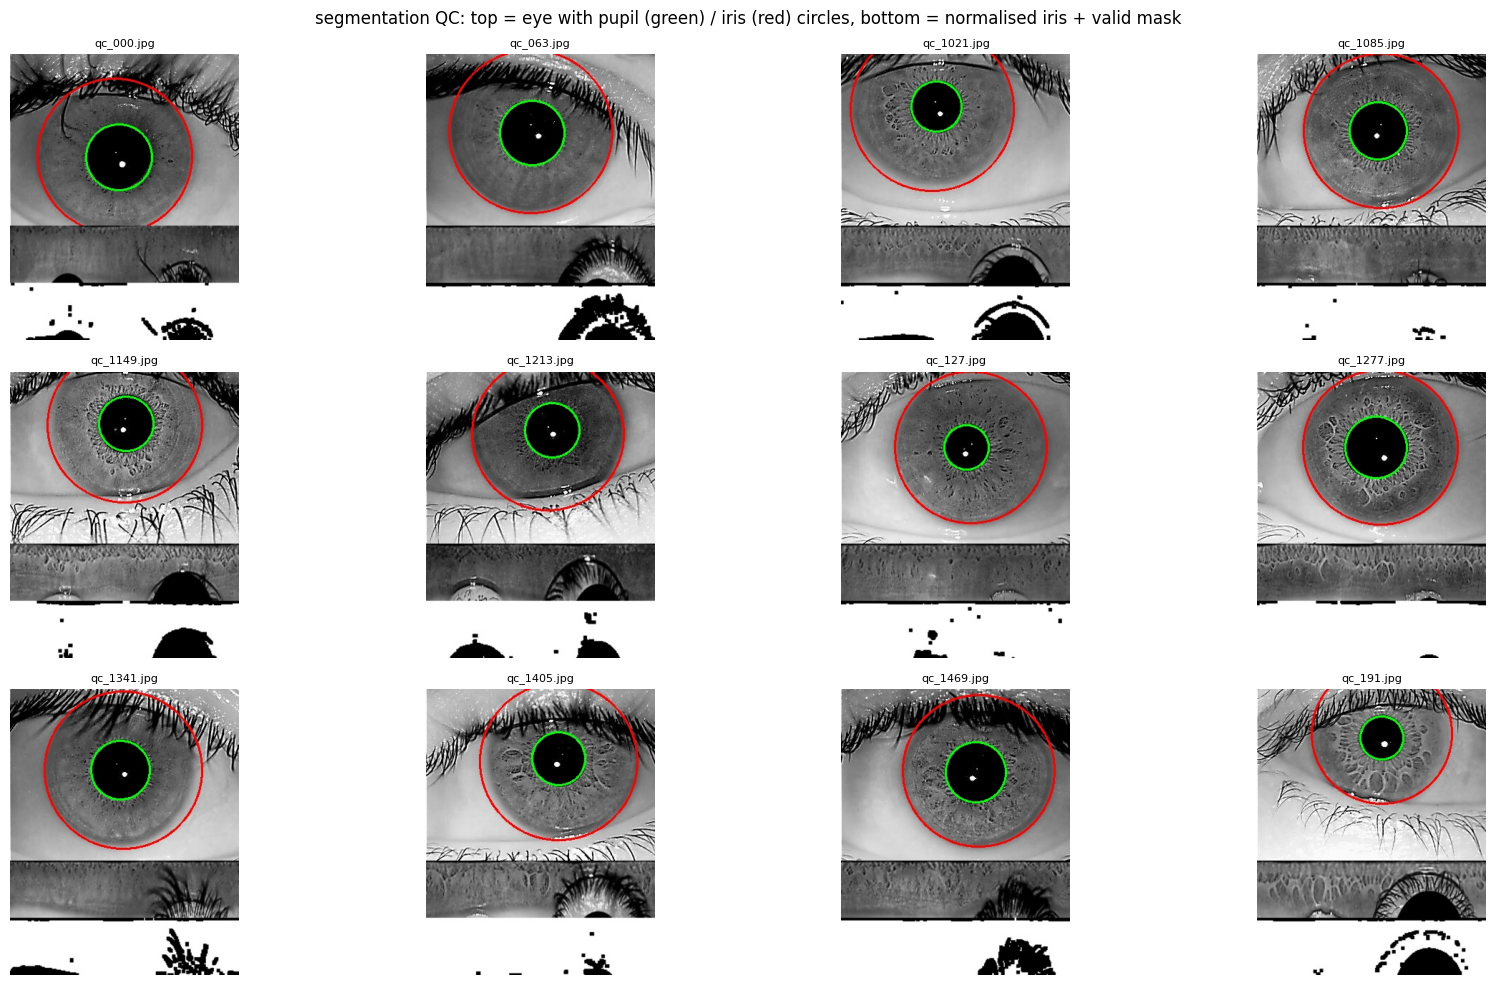

In [26]:
import glob
import cv2
import matplotlib.pyplot as plt
qc = sorted(glob.glob("qc/*.jpg"))[:12]
if qc:
    fig, ax = plt.subplots(3, 4, figsize=(18, 10))
    for a_, p in zip(ax.ravel(), qc):
        a_.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)); a_.set_title(os.path.basename(p), fontsize=8)
    for a_ in ax.ravel():
        a_.axis("off")
    plt.suptitle("segmentation QC: top = eye with pupil (green) / iris (red) circles, bottom = normalised iris + valid mask")
    plt.tight_layout(); plt.show()


## 5. Train (Step 7)
`best.pt` holds the EMA weights of the epoch with the lowest validation EER. A snapshot is copied to Drive after **every epoch**; if Colab disconnects, run the config / preprocess cells again and re-run this cell — it continues where it stopped (only when data and settings are identical). `FRESH_TRAIN=True` starts over.


In [27]:
try:
    run("train.py", "--train_root", "data/train", "--val_root", "data/val", "--epochs", EPOCHS,
        "--P", P, "--K", K, "--weight_mode", WEIGHT_MODE, "--num_workers", NUM_WORKERS, "--out", RUN_DIR,
        "--resume", 0 if FRESH_TRAIN else 1, *SYNC_ARGS)
except RuntimeError as e:
    if "out of memory" in str(e).lower() or "failed with exit code 1" in str(e):
        print("\n[!] Caught CUDA Out of Memory with default P and K. Retrying with a smaller batch size (P=8, K=4)...\n", flush=True)
        run("train.py", "--train_root", "data/train", "--val_root", "data/val", "--epochs", EPOCHS,
            "--P", 8, "--K", 4, "--weight_mode", WEIGHT_MODE, "--num_workers", NUM_WORKERS, "--out", RUN_DIR,
            "--resume", 0 if FRESH_TRAIN else 1, *SYNC_ARGS)
    else:
        raise e

$ python train.py --train_root data/train --val_root data/val --epochs 45 --P 16 --K 4 --weight_mode pcm_hard --num_workers 2 --out runs/main --resume 1 --sync_dir /content/drive/MyDrive/pcm_iris_results/run_main
train: 1427 images / 287 ids | val: 20 images / 10 ids
params: 403.7K | 22 batches/epoch of 16x4 | device cuda
Traceback (most recent call last):
  File "/content/pcm_iris/train.py", line 249, in <module>
    main()
    ~~~~^^
  File "/content/pcm_iris/train.py", line 196, in main
    out = model(img)
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 1779, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
           ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py", line 1790, in _call_impl
    return forward_call(*args, **kwargs)
  File "/content/pcm_iris/model.py", line 66, in forward
    f = self.body(z)
  File "/usr/local/lib/python3.13/dist-packages/torch/nn/modules/

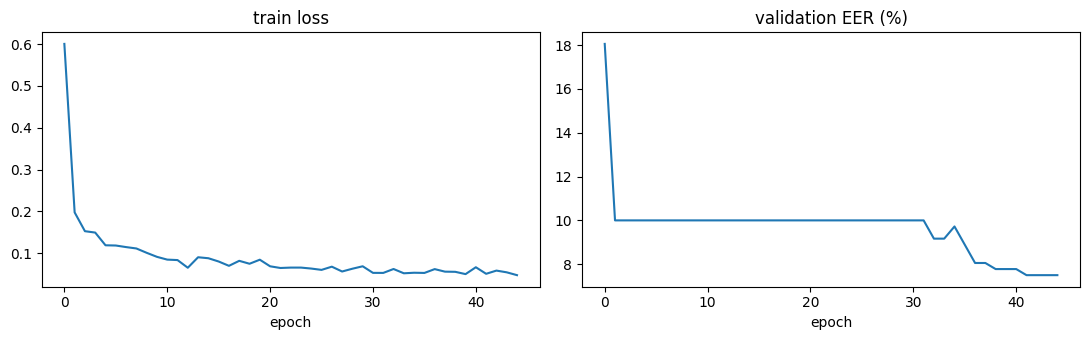

In [28]:
import matplotlib.pyplot as plt
with open(f"{RUN_DIR}/history.json") as f:
    hist = json.load(f)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot([h["loss"] for h in hist]); ax[0].set_title("train loss"); ax[0].set_xlabel("epoch")
ax[1].plot([100 * h["EER"] for h in hist]); ax[1].set_title("validation EER (%)"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 6. Evaluate (Step 8)
1. **Validation set** (never used for the final numbers): calibrate the decision threshold and the fusion weight.
2. **Test set**: IrisNet (PCM × mask), IrisNet (PCM only), classical IrisCode, and the fusion of IrisNet + IrisCode.

In [29]:
import numpy as np
import pandas as pd
from evaluate import summarize, fuse, det_curve

def eval_scores(tag, root, *extra):
    """Runs evaluate.py and returns (metrics dict, (gen, imp) scores)."""
    out, npz = f"{RUN_DIR}/{tag}.json", f"{RUN_DIR}/{tag}_scores.npz"
    run("evaluate.py", "--test_root", root, "--num_workers", NUM_WORKERS, "--out", out, "--save_scores", npz, *extra)
    with open(out) as f:
        res = json.load(f)
    s = np.load(npz)
    return res, (s["gen"], s["imp"])

# --- 1. calibration on the validation set ---
val_net, val_net_s = eval_scores("val_net", "data/val", "--ckpt", CKPT, "--weight_mode", WEIGHT_MODE)
_, val_ic_s = eval_scores("val_iriscode", "data/val", "--method", "iriscode")
grid = np.round(np.linspace(0, 1, 11), 2)
val_fused = [summarize(*fuse([val_net_s, val_ic_s], [w, 1 - w])) for w in grid]
# lowest val EER; ties (common when val EER is ~0) are broken by the larger d' (better separation)
FUSE_W = float(grid[min(range(len(grid)), key=lambda k: (val_fused[k]["EER"], -val_fused[k]["d_prime"]))])
THRESHOLD = val_net["thr@FAR=0.001"] if val_net.get("thr@FAR=0.001") is not None else val_net["thr@EER"]
with open(f"{RUN_DIR}/threshold.json", "w") as f:
    json.dump({"threshold": THRESHOLD, "weight_mode": WEIGHT_MODE, "fuse_w": FUSE_W,
               "rule": "FAR=0.1% on val" if val_net.get("thr@FAR=0.001") is not None else "EER on val"}, f, indent=1)
print(f"val EER {100 * val_net['EER']:.2f}% | decision threshold {THRESHOLD:.4f} | fusion weight (net) {FUSE_W}")

$ python evaluate.py --test_root data/val --num_workers 2 --out runs/main/val_net.json --save_scores runs/main/val_net_scores.npz --ckpt runs/main/best.pt --weight_mode pcm_hard
{
 "method": "net",
 "n_images": 20,
 "weight_mode": "pcm_hard",
 "shift": 4,
 "EER": 0.07499999999999998,
 "thr@EER": 1.7540395609697297,
 "n_genuine": 10,
 "n_impostor": 180,
 "genuine_mean": 0.4674801230430603,
 "impostor_mean": 2.0420660972595215,
 "d_prime": 3.968576431274414,
 "FRR@FAR=0.01": null,
 "thr@FAR=0.01": null,
 "FRR@FAR=0.001": null,
 "thr@FAR=0.001": null,
 "FRR@FAR=0.0001": null,
 "thr@FAR=0.0001": null,
 "FRR@FAR=1e-05": null,
 "thr@FAR=1e-05": null
}
$ python evaluate.py --test_root data/val --num_workers 2 --out runs/main/val_iriscode.json --save_scores runs/main/val_iriscode_scores.npz --method iriscode
{
 "method": "iriscode",
 "n_images": 20,
 "iriscode_shift": 8,
 "EER": 0.19999999999999998,
 "thr@EER": 1.8929131269128618,
 "n_genuine": 10,
 "n_impostor": 180,
 "genuine_mean": 1.303496

$ python evaluate.py --test_root data/test --num_workers 2 --out runs/main/test_IrisNet__pcm_hard_.json --save_scores runs/main/test_IrisNet__pcm_hard__scores.npz --ckpt runs/main/best.pt --weight_mode pcm_hard
{
 "method": "net",
 "n_images": 20,
 "weight_mode": "pcm_hard",
 "shift": 4,
 "EER": 0.09999999999999999,
 "thr@EER": 1.8100134318530006,
 "n_genuine": 10,
 "n_impostor": 180,
 "genuine_mean": 0.40034908056259155,
 "impostor_mean": 2.0512332916259766,
 "d_prime": 4.357799530029297,
 "FRR@FAR=0.01": null,
 "thr@FAR=0.01": null,
 "FRR@FAR=0.001": null,
 "thr@FAR=0.001": null,
 "FRR@FAR=0.0001": null,
 "thr@FAR=0.0001": null,
 "FRR@FAR=1e-05": null,
 "thr@FAR=1e-05": null
}
$ python evaluate.py --test_root data/test --num_workers 2 --out runs/main/test_IrisNet__pcm_only_.json --save_scores runs/main/test_IrisNet__pcm_only__scores.npz --ckpt runs/main/best.pt --weight_mode pcm
{
 "method": "net",
 "n_images": 20,
 "weight_mode": "pcm",
 "shift": 4,
 "EER": 0.09999999999999999,
 "th

,EER,FRR@FAR=0.01,FRR@FAR=0.001,FRR@FAR=0.0001,d_prime,n_genuine,n_impostor
IrisNet (pcm_hard),10.00%,n/a,n/a,n/a,4.3578,10,180
IrisNet (pcm only),10.00%,n/a,n/a,n/a,4.253188,10,180
IrisCode baseline,10.00%,n/a,n/a,n/a,2.118375,10,180
Fusion IrisNet+IrisCode (w=1.0),10.00%,n/a,n/a,n/a,4.3578,10.0,180.0


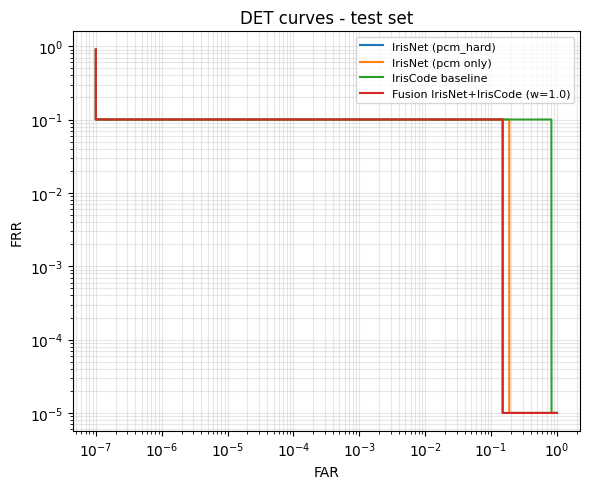

In [30]:
# --- 2. test set ---
results, curves = {}, {}
for name, extra in {
        f"IrisNet ({WEIGHT_MODE})": ["--ckpt", CKPT, "--weight_mode", WEIGHT_MODE],
        "IrisNet (pcm only)": ["--ckpt", CKPT, "--weight_mode", "pcm"],
        "IrisCode baseline": ["--method", "iriscode"]}.items():
    if name == "IrisNet (pcm only)" and WEIGHT_MODE == "pcm":
        continue
    tag = "test_" + "".join(c if c.isalnum() else "_" for c in name)
    res, s = eval_scores(tag, "data/test", *extra)
    results[name], curves[name] = res, s
net_s, ic_s = curves[f"IrisNet ({WEIGHT_MODE})"], curves["IrisCode baseline"]
fused = fuse([net_s, ic_s], [FUSE_W, 1 - FUSE_W])
results[f"Fusion IrisNet+IrisCode (w={FUSE_W})"] = summarize(*fused)
curves[f"Fusion IrisNet+IrisCode (w={FUSE_W})"] = fused

cols = ["EER", "FRR@FAR=0.01", "FRR@FAR=0.001", "FRR@FAR=0.0001", "d_prime", "n_genuine", "n_impostor"]
table = pd.DataFrame(results).T[cols]
for c in cols[:4]:
    table[c] = table[c].map(lambda v: "n/a" if v is None or pd.isna(v) else f"{100 * float(v):.2f}%")
display(table)
with open(f"{RUN_DIR}/test_results.json", "w") as f:
    json.dump(results, f, indent=1)

plt.figure(figsize=(6, 5))
for name, (g, i) in curves.items():
    far, frr, _ = det_curve(g, i)
    plt.loglog(np.clip(far, 1e-7, 1), np.clip(frr, 1e-5, 1), label=name)
plt.xlabel("FAR"); plt.ylabel("FRR"); plt.title("DET curves - test set")
plt.grid(True, which="both", alpha=.3); plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(f"{RUN_DIR}/det_test.png", dpi=150); plt.show()

Cross-dataset evaluation (runs only if `CROSS_ROOT` is set).

In [31]:
if CROSS_ROOT:
    run("evaluate.py", "--ckpt", CKPT, "--test_root", CROSS_ROOT, "--weight_mode", WEIGHT_MODE,
        "--num_workers", NUM_WORKERS, "--out", f"{RUN_DIR}/eval_cross.json", "--det", f"{RUN_DIR}/det_cross.png")
else:
    print("CROSS_ROOT not set - skipped")

CROSS_ROOT not set - skipped


### Identify by name (1:N)
Everybody is **enrolled by name**; the question is "whose eye is this?".
* `SPLIT_BY="image"`: the gallery is built from the **training images** and every **held-out** val/test image is a query (it was never enrolled, so the test is honest for these people).
* `SPLIT_BY="person"`: leave-one-out inside the val/test split (the people were never trained on).

Reported: **rank-1 / rank-5 accuracy by name** and the open-set behaviour (an *unknown* person = the query's own person removed from the gallery must be rejected). The accept/reject threshold is calibrated on the **validation** queries and then fixed for the **test** queries.


In [32]:
import pandas as pd
from identify import IrisGallery, evaluate_identification, format_result

mk = lambda: IrisGallery(CKPT, weight_mode=WEIGHT_MODE)
if SPLIT_BY == "image":
    g_train = mk()                                        # gallery = training images of everybody (embedded once)
    val_id, _ = evaluate_identification(g_train, "data/train", far=IDENT_FAR, query_root="data/val")
    IDENT_THR = val_id["thr@FAR"]                         # calibrated on validation queries ...
    test_id, test_det = evaluate_identification(g_train, None, threshold=IDENT_THR, query_root="data/test")   # ... fixed for test
    del g_train
else:
    val_id, _ = evaluate_identification(mk(), "data/val", far=IDENT_FAR)
    IDENT_THR = val_id["thr@FAR"]
    test_id, test_det = evaluate_identification(mk(), "data/test", threshold=IDENT_THR)

pct = lambda v: f"{100 * v:.2f}%"
print(f"\nthreshold {IDENT_THR:.4f} (unknown person accepted ~{pct(IDENT_FAR)} on validation)")
tab = pd.DataFrame({"validation": val_id, "test": test_id}).T[
    ["n_people", "n_queries", "rank1", "rank5", "correct_accept@thr", "FRR@thr", "FAR@thr", "EER", "d_prime"]]
for c_ in ["rank1", "rank5", "correct_accept@thr", "FRR@thr", "FAR@thr", "EER"]:
    tab[c_] = tab[c_].map(pct)
tab["d_prime"] = tab["d_prime"].map(lambda v: f"{v:.2f}")
tab[["n_people", "n_queries"]] = tab[["n_people", "n_queries"]].astype(int)
display(tab)
print("rank-1/5: the right NAME is the best / among the 5 best.  correct_accept: right name AND accepted.  "
      "FRR: enrolled person rejected.  FAR: unknown person accepted.")

pp = pd.DataFrame([(n, a, c) for n, (a, c) in test_det["per_person"].items()], columns=["name", "rank1_acc", "queries"]).sort_values(["rank1_acc", "name"])
print("\nhardest people on the test set:")
display(pp.head(8).assign(rank1_acc=lambda d: d.rank1_acc.map(pct)))
for e in test_det["errors"][:8]:
    print(f"  {e['true']:<22} was identified as {e['predicted']:<22} (distance {e['distance']:.3f}) {os.path.basename(e['image'])}")

with open(f"{RUN_DIR}/identification.json", "w") as f:
    json.dump({"threshold": IDENT_THR, "far_target": IDENT_FAR, "weight_mode": WEIGHT_MODE,
               "protocol": "gallery=train, queries=held-out images" if SPLIT_BY == "image" else "leave-one-out per split",
               "val": val_id, "test": test_id}, f, indent=1)


gallery: 1427 templates / 147 people

threshold 1.3365 (unknown person accepted ~1.00% on validation)


,n_people,n_queries,rank1,rank5,correct_accept@thr,FRR@thr,FAR@thr,EER,d_prime
validation,147,20,100.00%,100.00%,100.00%,0.00%,5.00%,0.00%,9.97
test,147,20,100.00%,100.00%,95.00%,5.00%,5.00%,5.00%,4.59


rank-1/5: the right NAME is the best / among the 5 best.  correct_accept: right name AND accepted.  FRR: enrolled person rejected.  FAR: unknown person accepted.

hardest people on the test set:


,name,rank1_acc,queries
0,Aditya_Iyer,100.00%,2
1,Anjali_Bhatt,100.00%,2
2,Diya_Kulkarni,100.00%,2
3,Ishaan_Kapoor,100.00%,2
4,Ishaan_Yadav,100.00%,2
5,Jaya_Sharma,100.00%,2
6,Kavya_Bansal,100.00%,2
7,Nisha_Iyer,100.00%,2


## 7. Ablations (Step 9)

In [33]:
if RUN_ABLATIONS:
    cross = ["--cross_root", CROSS_ROOT] if CROSS_ROOT else []
    run("run_ablations.py", "--train_root", "data/train", "--val_root", "data/val", "--test_root", "data/test",
        *cross, "--epochs", ABL_EPOCHS, "--P", P, "--K", K)
    display(pd.read_csv("runs/ablation/results.csv"))
else:
    print("RUN_ABLATIONS is False - skipped")

RUN_ABLATIONS is False - skipped


## 8. Analysis (Step 10)
Phase-confidence maps on corrupted test images, plus model size and latency.

$ python analyze.py --ckpt runs/main/best.pt --test_root data/test --out figs
{'params': 403673, 'size_MB': 1.804413, 'latency_ms': 28.38141918182373}


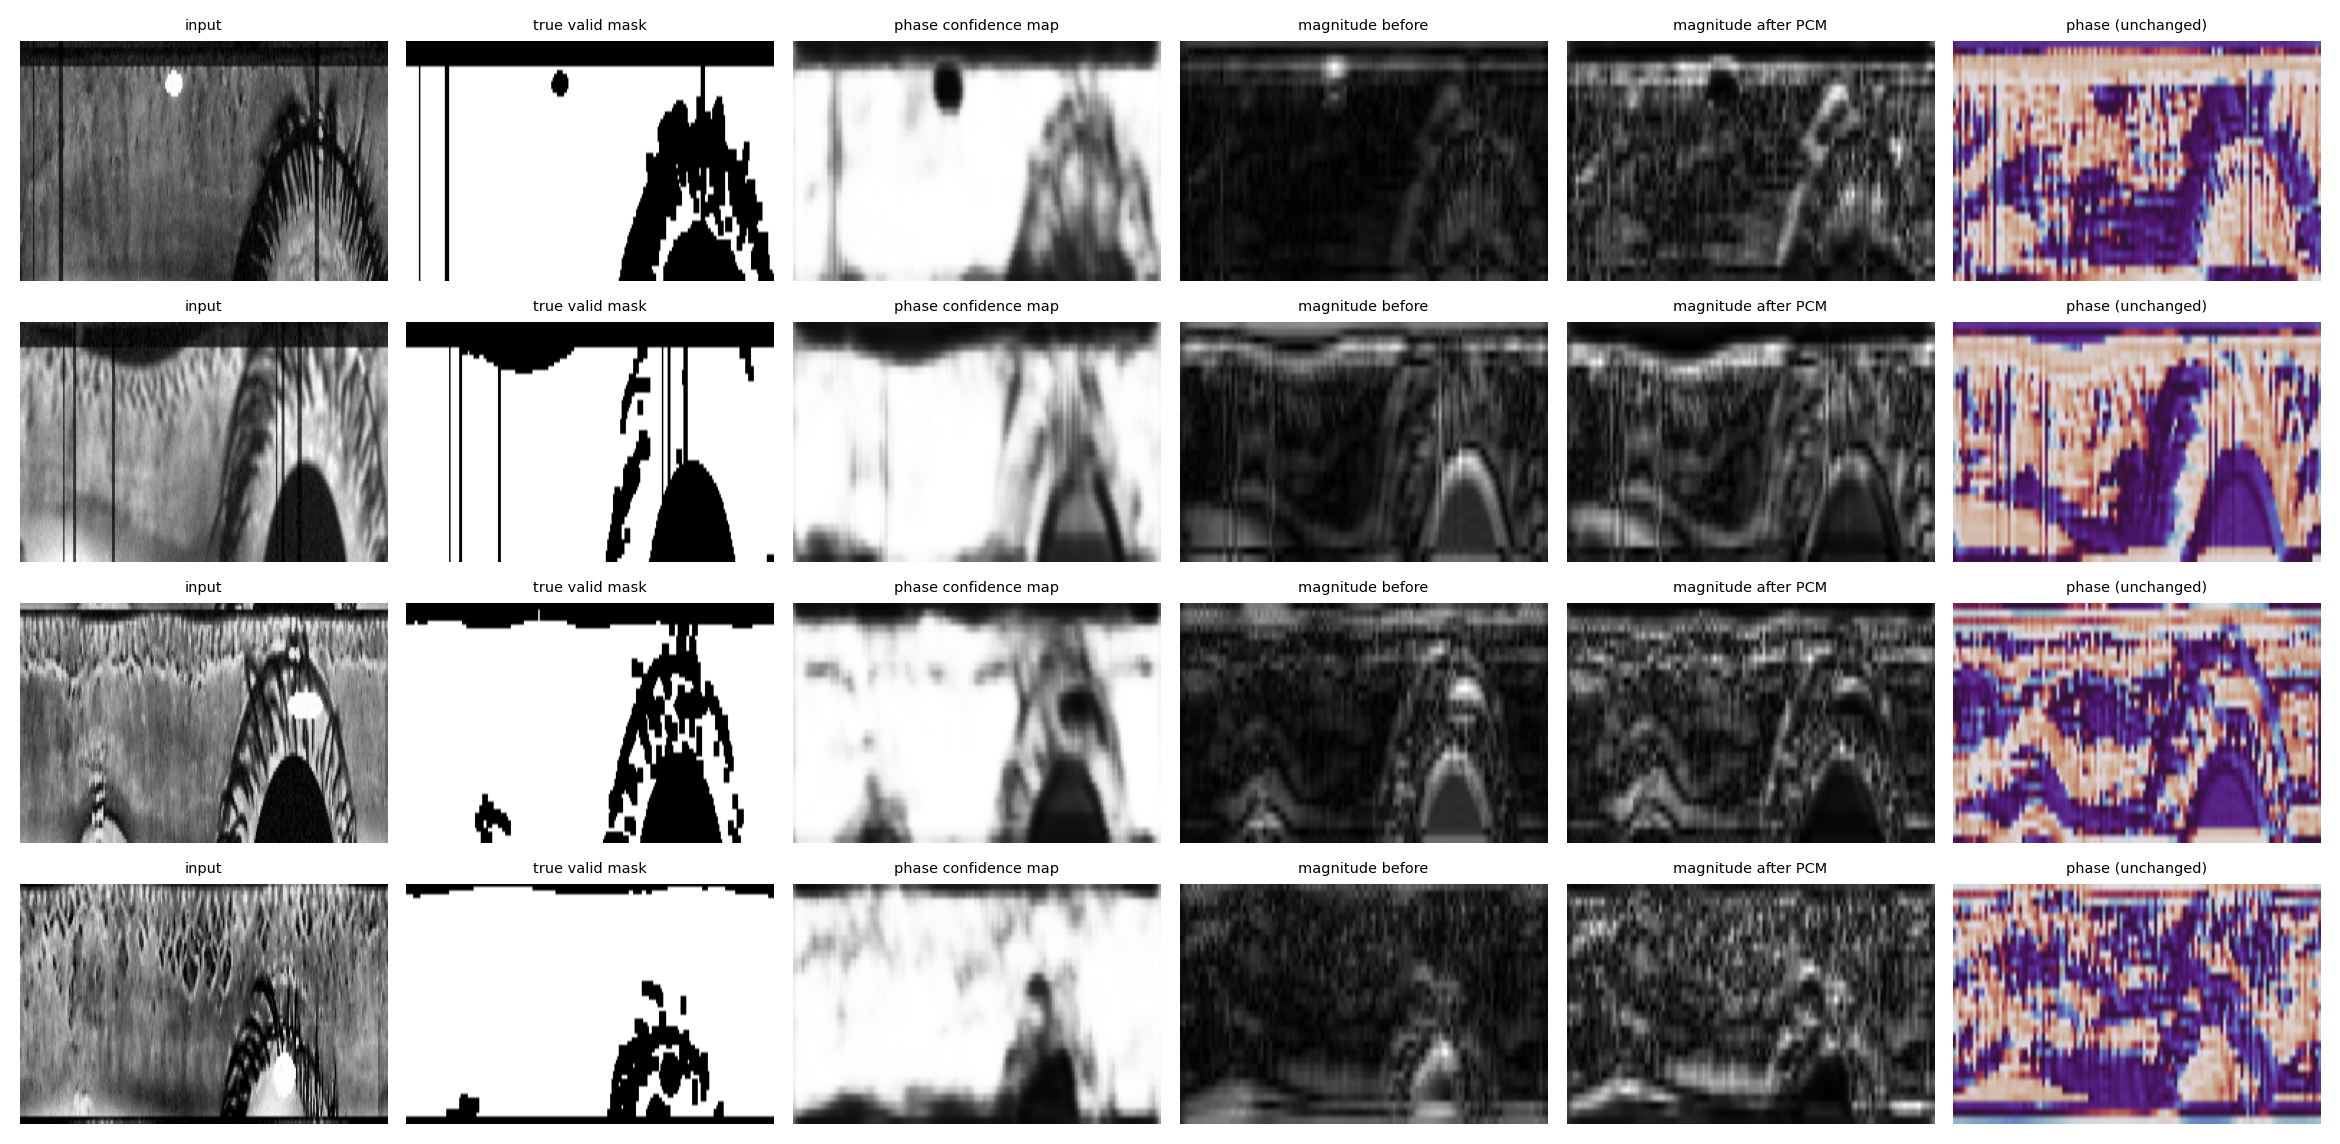

In [34]:
from IPython.display import Image, display
run("analyze.py", "--ckpt", CKPT, "--test_root", "data/test", "--out", "figs")
display(Image("figs/pcm_maps.png"))

## 8b. Optional — final model trained on 100 % of the images
Set `TRAIN_ON_ALL_IMAGES = True` in the config to train a second model on **every** image (train + val + test, all people, both eyes) for the same number of epochs the validated run needed. It is used by the name-identification gallery and the web app below. Because it has seen the held-out images, its numbers can no longer be measured honestly — the metrics above (from the validated run) are the ones to report, and the decision threshold calibrated there is reused.


In [35]:
FINAL_DIR = "runs/final_all"
if TRAIN_ON_ALL_IMAGES:
    _ck = torch.load(CKPT, map_location="cpu", weights_only=False)
    FINAL_EPOCHS = max(20, int(_ck["epoch"]) + 1)
    print(f"training on ALL normalised images (train + val + test) for {FINAL_EPOCHS} epochs")
    run("train.py", "--train_root", "normalized", "--val_root", "data/val", "--epochs", FINAL_EPOCHS,
        "--P", P, "--K", K, "--weight_mode", WEIGHT_MODE, "--patience", 0, "--num_workers", NUM_WORKERS,
        "--out", FINAL_DIR, "--resume", 0 if FRESH_TRAIN else 1,
        *(["--sync_dir", os.path.join(SAVE_DIR, "run_final_all")] if SYNC_DIR else []))
    APP_CKPT = f"{FINAL_DIR}/last.pt"                    # last epoch (EMA weights); 'best' is meaningless once val is in training
    print("gallery and web app will use", APP_CKPT)
else:
    print("TRAIN_ON_ALL_IMAGES is False - skipped (the gallery and web app use", APP_CKPT, ")")


TRAIN_ON_ALL_IMAGES is False - skipped (the gallery and web app use runs/main/best.pt )


## 9. Save results to Drive

In [36]:
if IN_COLAB and not USE_DEMO_DATA:
    os.makedirs(SAVE_DIR, exist_ok=True)
    for src in ("runs", "figs", "qc"):
        if os.path.isdir(src):
            shutil.copytree(src, os.path.join(SAVE_DIR, src), dirs_exist_ok=True)
    for f_ in ("data/split_manifest.json", "normalized_rejected.txt"):
        if os.path.exists(f_):
            shutil.copy(f_, SAVE_DIR)
    print("saved to", SAVE_DIR)
else:
    print("not running on Colab with real data - nothing copied")


saved to /content/drive/MyDrive/pcm_iris_results


### Download the results to your PC
Zips the trained models, metrics, figures, QC images and the split manifest (not the image folders) and downloads the zip. Checkpoints are also in your Drive (`SAVE_DIR`).


In [37]:
import shutil
if IN_COLAB:
    from google.colab import files
    # zip only the RESULTS (not data/ and normalized/, which are tens of thousands of images)
    stage = "/content/pcm_iris_results_stage"
    shutil.rmtree(stage, ignore_errors=True)
    os.makedirs(stage)
    for src in ("runs", "figs", "qc"):
        if os.path.isdir(src):
            shutil.copytree(src, os.path.join(stage, src), ignore=shutil.ignore_patterns("full.pt"))
    for f_ in ("data/split_manifest.json", "normalized_rejected.txt", "app_config.json"):
        if os.path.exists(f_):
            shutil.copy(f_, stage)
    shutil.make_archive("/content/pcm_iris_results", "zip", stage)
    files.download("/content/pcm_iris_results.zip")
else:
    print("not running on Colab - results are in", WORK_DIR)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Iris matching demo
Loads the trained model, builds templates of two normalised iris images and decides **MATCH / NOT A MATCH**
with the threshold calibrated on the validation set (FAR = 0.1 %, or EER if the validation set is too small).

=== GENUINE pair (same eye) ===
Aditya_Iyer_left/Aditya_Iyer_03_L.png <-> Aditya_Iyer_left/Aditya_Iyer_04_L.png | distance 0.1227 (threshold 1.7540) -> MATCH


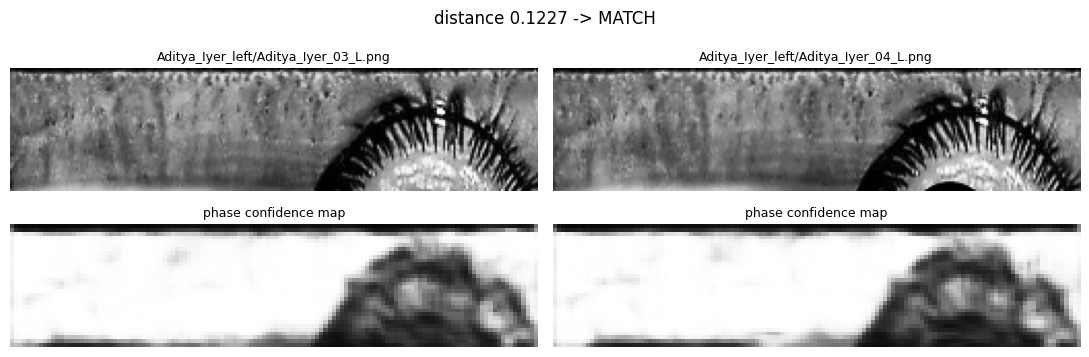

=== IMPOSTOR pair (different eyes) ===
Aditya_Iyer_left/Aditya_Iyer_03_L.png <-> Anjali_Bhatt_left/Anjali_Bhatt_04_L.png | distance 2.1348 (threshold 1.7540) -> NOT A MATCH


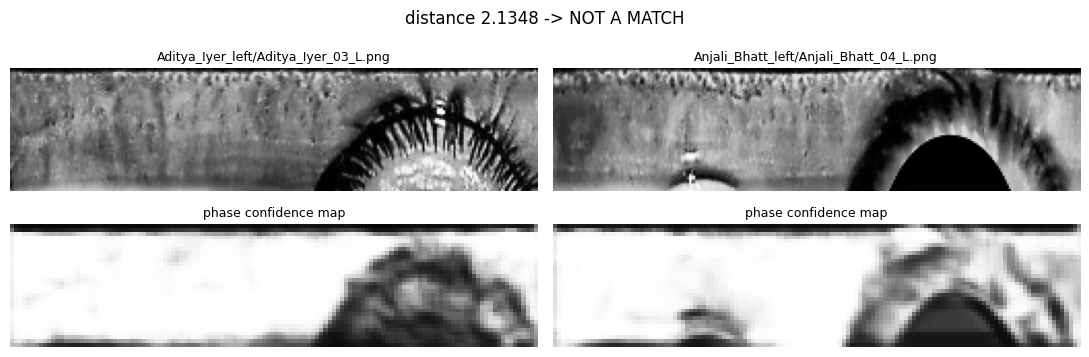

(2.134784698486328, False)

In [38]:
import torch
import matplotlib.pyplot as plt
from model import load_checkpoint
from data import IrisFolder, load_normalized
from losses import pairwise_distance, pick_weights

device = "cuda" if torch.cuda.is_available() else "cpu"
model, train_args = load_checkpoint(CKPT, device)
CLAHE = bool(train_args.get("clahe", 0))
SHIFT = int(train_args.get("max_shift", 4))
MODE = WEIGHT_MODE if model.pcm is not None else "hard"
with open(f"{RUN_DIR}/threshold.json") as f:
    THRESHOLD = json.load(f)["threshold"]


@torch.no_grad()
def template(path):
    img, m = load_normalized(path, CLAHE)            # same preprocessing as training/evaluation
    x = torch.from_numpy(img)[None, None].to(device)
    out = model(x)
    w = pick_weights(out, torch.from_numpy(m)[None, None].to(device), MODE)
    return img, out["feat"], w, out["conf"]


def verify_match(path_a, path_b, threshold=None, show=True):
    threshold = THRESHOLD if threshold is None else threshold
    img_a, f_a, w_a, c_a = template(path_a)
    img_b, f_b, w_b, c_b = template(path_b)
    dist = pairwise_distance(f_a, w_a, f_b, w_b, max_shift=SHIFT).item()
    match = dist <= threshold
    tag = lambda p: os.path.join(os.path.basename(os.path.dirname(p)), os.path.basename(p))
    print(f"{tag(path_a)} <-> {tag(path_b)} | distance {dist:.4f} (threshold {threshold:.4f}) -> "
          f"{'MATCH' if match else 'NOT A MATCH'}")
    if show:
        fig, ax = plt.subplots(2, 2, figsize=(11, 3.6))
        for k, (im, c, p) in enumerate([(img_a, c_a, path_a), (img_b, c_b, path_b)]):
            ax[0, k].imshow(im, cmap="gray", aspect="auto"); ax[0, k].set_title(tag(p), fontsize=9)
            if c is not None:
                ax[1, k].imshow(c[0, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1, aspect="auto")
                ax[1, k].set_title("phase confidence map", fontsize=9)
        for a_ in ax.ravel():
            a_.axis("off")
        fig.suptitle(f"distance {dist:.4f} -> {'MATCH' if match else 'NOT A MATCH'}")
        plt.tight_layout(); plt.show()
    return dist, match


test_ds = IrisFolder("data/test")
by_id = {}
for p, l in zip(test_ds.items, test_ds.labels):
    by_id.setdefault(l, []).append(p)
gid = next(l for l, v in by_id.items() if len(v) >= 2)
other = next(l for l in by_id if l != gid)
print("=== GENUINE pair (same eye) ===")
verify_match(by_id[gid][0], by_id[gid][1])
print("=== IMPOSTOR pair (different eyes) ===")
verify_match(by_id[gid][0], by_id[other][0])

### Manual Verification Check
Use the cell below to manually test the matching model with any custom pairs of normalized images from your dataset.

--- same person: Aditya_Iyer vs Aditya_Iyer ---
Aditya_Iyer_left/Aditya_Iyer_03_L.png <-> Aditya_Iyer_left/Aditya_Iyer_04_L.png | distance 0.1227 (threshold 1.7540) -> MATCH


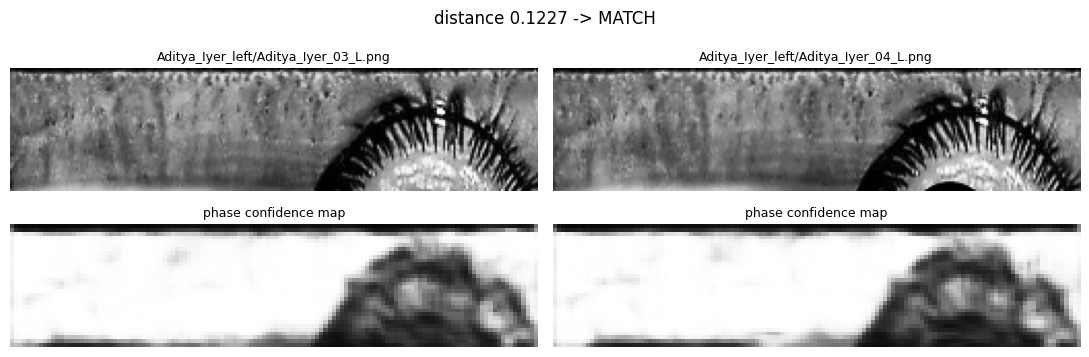


--- different people: Aditya_Iyer vs Anjali_Bhatt ---
Aditya_Iyer_left/Aditya_Iyer_03_L.png <-> Anjali_Bhatt_left/Anjali_Bhatt_04_L.png | distance 2.1348 (threshold 1.7540) -> NOT A MATCH


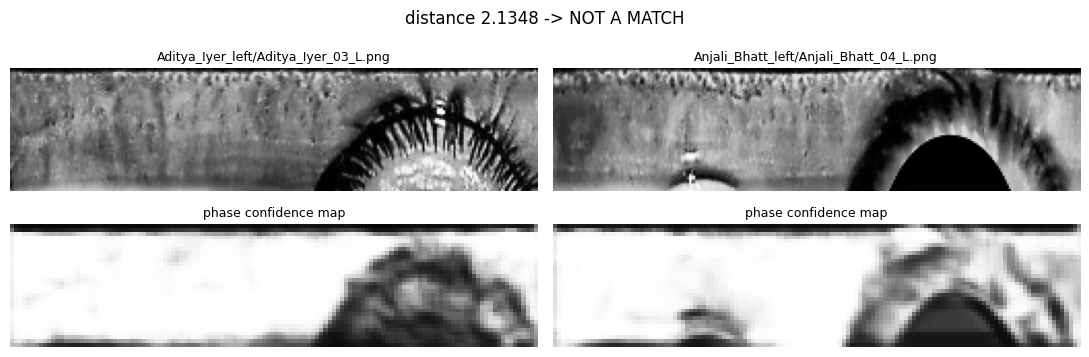

(2.134784698486328, False)

In [39]:
# Compare two held-out (test) images by NAME. Names are the dataset's folder names (Firstname_Lastname) - replace them with any two people.
import glob
from preprocess import split_identity
test_people = sorted({split_identity(d)[0] for d in test_ds.ids})      # people with held-out test images


def images_of(name, eye=None):
    for e in ([eye] if eye else ["left", "right"]):
        ps = sorted(p for p in glob.glob(f"data/test/{name}_{e}/*.png") if "_mask" not in p)
        if ps:
            return ps
    raise FileNotFoundError(f"no held-out test images for {name!r} - check the spelling (folder names look like Firstname_Lastname)")


PERSON_A, PERSON_B = test_people[0], test_people[1]        # <- e.g. "Aarav_Bansal", "Diya_Kulkarni"
a_imgs, b_imgs = images_of(PERSON_A), images_of(PERSON_B)

print(f"--- same person: {PERSON_A} vs {PERSON_A} ---")
verify_match(a_imgs[0], a_imgs[1])
print(f"\n--- different people: {PERSON_A} vs {PERSON_B} ---")
verify_match(a_imgs[0], b_imgs[0])

### Who is this? — identify by name
Everybody in `normalized/` is enrolled **by name** (all images of all people). Give it **one raw eye image** or **all raw images of one person** and it answers with the person's name. Raw photos are segmented and normalised automatically, exactly like the training data.
`exclude_self=True` hides the query's own enrolled copy, so a dataset image never matches itself. (The model may have been trained on that image if it was in the train split — for an unbiased number use the held-out table above.)
The accept/reject threshold is the one calibrated on the validation images above.


gallery: 1467 templates / 147 people
147 people enrolled, e.g. ['Aarav_Bansal', 'Aarav_Chauhan', 'Aarav_Kumar']

=== ONE IMAGE: Aarav_Bansal/L/Aarav_Bansal_01_L.bmp
IDENTIFIED: Aarav Bansal
distance 0.3666 (accept if <= 1.3365) | eye: left
expected (from the path): Aarav Bansal -> CORRECT
top matches:
  1. Aarav Bansal             0.3666
  2. Dev Malhotra             1.4512
  3. Arjun Gupta              1.4571
  4. Divya Iyer               1.5462
  5. Pallavi Kumar            1.5708


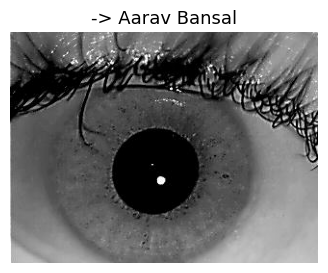


=== WHOLE PERSON: Aarav_Bansal (10 images)
IDENTIFIED: Aarav Bansal
distance 0.2676 (accept if <= 1.3365) | eye: right
images used: 10
expected (from the path): Aarav Bansal -> CORRECT
top matches:
  1. Aarav Bansal             0.2676  votes 10
  2. Aisha Malhotra           1.6321  votes 0
  3. Divya Iyer               1.6447  votes 0
  4. Dev Malhotra             1.6489  votes 0
  5. Vikram Saxena            1.6490  votes 0


In [40]:
import json
import matplotlib.pyplot as plt
from identify import IrisGallery, format_result, list_images

IDENT_THR = json.load(open(f"{RUN_DIR}/identification.json"))["threshold"]
gallery = IrisGallery(APP_CKPT, weight_mode=WEIGHT_MODE, threshold=IDENT_THR)
gallery.enroll_folder("normalized")                       # everybody, labelled by name
print(f"{len(gallery.people)} people enrolled, e.g. {gallery.people[:3]}\n")

# ---- edit these (None = pick automatically) ----------------------------------------------------------------
QUERY_PERSON = None      # e.g. "Aarav_Bansal"  -> all of that person's raw images are used as one query
QUERY_IMAGE  = None      # e.g. f"{RAW_DIR}/Aarav_Bansal/L/<file>.jpg"  (one raw eye image)
# -------------------------------------------------------------------------------------------------------------
QUERY_PERSON = QUERY_PERSON or sorted(PERSON_IMAGES)[0]
person_imgs = PERSON_IMAGES.get(QUERY_PERSON) or list_images(os.path.join(RAW_DIR, QUERY_PERSON))
QUERY_IMAGE = QUERY_IMAGE or person_imgs[0]

print("=== ONE IMAGE:", os.path.relpath(QUERY_IMAGE, RAW_DIR))
res = gallery.identify_image(QUERY_IMAGE, exclude_self=True)
print(format_result(res))
plt.figure(figsize=(4, 3)); plt.imshow(cv2.imread(QUERY_IMAGE, 0), cmap="gray"); plt.axis("off")
plt.title("-> " + res["name"].replace("_", " ") if res["accepted"] else "-> not recognised", fontsize=13); plt.show()

print(f"\n=== WHOLE PERSON: {QUERY_PERSON} ({len(person_imgs)} images)")
res = gallery.identify_paths(person_imgs, exclude_self=True, source=QUERY_PERSON)
print(format_result(res))


### Web app (Gradio)
Upload one eye image, or all images of one person, and get the name back; new people can be enrolled in the app without retraining.

In [41]:
import json
try:
    _thr = IDENT_THR
except NameError:                                          # identification cell was skipped -> fall back to the 1:1 threshold
    _thr = json.load(open(f"{RUN_DIR}/threshold.json"))["threshold"]
with open("app_config.json", "w") as f:
    json.dump({"ckpt": APP_CKPT, "weight_mode": WEIGHT_MODE, "gallery_root": "normalized", "threshold": _thr}, f, indent=1)
print(open("app_config.json").read())
!pip -q install gradio

{
 "ckpt": "runs/main/best.pt",
 "weight_mode": "pcm_hard",
 "gallery_root": "normalized",
 "threshold": 1.3365150690078735
}


In [42]:
%%writefile iris_webapp.py
"""Gradio app: upload an eye image (or all images of one person) -> the person's NAME.
Reads app_config.json (written by the notebook): checkpoint, weight mode, gallery folder, calibrated threshold."""
import csv
import datetime
import json
import os
import sys

import gradio as gr

sys.path.insert(0, os.getcwd())
from identify import IrisGallery, format_result, list_images

CFG = json.load(open("app_config.json"))
gallery = IrisGallery(CFG["ckpt"], weight_mode=CFG["weight_mode"], threshold=CFG["threshold"])
gallery.enroll_folder(CFG["gallery_root"])
LOG = "entry_log.csv"
nice = lambda n: n.replace("_", " ")


def _paths(files):
    return [f if isinstance(f, str) else getattr(f, "name", str(f)) for f in (files or [])]


def _report(res, source):
    now = datetime.datetime.now().astimezone().strftime("%Y-%m-%d %H:%M:%S %Z")
    status = "Verified" if res["accepted"] else "Not verified"
    head = (f"✅ ENTRY NOTED — {nice(res['name'])}" if res["accepted"]
            else f"❌ NOT RECOGNISED — closest enrolled person: {nice(res['closest'])}")
    new = not os.path.exists(LOG)
    with open(LOG, "a", newline="") as fh:                       # simple entry log
        w = csv.writer(fh)
        if new:
            w.writerow(["time", "status", "name", "distance", "source"])
        w.writerow([now, status, res["name"], f"{res['distance']:.4f}", source])
    body = "\n".join(format_result(res).splitlines()[1:])
    record = {"person": res["name"], "time": now, "distance": round(res["distance"], 4), "status": status}
    return f"{head}\nTime: {now}\n{body}", record


def identify_one(image, threshold, skip_same_file):
    if image is None:
        return "Please upload an eye image.", None
    try:
        res = gallery.identify_image(image, threshold=float(threshold), exclude_self=bool(skip_same_file))
        return _report(res, "image")
    except Exception as e:
        return f"Could not process the image: {e}", None


def identify_many(files, folder, threshold, skip_same_file):
    paths, folder = _paths(files), (folder or "").strip()
    try:
        if paths:
            res = gallery.identify_paths(paths, threshold=float(threshold), exclude_self=bool(skip_same_file))
        elif folder:
            if not os.path.isdir(folder):
                return f"Folder not found: {folder}", None
            res = gallery.identify_folder(folder, threshold=float(threshold), exclude_self=bool(skip_same_file))
        else:
            return "Upload the images of one person, or type a folder path.", None
        return _report(res, "folder/multi")
    except Exception as e:
        return f"Could not process the images: {e}", None


def enroll_new(name, files):
    paths = _paths(files)
    if not (name or "").strip():
        return "Type the person's name first."
    if not paths:
        return "Upload at least one eye image of the person."
    nm, skipped = gallery.add_person(name, paths)
    if nm not in gallery._pid:
        return "No usable image: " + "; ".join(e for _, e in skipped[:3])
    msg = (f"Enrolled {nice(nm)} with {len(paths) - len(skipped)} image(s); the gallery now has "
           f"{len(gallery.people)} people. (Kept in memory for this session only; no retraining was needed.)")
    return msg + ("\nSkipped: " + "; ".join(e for _, e in skipped) if skipped else "")


thr0 = float(min(max(CFG["threshold"], 0.01), 3.0))
with gr.Blocks(title="PCM Iris Recognition - who is this?") as demo:
    gr.Markdown(f"# Iris recognition — who is this?\n{len(gallery.people)} named people are enrolled. "
                "Upload a raw eye photo (it is segmented and normalised automatically) or an already-normalised strip.")
    thr = gr.Slider(0.01, 3.0, value=thr0, step=0.01,
                    label="Accept if distance ≤ this value (default: calibrated on validation people)")
    same = gr.Checkbox(value=True, label="Ignore the identical enrolled image (honest test with dataset images; "
                                         "works when the uploaded file keeps its original name)")
    with gr.Tab("One eye image"):
        img = gr.Image(type="filepath", label="Eye image")
        b1 = gr.Button("Who is this?", variant="primary")
        out1, rec1 = gr.Textbox(label="Result", lines=12), gr.JSON(label="Entry record")
        b1.click(identify_one, [img, thr, same], [out1, rec1])
    with gr.Tab("Several images of one person / a person's folder"):
        files = gr.File(file_count="multiple", type="filepath", label="All images of ONE person")
        folder = gr.Textbox(label="...or a folder path on this machine",
                            placeholder="/content/CASIA-Iris-Thousand/Aarav_Bansal")
        b2 = gr.Button("Who is this?", variant="primary")
        out2, rec2 = gr.Textbox(label="Result", lines=14), gr.JSON(label="Entry record")
        b2.click(identify_many, [files, folder, thr, same], [out2, rec2])
    with gr.Tab("Enrol a new person"):
        nm = gr.Textbox(label="Name", placeholder="Firstname Lastname")
        nf = gr.File(file_count="multiple", type="filepath", label="Eye images of the new person")
        b3, out3 = gr.Button("Enrol"), gr.Textbox(label="Status")
        b3.click(enroll_new, [nm, nf], out3)
    gr.Markdown("**Security note:** calibrate the threshold on validation data, add quality checks and liveness "
                "detection, and store templates securely before using this for real access control.")

demo.launch(share=True, debug=True)


Writing iris_webapp.py


In [44]:
%%writefile iris_webapp.py
"""IrisID - Iris recognition web app (Gradio).

Upload an eye photo (or all photos of one person) -> the person's NAME.
Reads app_config.json (written by run_pipeline.py --stage webapp): checkpoint, weight mode, gallery folder, threshold.

Features
  * Identify by one eye image, by webcam, or by several images of one person (fused score)
  * Result card: verified / not recognised badge, match-score meter, top-5 table
  * Segmentation preview (pupil + iris circles) and the normalised iris strip
  * Enrol new people - they are SAVED to disk and re-loaded on the next start (no retraining)
  * Entry log (searchable table, CSV download) and a statistics dashboard
  * People directory with template counts
"""
import csv
import datetime
import html
import json
import os
import re
import shutil
import sys
import uuid

import cv2
import gradio as gr
import matplotlib
import numpy as np
import pandas as pd

matplotlib.use("Agg")
import matplotlib.pyplot as plt

HERE = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, HERE)
import preprocess as P
from identify import IrisGallery, list_images

CFG = json.load(open(os.path.join(HERE, "app_config.json"), encoding="utf-8"))
APP_DIR = CFG.get("app_dir") or os.path.join(os.path.dirname(os.path.abspath(CFG["ckpt"])), "webapp")
ENROLL_DIR = os.path.join(APP_DIR, "enrolled_people")
LOG = os.path.join(APP_DIR, "entry_log.csv")
LOG_COLS = ["time", "status", "name", "closest", "distance", "score_%", "source"]
os.makedirs(ENROLL_DIR, exist_ok=True)

# ----------------------------------------------------------------------------------------------- gallery
gallery = IrisGallery(CFG["ckpt"], weight_mode=CFG["weight_mode"], threshold=CFG["threshold"])
gallery.enroll_folder(CFG["gallery_root"])
DATASET_PEOPLE = set(gallery.people)
for _d in sorted(os.listdir(ENROLL_DIR)):
    _paths = list_images(os.path.join(ENROLL_DIR, _d), recursive=False)
    if _paths:
        gallery.enroll([(_d, None, p) for p in _paths], verbose=False)
ENROLLED_NOW = {d for d in os.listdir(ENROLL_DIR) if os.path.isdir(os.path.join(ENROLL_DIR, d))}

nice = lambda n: str(n).replace("_", " ")
esc = html.escape
THR0 = float(min(max(CFG["threshold"], 0.01), 3.0))

CSS = """
.gradio-container {max-width: 1250px !important; margin: auto;}
.hero {padding: 28px 32px; border-radius: 18px; color: #fff;
       background: linear-gradient(120deg, #312e81 0%, #4f46e5 45%, #06b6d4 100%);
       box-shadow: 0 10px 30px rgba(79,70,229,.30); margin-bottom: 14px;}
.hero h1 {margin: 0 0 6px 0; font-size: 2.0rem; letter-spacing: .3px; color: #fff;}
.hero p {margin: 0; opacity: .92; font-size: 1.02rem; color: #fff;}
.cards {display: grid; grid-template-columns: repeat(4, 1fr); gap: 12px; margin: 6px 0 14px 0;}
.card {border: 1px solid rgba(127,127,127,.28); background: rgba(127,127,127,.07);
       border-radius: 14px; padding: 14px 16px;}
.card .k {font-size: .78rem; text-transform: uppercase; letter-spacing: .08em; opacity: .65;}
.card .v {font-size: 1.55rem; font-weight: 700; margin-top: 2px;}
.res {border-radius: 16px; padding: 20px 22px; border: 1px solid rgba(127,127,127,.28);
      background: rgba(127,127,127,.06);}
.res.ok {border-left: 8px solid #16a34a;} .res.bad {border-left: 8px solid #dc2626;}
.res.idle {border-left: 8px solid #94a3b8;}
.badge {display: inline-block; padding: 4px 12px; border-radius: 999px; font-weight: 700;
        font-size: .82rem; letter-spacing: .05em; color: #fff;}
.badge.ok {background: #16a34a;} .badge.bad {background: #dc2626;} .badge.idle {background: #64748b;}
.res .name {font-size: 1.9rem; font-weight: 800; margin: 10px 0 4px 0;}
.res .meta {opacity: .75; font-size: .92rem;}
.meter {height: 12px; border-radius: 999px; background: rgba(127,127,127,.25); overflow: hidden; margin: 12px 0 4px 0;}
.meter > div {height: 100%; border-radius: 999px;}
.foot {opacity: .6; font-size: .82rem; text-align: center; margin-top: 18px;}
@media (max-width: 760px) {.cards {grid-template-columns: repeat(2, 1fr);}}
"""

# ----------------------------------------------------------------------------------------------- helpers
def match_score(dist, thr):
    if thr <= 0:
        return 0.0
    if dist <= thr:
        return 50.0 + 50.0 * (1.0 - dist / thr)
    return max(0.0, 50.0 * (1.0 - (dist - thr) / thr))

def stats_html():
    n_t = len(gallery.paths)
    dev = str(gallery.device).upper()
    cards = [("People enrolled", f"{len(gallery.people):,}"), ("Templates", f"{n_t:,}"),
             ("Default threshold", f"{THR0:.3f}"), ("Compute", dev)]
    return '<div class="cards">' + "".join(
        f'<div class="card"><div class="k">{k}</div><div class="v">{v}</div></div>' for k, v in cards) + "</div>"

def idle_card(msg="Upload an eye image and press <b>Identify</b>."):
    return f'<div class="res idle"><span class="badge idle">READY</span><div class="meta" style="margin-top:10px">{msg}</div></div>'

def error_card(msg):
    return (f'<div class="res bad"><span class="badge bad">ERROR</span>'
            f'<div class="meta" style="margin-top:10px">{esc(msg)}</div></div>')

def result_card(res, thr, n_images=None):
    sc = match_score(res["distance"], thr)
    ok = res["accepted"]
    color = "#16a34a" if ok else "#dc2626"
    badge = '<span class="badge ok">VERIFIED</span>' if ok else '<span class="badge bad">NOT RECOGNISED</span>'
    title = nice(res["name"]) if ok else "Unknown person"
    sub = "" if ok else f'<div class="meta">Closest enrolled person: <b>{esc(nice(res["closest"]))}</b></div>'
    extra = f" &nbsp;|&nbsp; images used: {n_images}" if n_images else ""
    eye = f" &nbsp;|&nbsp; eye: {esc(res["eye"])}" if res.get("eye") else ""
    now = datetime.datetime.now().astimezone().strftime("%d %b %Y, %H:%M:%S")
    exp = ""
    if res.get("expected") is not None:
        exp = (f'<div class="meta" style="margin-top:8px">Folder/file name says: <b>{esc(nice(res["expected"]))}</b> '
               f'&rarr; {"<b style=color:#16a34a>CORRECT</b>" if res["correct"] else "<b style=color:#dc2626>WRONG</b>"}</div>')
    return (f'<div class="res {"ok" if ok else "bad"}">{badge}<div class="name">{esc(title)}</div>{sub}'
            f'<div class="meter"><div style="width:{sc:.0f}%;background:{color}"></div></div>'
            f'<div class="meta">Match score <b>{sc:.0f}/100</b> &nbsp;|&nbsp; distance {res["distance"].item() if hasattr(res["distance"], "item") else res["distance"]:.4f} '
            f'(accept if &le; {thr:.3f}){eye}{extra}</div>{exp}'
            f'<div class="meta" style="margin-top:6px">{now}</div></div>')

def top_df(res):
    rows = [[k + 1, nice(t["name"]), round(t["distance"].item() if hasattr(t["distance"], "item") else t["distance"], 4), t.get("votes", "-")] for k, t in enumerate(res["top"])]
    return pd.DataFrame(rows, columns=["Rank", "Name", "Distance", "Votes"])

def empty_top():
    return pd.DataFrame(columns=["Rank", "Name", "Distance", "Votes"])

def previews(path):
    try:
        gray = P.read_gray(path)
        if gray is None:
            return None, None
        if gray.shape == (P.H, P.W):
            return None, gray
        seg = P.segment_iris(gray) or P.segment_iris_scaled(gray)
        if seg is None:
            return cv2.cvtColor(gray, cv2.COLOR_GRAY2RGB), None
        strip, _ = P.rubber_sheet(gray, *seg)
        return cv2.cvtColor(P.draw_overlay(gray, seg), cv2.COLOR_BGR2RGB), strip
    except Exception:
        return None, None

def log_entry(res, source, thr):
    new = not os.path.exists(LOG)
    now = datetime.datetime.now().astimezone().strftime("%Y-%m-%d %H:%M:%S")
    with open(LOG, "a", newline="", encoding="utf-8") as fh:
        w = csv.writer(fh)
        if new:
            w.writerow(LOG_COLS)
        dist_val = res["distance"].item() if hasattr(res["distance"], "item") else res["distance"]
        w.writerow([now, "Verified" if res["accepted"] else "Not verified", res["name"], res["closest"],
                    f"{dist_val:.4f}", f"{match_score(dist_val, thr):.0f}", source])

def _paths(files):
    return [f if isinstance(f, str) else getattr(f, "name", str(f)) for f in (files or [])]

# ----------------------------------------------------------------------------------------------- actions
def identify_one(image, thr, same):
    if image is None:
        return idle_card("Please upload (or capture) an eye image first."), empty_top(), None, None
    try:
        thr = float(thr)
        res = gallery.identify_image(image, threshold=thr, exclude_self=bool(same))
        log_entry(res, "single image", thr)
        ov, st = previews(image)
        return result_card(res, thr), top_df(res), ov, st
    except Exception as e:
        import traceback
        traceback.print_exc()
        return error_card(f"Could not process the image: {e}"), empty_top(), None, None

def identify_many(files, folder, thr, same):
    paths, folder = _paths(files), (folder or "").strip()
    try:
        thr = float(thr)
        if paths:
            res = gallery.identify_paths(paths, threshold=thr, exclude_self=bool(same))
        elif folder:
            if not os.path.isdir(folder):
                return error_card(f"Folder not found: {folder}"), empty_top(), None, None
            res = gallery.identify_folder(folder, threshold=thr, exclude_self=bool(same))
            paths = list_images(folder)
        else:
            return idle_card("Upload all images of ONE person, or type a folder path."), empty_top(), None, None
        log_entry(res, "multi-image", thr)
        ov, st = previews(paths[0])
        return result_card(res, thr, res.get("n_images")), top_df(res), ov, st
    except Exception as e:
        return error_card(f"Could not process the images: {e}"), empty_top(), None, None

def people_df(query=""):
    cnt = np.bincount(np.asarray(gallery.owner, dtype=np.int64), minlength=len(gallery.people)) if gallery.owner else []
    rows = [[nice(n), int(cnt[i]), "enrolled in app" if n in ENROLLED_NOW else "dataset"]
            for i, n in enumerate(gallery.people)]
    df = pd.DataFrame(rows, columns=["Name", "Templates", "Source"])
    q = (query or "").strip().lower()
    return df[df["Name"].str.lower().str.contains(q, regex=False)] if q else df

def enroll_new(name, files):
    paths = _paths(files)
    key = re.sub(r"[^A-Za-z0-9_\-]", "_", (name or "").strip().replace(" ", "_"))
    if not key:
        return "Type the person's name first.", stats_html(), people_df()
    if not paths:
        return "Upload at least one eye image of the person.", stats_html(), people_df()
    dst = os.path.join(ENROLL_DIR, key)
    os.makedirs(dst, exist_ok=True)
    copies = []
    for p in paths:
        ext = os.path.splitext(p)[1].lower() or ".png"
        c = os.path.join(dst, f"{key}_{uuid.uuid4().hex[:8]}{ext}")
        shutil.copyfile(p, c)
        copies.append(c)
    skipped = gallery.enroll([(key, None, c) for c in copies], verbose=False)
    for bad, _ in skipped:
        if os.path.exists(bad):
            os.remove(bad)
    ok = len(copies) - len(skipped)
    if ok == 0:
        shutil.rmtree(dst, ignore_errors=True)
        return "No usable image: " + "; ".join(e for _, e in skipped[:3]), stats_html(), people_df()
    ENROLLED_NOW.add(key)
    msg = (f"Enrolled {nice(key)} with {ok} image(s). Saved to {dst} - the person is available "
           f"after a restart too. No retraining was needed.")
    if skipped:
        msg += "\nSkipped: " + "; ".join(e for _, e in skipped)
    if key in DATASET_PEOPLE:
        msg += "\nNote: this name already exists in the dataset - the new images were added to that person."
    return msg, stats_html(), people_df()

def read_log():
    if not os.path.exists(LOG):
        return pd.DataFrame(columns=LOG_COLS)
    try:
        return pd.read_csv(LOG).iloc[::-1].reset_index(drop=True)
    except Exception:
        return pd.DataFrame(columns=LOG_COLS)

def dashboard_plot(df):
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
    if df.empty:
        for a in ax:
            a.axis("off")
        ax[1].text(0.5, 0.5, "No entries yet", ha="center", va="center", fontsize=14)
    else:
        vc = df["status"].value_counts()
        ax[0].bar(vc.index, vc.values, color=["#16a34a" if s == "Verified" else "#dc2626" for s in vc.index])
        ax[0].set_title("Verified vs not verified")
        top = df[df["status"] == "Verified"]["name"].map(nice).value_counts().head(8)
        if len(top):
            ax[1].barh(top.index[::-1], top.values[::-1], color="#4f46e5")
        ax[1].set_title("Most frequent verified people")
        ax[2].hist(df["distance"].astype(float), bins=20, color="#06b6d4")
        ax[2].set_title("Distance distribution")
    for a in ax:
        a.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    return fig

def refresh_log(query=""):
    df = read_log()
    shown = df
    q = (query or "").strip().lower()
    if q and not df.empty:
        shown = df[df.astype(str).apply(lambda c: c.str.lower().str.contains(q, regex=False)).any(axis=1)]
    n_ok = int((df["status"] == "Verified").sum()) if not df.empty else 0
    summary = (f'<div class="cards"><div class="card"><div class="k">Total entries</div><div class="v">{len(df)}</div></div>'
               f'<div class="card"><div class="k">Verified</div><div class="v">{n_ok}</div></div>'
               f'<div class="card"><div class="k">Not verified</div><div class="v">{len(df) - n_ok}</div></div>'
               f'<div class="card"><div class="k">Verified rate</div><div class="v">{(100 * n_ok / len(df)) if len(df) else 0:.0f}%</div></div></div>')
    fig = dashboard_plot(df)
    return summary, shown, fig, (LOG if os.path.exists(LOG) else None)

# ----------------------------------------------------------------------------------------------- interface
theme = gr.themes.Soft(primary_hue="indigo", secondary_hue="cyan", neutral_hue="slate")

with gr.Blocks(title="IrisID - Iris Recognition", theme=theme, css=CSS) as demo:
    gr.HTML('<div class="hero"><h1>&#128065; IrisID &mdash; Iris Recognition</h1>'
            '<p>Phase-guided complex-masking network &middot; raw eye photos are segmented and normalised automatically '
            '&middot; identification by name, no retraining for new people.</p></div>')
    stats = gr.HTML(stats_html())

    with gr.Row():
        thr = gr.Slider(0.01, 3.0, value=THR0, step=0.01,
                        label="Decision threshold - accept if distance \u2264 value (default calibrated on validation images)")
        same = gr.Checkbox(value=True, label="Ignore the identical enrolled image (honest test with dataset images)")

    with gr.Tabs():
        with gr.Tab("\U0001F50D Identify"):
            with gr.Row():
                with gr.Column(scale=5):
                    img = gr.Image(type="filepath", label="Eye image (upload or webcam)",
                                   sources=["upload", "webcam"], height=320)
                    b1 = gr.Button("Identify", variant="primary", size="lg")
                with gr.Column(scale=6):
                    out1 = gr.HTML(idle_card())
                    tab1 = gr.Dataframe(value=empty_top(), label="Top matches", interactive=False)
            with gr.Row():
                ov1 = gr.Image(label="Segmentation (green = pupil, red = iris)", interactive=False, height=260)
                st1 = gr.Image(label="Normalised iris strip (what the network sees)", interactive=False, height=260)

        with gr.Tab("\U0001F465 One person, many images"):
            gr.Markdown("Several photos of the **same** person are fused into one decision - more reliable than a single image.")
            with gr.Row():
                with gr.Column(scale=5):
                    files = gr.File(file_count="multiple", type="filepath", label="All images of ONE person")
                    folder = gr.Textbox(label="...or a folder path on this computer",
                                        placeholder=r"C:\path\to\CASIA-Iris-Thousand\Some_Person")
                    b2 = gr.Button("Identify person", variant="primary", size="lg")
                with gr.Column(scale=6):
                    out2 = gr.HTML(idle_card("Upload the images of one person, or type a folder path."))
                    tab2 = gr.Dataframe(value=empty_top(), label="Top matches", interactive=False)
            with gr.Row():
                ov2 = gr.Image(label="Segmentation (first image)", interactive=False, height=240)
                st2 = gr.Image(label="Normalised iris strip (first image)", interactive=False, height=240)

        with gr.Tab("\u2795 Enrol new person"):
            gr.Markdown("Add a new person without retraining. Images are **saved to disk** and loaded again on the next start.")
            with gr.Row():
                with gr.Column():
                    nm = gr.Textbox(label="Name", placeholder="Firstname Lastname")
                    nf = gr.File(file_count="multiple", type="filepath", label="Eye images of the new person (3+ recommended)")
                    b3 = gr.Button("Enrol", variant="primary", size="lg")
                with gr.Column():
                    out3 = gr.Textbox(label="Status", lines=6, interactive=False)

        with gr.Tab("\U0001F4CB Entry log & dashboard"):
            logsum = gr.HTML()
            dash = gr.Plot(label="Statistics")
            with gr.Row():
                q_log = gr.Textbox(label="Search the log", placeholder="name, status, date ...", scale=4)
                b_ref = gr.Button("Refresh", scale=1)
            logtab = gr.Dataframe(label="Entries (newest first)", interactive=False, wrap=True)
            logfile = gr.File(label="Download log (CSV)", interactive=False)

        with gr.Tab("\U0001F5C2 People"):
            q_p = gr.Textbox(label="Search people", placeholder="type part of a name ...")
            ptab = gr.Dataframe(value=people_df(), label="Enrolled people", interactive=False)

        with gr.Tab("\u2139\ufe0f How it works"):
            gr.Markdown(
                "1. **Segmentation** - pupil and iris boundaries are found, the iris is unrolled into a 64\u00d7256 strip.\n"
                "2. **Network** - a Gabor block gives complex features, the *Phase Confidence Map* down-weights glare, "
                "eyelids and eyelashes, dense complex blocks produce a feature map.\n"
                "3. **Matching** - a shift-tolerant, confidence-weighted distance against every enrolled template; "
                "the best distance per person decides the name.\n"
                "4. **Threshold** - if the best distance is above the threshold the answer is *not recognised*.\n\n"
                "**Match score** is only a readability aid (50 = exactly at the threshold). Treat the *distance* and "
                "the threshold as the real decision values.")

    gr.HTML('<div class="foot">Research prototype. Before real access control: calibrate the threshold on validation '
            'data, add image-quality checks and liveness detection, and store templates securely.</div>')

    # events
    b1.click(identify_one, [img, thr, same], [out1, tab1, ov1, st1]).then(
        refresh_log, [q_log], [logsum, logtab, dash, logfile])
    b2.click(identify_many, [files, folder, thr, same], [out2, tab2, ov2, st2]).then(
        refresh_log, [q_log], [logsum, logtab, dash, logfile])
    b3.click(enroll_new, [nm, nf], [out3, stats, ptab])
    b_ref.click(refresh_log, [q_log], [logsum, logtab, dash, logfile])
    q_log.submit(refresh_log, [q_log], [logsum, logtab, dash, logfile])
    q_p.change(people_df, [q_p], [ptab])
    demo.load(refresh_log, [q_log], [logsum, logtab, dash, logfile])

os.environ["IRIS_SHARE"] = "1"
demo.launch(share=True, debug=True)


Overwriting iris_webapp.py


In [ ]:
# Launch the newly updated Gradio app web page
%run iris_webapp.py

gallery: 1467 templates / 147 people


/content/pcm_iris/iris_webapp.py:285: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(title="IrisID - Iris Recognition", theme=theme, css=CSS) as demo:


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://ee01aed36b0d58ee28.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [43]:
# Launch the webpage (stop the cell to shut it down)
%run iris_webapp.py

gallery: 1467 templates / 147 people
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://574cde7b5fb250e796.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://574cde7b5fb250e796.gradio.live


<Figure size 640x480 with 0 Axes>

## 10. Further ways to improve accuracy
Ordered by expected impact for this pipeline:
1. **Segmentation** — check the QC overlays. Replacing the classical segmenter with a learned one (open-iris, a small U-Net) usually gives the largest EER drop, because every later step depends on it.
2. **Train longer / bigger** once the pipeline works: `--epochs 100`, `--growth 16`, `--layers 8 8 8` (needs `max_shift` ≈ 2 because the feature map gets narrower), larger `P` if GPU memory allows.
3. **Tune on validation, never on test:** `--margin` (0.3-0.8), `--aux_weight`, `--max_shift`, `WEIGHT_MODE`.
4. **Higher-resolution normalisation** (e.g. 128×512) keeps more fine texture; change `H, W` in `preprocess.py` and `data.py` together and re-run preprocessing.
5. **Angular-margin losses** (ArcFace/CosFace) on a pooled embedding, in addition to the triplet loss, often help with many identities.
6. **Name identification:** enrol more images per person (all of them, both eyes) and query with several images at once (`identify_folder` fuses them), which is far more reliable than a single image; keep the 1:N threshold calibrated on validation people, never on test.


### Accuracy and dataset coverage — what to expect and how to read the numbers
* **Coverage:** with `SPLIT_BY="image"` every person (both eyes) is in `data/train`; the report after preprocessing prints *people in the dataset → with usable images → in training*. Images the classical segmenter rejects cannot be used; they are listed in `normalized_rejected.txt`. Section 8b trains on 100 % of the images.
* **What the held-out numbers mean:** with the image split, val/test are *other photos of people the model trained on* — they measure recognition of known, enrolled people (the identification use case), **not** generalisation to strangers. For an unseen-person benchmark set `SPLIT_BY="person"` and report that separately.
* **Accuracy is not guaranteed** by training on more data. Check the held-out EER / rank-1 and the QC overlays; segmentation quality is the main limit (section 10).
